In [1]:
import os
from glob import glob
from itertools import combinations, product
from math import ceil

import cupy as cp
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs
from decoding_funcs import *
from plotly.subplots import make_subplots
from scipy.spatial.distance import cosine
from sklearn.decomposition import PCA
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.utils.class_weight import compute_sample_weight
from tqdm import tqdm
from xgboost.sklearn import XGBClassifier

from pathlib import Path

In [191]:
"""Per-recording report: is observer / demonstrator speed *uniquely* encoded?

For each of the 6 Neuropixels recordings (NP2, NP3, NP4, NP7, NP8, NP9) this:
  1. builds a 1 s binned, gaussian-smoothed firing-rate matrix from QC-passing units,
  2. extracts movement speed for the observer (`_non_ext`, probe animal) and the
     demonstrator (`_ext`), both re-zeroed to the recording's shared cam_TTL,
  3. decodes each speed from the firing rates two ways:
       - RAW    : decode the animal's speed directly,
       - UNIQUE : decode the speed *after linearly removing the other animal's speed*
                  (partialling out shared, correlated movement),
     each scored with purged (gap) K-fold R^2 -- contiguous test blocks with a time
     margin removed from training so train/test bins aren't temporal neighbours --
     and an autocorrelation-preserving circular-shift permutation null (honest
     p-value). The leaky interleaved-KFold score is also reported for reference, plus
     blocked TimeSeriesSplit R^2 + dummy for the drift diagnostic,
  4. reports the observer<->demonstrator speed correlation per recording,
  5. assembles a tidy table, saves it to CSV, and draws summary figures.

Why UNIQUE matters: the two animals interact, so their speeds are correlated. The
observer's *own* motion is strongly encoded, so a model can "decode" demonstrator
speed purely through that correlation. A real social signal must survive partialling
out the observer's speed -> that is the UNIQUE column. Why circular-shift null: plain
permutation destroys autocorrelation, so it underestimates chance under interleaved
KFold; rolling y preserves its autocorrelation and gives an honest null.

Paste into a notebook and run, or run as a script.
"""

from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import plotly.express as px
from scipy.ndimage import gaussian_filter1d
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---------------------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------------------
POSE_DIR = Path("/mnt/Konrad/ephys_project-Konrad-2024-05-17/videos/ephys_vids")
NEURAL_ROOT = Path("/mnt/Konrad/new")
OUTPUT_DIR = Path("/mnt/Konrad/results/speed_encoding")

RECORDINGS = ["NP2", "NP3", "NP4", "NP7", "NP8", "NP9"]
# pose role -> filename token ("_non_ext" = observer/probe animal, "_ext" = demonstrator)
ROLE_TOKEN = {"observer": "non_ext", "demonstrator": "ext"}

fs = 30_000            # ephys sampling rate (Hz)
video_fps = 30         # pose/video frame rate (Hz)
bin_seconds = 1.0      # analysis bin width (s)
smooth_seconds = 2.0   # gaussian smoothing window of firing rate (s); bin-size independent
n_perm = 200           # circular-shift permutations for the null
alpha = 0.05           # significance threshold
gap_seconds = 2.0      # purge margin around each test fold (s); must exceed autocorr length

bin_size = int(fs * bin_seconds)
frames_per_bin = int(round(video_fps * bin_seconds))
smooth_sigma = smooth_seconds / bin_seconds  # gaussian sigma in bins (2.0 at 1 s / 2 s)
gap_bins = int(round(gap_seconds / bin_seconds))  # purge margin in bins (2 at 1 s / 2 s)


# ---------------------------------------------------------------------------
# Loaders
# ---------------------------------------------------------------------------
def load_speed(h5_path: Path) -> pl.DataFrame:
    """Movement speed (px per bin) from the centroid of all tracked body parts."""
    pose = pd.read_hdf(h5_path).droplevel(["scorer", "individuals"], axis=1)
    coords = pose.columns.get_level_values("coords")
    centroid = np.column_stack(
        [pose.loc[:, coords == "x"].mean(axis=1).to_numpy(),
         pose.loc[:, coords == "y"].mean(axis=1).to_numpy()]
    )
    displacement = np.linalg.norm(np.diff(centroid, axis=0), axis=1)
    return (
        pl.DataFrame({"displacement": displacement})
        .with_columns((pl.int_range(pl.len()) // frames_per_bin).alias("bin"))
        .group_by("bin", maintain_order=True)
        .agg(pl.col("displacement").sum().alias("speed"))
    )


def load_firing_rates(ephys_dir: Path) -> pl.DataFrame:
    """Wide (bin x neuron) smoothed firing rate, re-zeroed to cam_TTL."""
    good_units = (
        pd.read_csv(ephys_dir / "metrics.csv")
        .query("isi_viol < 0.5 and amplitude_cutoff < 0.1 and presence_ratio > 0.9")
        ["cluster_id"].to_numpy()
    )
    cam_ttl = pd.read_csv(ephys_dir / "cam_TTL.txt", header=None)[0][0]  # seconds
    spike_times = np.load(ephys_dir / "spike_times.npy").astype(np.int64).ravel()
    spike_clusters = np.load(ephys_dir / "spike_clusters.npy").astype(np.int64).ravel()

    keep = (spike_times / fs > cam_ttl) & np.isin(spike_clusters, good_units)
    spike_times = spike_times[keep] - int(cam_ttl * fs)
    spike_clusters = spike_clusters[keep]

    counts = (
        pl.DataFrame({"timestamp": spike_times, "cluster": spike_clusters})
        .with_columns((pl.col("timestamp") // bin_size).alias("bin"))
        .group_by("cluster", "bin")
        .agg(pl.len().alias("count"))
    )
    n_bins = int(counts["bin"].max()) + 1
    units = counts.select("cluster").unique()
    grid = units.join(pl.DataFrame({"bin": np.arange(n_bins)}), how="cross")

    fr = (
        grid.join(counts, on=["cluster", "bin"], how="left")
        .with_columns(pl.col("count").fill_null(0))
        .sort("cluster", "bin")
        .with_columns((pl.col("count") / bin_seconds).alias("fr"))
        .with_columns(
            pl.col("fr")
            .map_batches(
                lambda s: pl.Series(gaussian_filter1d(s.to_numpy().astype(float), smooth_sigma))
            )
            .over("cluster")
            .alias("fr_smooth")
        )
    )
    return fr.pivot(values="fr_smooth", index="bin", on="cluster").sort("bin")


# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
def residualize(y: np.ndarray, confound: np.ndarray) -> np.ndarray:
    """Remove the linear contribution of a 1-D confound from y (global OLS)."""
    A = np.column_stack([np.ones_like(confound), confound])
    beta, *_ = np.linalg.lstsq(A, y, rcond=None)
    return y - A @ beta


def purged_kfold(n: int, n_splits: int = 5, gap: int = 0):
    """Contiguous K-fold with a purge margin: test = one time block, train = the rest
    minus `gap` bins on each side, so no train bin is within `gap` of a test bin.
    Removes autocorrelation leakage (unlike shuffled KFold) while still training on
    surrounding data (so it doesn't extrapolate across drift like TimeSeriesSplit)."""
    edges = np.linspace(0, n, n_splits + 1).astype(int)
    for k in range(n_splits):
        t0, t1 = edges[k], edges[k + 1]
        test = np.arange(t0, t1)
        train = np.concatenate([np.arange(0, max(0, t0 - gap)),
                                np.arange(min(n, t1 + gap), n)])
        yield train, test


def decode(X: np.ndarray, y: np.ndarray, seed: int = 0) -> dict:
    """Purged-KFold decodability + optimized circular-shift null p-value."""
    # 1. Fit RidgeCV on true data to extract the optimal regularization parameter
    cv_purged = list(purged_kfold(len(y), n_splits=5, gap=gap_bins))
    base_pipeline = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25)))
    
    # We fit once to find the best alpha across folds safely
    base_pipeline.fit(X, y)
    best_alpha = base_pipeline.named_steps["ridgecv"].alpha_
    
    # 2. Build static pipeline for fast evaluation during permutations
    model = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha))
    cv_leaky = KFold(n_splits=5, shuffle=True, random_state=seed)
    cv_block = TimeSeriesSplit(n_splits=5)

    purged = cross_val_score(model, X, y, cv=cv_purged, scoring="r2")
    leaky = cross_val_score(model, X, y, cv=cv_leaky, scoring="r2")
    ts = cross_val_score(model, X, y, cv=cv_block, scoring="r2")
    dummy_ts = cross_val_score(DummyRegressor(strategy="mean"), X, y,
                               cv=cv_block, scoring="r2").mean()

    # 3. Autocorrelation-preserving null using the fast static model
    rng = np.random.default_rng(seed)
    n = len(y)
    lo, hi = n // 10, n - n // 10
    
    null = np.array([
        cross_val_score(model, X, np.roll(y, rng.integers(lo, hi)),
                        cv=cv_purged, scoring="r2").mean()
        for _ in range(n_perm)
    ])
    p_value = (np.sum(null >= purged.mean()) + 1) / (n_perm + 1)

    return {
        "kfold_r2": float(purged.mean()),
        "kfold_r2_std": float(purged.std()),
        "leaky_r2": float(leaky.mean()),
        "p_value": float(p_value),
        "null_r2_mean": float(null.mean()),
        "ts_r2": float(ts.mean()),
        "dummy_ts_r2": float(dummy_ts),
    }


# ---------------------------------------------------------------------------
# Run all recordings: raw + unique decode for both animals
# ---------------------------------------------------------------------------
rows = []
for rec in RECORDINGS:
    print(f"\n=== {rec} ===")
    fr_df = load_firing_rates(NEURAL_ROOT / rec)

    speeds = {}
    for role, token in ROLE_TOKEN.items():
        h5 = next(POSE_DIR.glob(f"{rec}_{token}*_el_filtered.h5"), None)
        if h5 is None:
            print(f"  [skip] no pose file for {rec} {role}")
        else:
            speeds[role] = load_speed(h5).rename({"speed": f"speed_{role}"})
    if set(speeds) != set(ROLE_TOKEN):
        print(f"  [skip] {rec}: need both animals, have {list(speeds)}")
        continue

    # align firing rates and BOTH speeds on the shared bin grid
    data = fr_df.join(speeds["observer"], on="bin", how="inner") \
                .join(speeds["demonstrator"], on="bin", how="inner")
    neuron_cols = [c for c in fr_df.columns if c != "bin"]
    X = data.select(neuron_cols).to_numpy()
    y_obs = data["speed_observer"].to_numpy()
    y_dem = data["speed_demonstrator"].to_numpy()
    speed_corr = float(np.corrcoef(y_obs, y_dem)[0, 1])
    print(f"  observer<->demonstrator speed corr: {speed_corr:.3f}")

    for target, y, confound in [("observer", y_obs, y_dem),
                                ("demonstrator", y_dem, y_obs)]:
        raw = decode(X, y)
        uniq = decode(X, residualize(y, confound))
        rows.append({
            "recording": rec, "target": target,
            "n_neurons": X.shape[1], "n_bins": len(y), "speed_corr": speed_corr,
            "raw_kfold_r2": raw["kfold_r2"], "raw_p": raw["p_value"], "raw_leaky_r2": raw["leaky_r2"],
            "unique_kfold_r2": uniq["kfold_r2"], "unique_p": uniq["p_value"], "unique_leaky_r2": uniq["leaky_r2"],
            "ts_r2": raw["ts_r2"], "dummy_ts_r2": raw["dummy_ts_r2"],
        })
        print(f"  {target:12s} raw: purged R^2={raw['kfold_r2']:.3f} (p={raw['p_value']:.3f}) "
              f"leaky={raw['leaky_r2']:.3f} | unique: purged R^2={uniq['kfold_r2']:.3f} "
              f"(p={uniq['p_value']:.3f}) leaky={uniq['leaky_r2']:.3f}")

report = pl.DataFrame(rows).with_columns(
    raw_sig=pl.col("raw_p") < alpha,
    unique_sig=pl.col("unique_p") < alpha,
    drift_flag=pl.col("dummy_ts_r2") < -0.1,
)

# ---------------------------------------------------------------------------
# Save + figures
# ---------------------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
report.write_csv(OUTPUT_DIR / "speed_encoding_report.csv")
print(f"\nSaved table -> {OUTPUT_DIR / 'speed_encoding_report.csv'}")

# long form for plotting raw vs unique side by side, faceted by animal
plot_df = (
    report.unpivot(
        on=["raw_kfold_r2", "unique_kfold_r2"],
        index=["recording", "target", "raw_p", "unique_p"],
        variable_name="analysis", value_name="kfold_r2",
    )
    .with_columns(
        p_value=pl.when(pl.col("analysis") == "raw_kfold_r2")
                .then(pl.col("raw_p")).otherwise(pl.col("unique_p"))
    )
    .with_columns(
        analysis=pl.col("analysis").replace({"raw_kfold_r2": "raw", "unique_kfold_r2": "unique"})
    )
    .with_columns(sig=pl.when(pl.col("p_value") < alpha).then(pl.lit("*")).otherwise(pl.lit("")))
    .to_pandas()
)

fig = px.bar(
    plot_df, x="recording", y="kfold_r2", color="analysis", barmode="group",
    facet_col="target", text="sig", template="plotly_white",
    title="Speed decodability (purged K-fold): raw vs. unique (other animal partialled out); * = p < 0.05",
    labels={"kfold_r2": "purged K-fold R^2", "recording": ""},
)
fig.add_hline(y=0, line_dash="dot", line_color="grey")
fig.show()
fig.write_html(OUTPUT_DIR / "raw_vs_unique.html")

# inter-animal speed correlation per recording
corr_df = report.filter(pl.col("target") == "observer").select("recording", "speed_corr").to_pandas()
fig_corr = px.bar(
    corr_df, x="recording", y="speed_corr", template="plotly_white",
    title="Observer<->demonstrator speed correlation", labels={"speed_corr": "Pearson r", "recording": ""},
)
fig_corr.show()
fig_corr.write_html(OUTPUT_DIR / "speed_correlation.html")

# ---------------------------------------------------------------------------
# Verdicts: separate "real encoding" from "shared-movement artifact"
# ---------------------------------------------------------------------------
print("\n================ VERDICTS ================")
for r in report.iter_rows(named=True):
    if r["unique_sig"] and r["unique_kfold_r2"] > 0.02:
        verdict = "ENCODED (unique)"
    elif r["raw_sig"] and r["raw_kfold_r2"] > 0.02:
        verdict = "shared-only (artifact of correlated movement)"
    else:
        verdict = "not encoded"
    print(f"{r['recording']:5s} {r['target']:12s}: {verdict:45s} "
          f"raw={r['raw_kfold_r2']:.3f} unique={r['unique_kfold_r2']:.3f} "
          f"corr={r['speed_corr']:.2f}")

report



=== NP2 ===
  observer<->demonstrator speed corr: 0.001
  observer     raw: purged R^2=-0.141 (p=0.015) leaky=0.201 | unique: purged R^2=-0.141 (p=0.015) leaky=0.201
  demonstrator raw: purged R^2=-0.753 (p=0.721) leaky=0.196 | unique: purged R^2=-0.754 (p=0.721) leaky=0.196

=== NP3 ===
  observer<->demonstrator speed corr: 0.032
  observer     raw: purged R^2=0.049 (p=0.005) leaky=0.356 | unique: purged R^2=0.047 (p=0.005) leaky=0.355
  demonstrator raw: purged R^2=-0.100 (p=0.040) leaky=0.152 | unique: purged R^2=-0.100 (p=0.060) leaky=0.151

=== NP4 ===
  observer<->demonstrator speed corr: 0.135
  observer     raw: purged R^2=-0.089 (p=0.005) leaky=0.478 | unique: purged R^2=0.018 (p=0.005) leaky=0.458
  demonstrator raw: purged R^2=-0.293 (p=0.100) leaky=0.207 | unique: purged R^2=-0.288 (p=0.090) leaky=0.188

=== NP7 ===
  observer<->demonstrator speed corr: 0.046
  observer     raw: purged R^2=0.210 (p=0.005) leaky=0.493 | unique: purged R^2=0.202 (p=0.005) leaky=0.490
  demon


================ VERDICTS ================
NP2   observer    : not encoded                                   raw=-0.141 unique=-0.141 corr=0.00
NP2   demonstrator: not encoded                                   raw=-0.753 unique=-0.754 corr=0.00
NP3   observer    : ENCODED (unique)                              raw=0.049 unique=0.047 corr=0.03
NP3   demonstrator: not encoded                                   raw=-0.100 unique=-0.100 corr=0.03
NP4   observer    : not encoded                                   raw=-0.089 unique=0.018 corr=0.13
NP4   demonstrator: not encoded                                   raw=-0.293 unique=-0.288 corr=0.13
NP7   observer    : ENCODED (unique)                              raw=0.210 unique=0.202 corr=0.05
NP7   demonstrator: not encoded                                   raw=-0.251 unique=-0.259 corr=0.05
NP8   observer    : ENCODED (unique)                              raw=0.095 unique=0.036 corr=0.26
NP8   demonstrator: not encoded                       

recording,target,n_neurons,n_bins,speed_corr,raw_kfold_r2,raw_p,raw_leaky_r2,unique_kfold_r2,unique_p,unique_leaky_r2,ts_r2,dummy_ts_r2,raw_sig,unique_sig,drift_flag
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,bool,bool
"""NP2""","""observer""",83,2557,0.001037,-0.14057,0.014925,0.201354,-0.140628,0.014925,0.201334,-0.565082,-0.087412,true,true,false
"""NP2""","""demonstrator""",83,2557,0.001037,-0.753235,0.721393,0.196099,-0.75366,0.721393,0.196095,-0.749792,-0.582777,false,false,true
"""NP3""","""observer""",37,2600,0.032315,0.049453,0.004975,0.355939,0.046815,0.004975,0.35468,-0.299278,-0.374739,true,true,true
"""NP3""","""demonstrator""",37,2600,0.032315,-0.09985,0.039801,0.1521,-0.100259,0.059701,0.151065,-0.439131,-0.399464,true,false,true
"""NP4""","""observer""",56,2600,0.134636,-0.088713,0.004975,0.47846,0.017863,0.004975,0.457721,-3.74358,-2.863064,true,true,true
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""NP7""","""demonstrator""",160,2600,0.045755,-0.250792,0.363184,0.161501,-0.258966,0.363184,0.158217,-0.42074,-0.306677,false,false,true
"""NP8""","""observer""",165,2600,0.258491,0.095159,0.004975,0.534175,0.036159,0.004975,0.45443,-0.153357,-2.095469,true,true,true
"""NP8""","""demonstrator""",165,2600,0.258491,-0.376663,0.104478,0.333041,-0.359644,0.094527,0.255596,-1.558558,-0.692199,false,false,true


In [195]:
import plotly.graph_objects as go


pal = {"Self": "crimson", "Partner": "royalblue"}
d = report.with_columns(
    who=pl.col("target").replace({"observer": "Self", "demonstrator": "Partner"})
).to_pandas()
recs = sorted(d["recording"].unique())

fig = go.Figure()
for who, color in pal.items():
    sub = d[d["who"] == who].set_index("recording").loc[recs]
    sig = (sub["raw_p"] < alpha).to_numpy() & (sub["raw_kfold_r2"] > 0).to_numpy()
    fig.add_bar(
        name=who,
        x=recs,
        y=sub["raw_kfold_r2"].to_numpy(),
        marker_color=color,
        marker_opacity=[1.0 if s else 0.25 for s in sig],  # faded = not above chance
        marker_line=dict(color=color, width=1.5),
    )
fig.add_hline(y=0, line_dash="dash", line_color="black", annotation_text="chance")
fig.update_layout(
    barmode="group",
    template="plotly_white",
    title="Speed decoding — solid = decodable above chance, faded = not",
    yaxis_title="purged-KFold R²",
    legend_title_text="",
    font=dict(family="Arial", size=14, color="black"),
    width=1000,
)
fig.show()
fig.write_image("/mnt/Konrad/results/speed_encoding/self_vs_partner.svg")


In [ ]:
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

cv = TimeSeriesSplit(n_splits=5)
scores = cross_val_score(LinearRegression(), X, y, cv=cv, scoring="r2")
print(scores, scores.mean())

In [6]:
def plot_confusion_matrix(matrix, event_name, title, cmap, path, save):
    fig = px.imshow(
        matrix,
        x=event_name,
        y=event_name,
        text_auto=True,
        labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
        height=600,
        width=600,
        color_continuous_scale=cmap,
        zmin=0,
        zmax=1,
        title=f"<b>{title}</b>",
        template="plotly_white",
    )
    fig.update_layout(
        # title_x=0.57,
        # title_y=0.83,
        font=dict(family="Arial", size=14, color="black"),
    )
    fig.update_coloraxes(colorbar_len=0.85)
    fig.show()
    if save:
        fig.write_image(rf"{path}")

### SuperRat

In [2]:
data_obj = pd.read_pickle(
    r"/mnt/Konrad/results/ephys_data_behavs.pickle"
)

event_samples_N = 100
z_score = False
filter_time = False
time_window = 2
arbitrary_slice = range(150, 200 + event_samples_N)
len_slice = len(arbitrary_slice)
baseline = False
baseline_size = 50
shuffle = True
train_fraction = 0.8
brain_region = None
events = [
    'cs_onsets',
    'freezing_ephys_onsets',
    'freezing_non_ephys_onsets',
    'rearing_ephys_onsets',
    'rearing_non_ephys_onsets',
    'social_both_onsets',
]

skip_events = [event for event in data_obj["event_names"] if event not in events]
class_map: dict[str, int] = {event: val for val, event in enumerate(events)}

In [17]:
data_obj['event_names']

['cs_onsets',
 'freezing_ephys_onsets',
 'freezing_non_ephys_onsets',
 'rearing_ephys_onsets',
 'rearing_non_ephys_onsets',
 'social_both_onsets']

In [ ]:
temp = (
    df1.unpivot(index="camera_timestamp", variable_name="event", value_name="happens")
    .filter(
        pl.col("event").is_in(
            [
                "freezing_non_ephys",
                "freezing_ephys",
            ]
        )
    )
    .sort("event", "camera_timestamp")
    .with_columns(pl.col("happens").rle_id().over("event").alias("trial"))
    .filter(pl.col("happens") == 1)
    .with_columns(pl.col("trial").truediv(2).ceil().cast(pl.Int32))
    .group_by("event", "trial", maintain_order=True)
    .agg(
        (pl.first("camera_timestamp")*1000).cast(pl.Datetime('ms')).alias("start"),
        (pl.last("camera_timestamp")*1000).cast(pl.Datetime('ms')).alias("end"),
    )
)


px.timeline(temp, x_start='start', x_end='end', y='event', color='event', hover_data=['trial'], width=1200, height=300)

In [113]:
d1 = temp.filter(pl.col("event") == "freezing_ephys")
d2 = temp.filter(pl.col("event") == "freezing_non_ephys")

self_trials = d1.join(d2, how="cross", suffix="_partner").with_columns(
    (
        pl.min_horizontal(pl.col("end"), pl.col("end_partner"))
        - pl.max_horizontal(pl.col("start"), pl.col("start_partner"))
    ).alias("overlap")
).sort('overlap').filter(pl.col('overlap') >= 0)['trial']

partner_trials = d1.join(d2, how="cross", suffix="_partner").with_columns(
    (
        pl.min_horizontal(pl.col("end"), pl.col("end_partner"))
        - pl.max_horizontal(pl.col("start"), pl.col("start_partner"))
    ).alias("overlap")
).sort('overlap').filter(pl.col('overlap') >= 0)['trial_partner']

In [ ]:
d2.filter(~pl.col("trial").is_in(partner_trials.unique().to_list())).with_columns(
    (pl.col("end") - pl.col("start")).alias("duration")
).filter(pl.col("duration") > pl.duration(seconds=2)).with_columns(
    pl.col("start").cast(pl.Int64) / 1000
)

In [ ]:
d1.filter(~pl.col("trial").is_in(self_trials.unique().to_list())).with_columns(
    (pl.col("end") - pl.col("start")).alias("duration")
).filter(pl.col("duration") > pl.duration(seconds=2)).with_columns(pl.col('start').cast(pl.Int64)/1000)

In [ ]:
behavs = []

for rec in ['NP2', 'NP3', 'NP4', 'NP7', 'NP8', 'NP9']:
    df1 = pl.read_csv(f"/mnt/Konrad/new/{rec}/events/events_binary.csv", has_header=True)

    df2 = pl.read_csv(f"/mnt/Konrad/new/{rec}/CS.txt", has_header=False).rename(
        {"column_1": "start"}
    ).with_columns(pl.col("start").add(20).alias('stop'))

    for start, stop in df2.iter_rows():
        mask = (
            (pl.col("camera_timestamp") >= start + 2) &
            (pl.col("camera_timestamp") < stop - 2)
        )
        df1 = df1.with_columns(
            pl.when(mask).then(1).otherwise(pl.col("cs")).alias("cs")
        )
    behavs.append(df1.select('rearing_non_ephys', 'rearing_ephys', 'freezing_non_ephys', 'freezing_ephys', 'social_both', 'cs').with_columns(pl.lit(rec).alias('name')))


df = pl.concat(behavs)

overlap_exprs = [
    ((pl.col(c1) & pl.col(c2)).sum() / pl.sum(c2)).alias(f"{c1}/{c2}")
    for c1, c2 in product(
        df.select(pl.exclude("name")).columns,
        df.select(pl.exclude("name")).columns,
    )
]

res = (
    df.group_by("name", maintain_order=True)
    .agg(overlap_exprs)
    .with_columns(cs.numeric() * 100)
)

all_events = sorted(df.select(pl.exclude("name")).columns)

matrix_df = (
    res.unpivot(index="name", variable_name="pair", value_name="overlap_pct")
    .with_columns(
        [
            pl.col("pair").str.splitn("/", 2).struct.field("field_0").alias("event_x"),
            pl.col("pair").str.splitn("/", 2).struct.field("field_1").alias("event_y"),
        ]
    )
    .group_by("event_x", "event_y")
    .agg(pl.col("overlap_pct").mean())
    .pivot(on="event_x", index="event_y", values="overlap_pct")
    .sort("event_y")
    .select(["event_y"] + all_events)
)


plot_ready = matrix_df.to_pandas().set_index("event_y")
a = np.array(plot_ready)
np.fill_diagonal(a, np.nan)


fig = px.imshow(
    a,
    x=events,
    y=events,
    # zmin=0, 
    # zmax=100,
    text_auto=".1f",
    color_continuous_scale="Blues",
    labels=dict(x="", y="", color="<b>Mean %</b>"),
    template='plotly_white'
)

fig.update_layout(
    title="Mean Event Overlap",
    xaxis_nticks=len(all_events),
    yaxis_nticks=len(all_events),
    width=800,
    height=800,
    font=dict(
        family='Arial',
        size=20,
        color='black',
    ),
    coloraxis=dict(
        colorbar=dict(
            len=0.7)
    )
)
fig.write_image(r"/mnt/Konrad/results/temp/behavior_overlap.svg")
fig.show()

In [ ]:
d1 = pl.from_pandas(datasets['NP2']['df']).filter(pl.col('event_name') == 'freezing_ephys_onsets')
d2 = pl.from_pandas(datasets['NP2']['df']).filter(pl.col('event_name') == 'freezing_non_ephys_onsets')

d1.join(d2, how="cross", suffix="_partner")

In [3]:
datasets = {
    rec_name: {name: None for name in ["df", "X_train", "X_test", "y_train", "y_test"]}
    for rec_name in data_obj["recording_names"]
}
for rec_name in tqdm(data_obj["recording_names"]):
    df, X_train, X_test, y_train, y_test = preprocess_data(
        data_obj=data_obj,
        rec_name=rec_name,
        event_dir=rf"/mnt/Konrad/new/{rec_name}/events",
        event_samples_N=event_samples_N,
        train_size=train_fraction,
        shuffle=shuffle,
        baseline=baseline,
        baseline_size=baseline_size,
        # arbitrary_slice=arbitrary_slice,
        filter_time=filter_time,
        time_window=time_window,
        z_score=z_score,
        brain_region=None,
        skip_events=skip_events,
    )

    datasets[rec_name]["df"] = df
    datasets[rec_name]["X_train"] = X_train
    datasets[rec_name]["X_test"] = X_test
    datasets[rec_name]["y_train"] = y_train
    datasets[rec_name]["y_test"] = y_test

# events_cross_val = events + ['baseline']

X_trains, X_validations, y_trains, y_validations = cross_validation_splits(
    datasets,
    data_obj["recording_names"],
    event_names=events,
    n_splits=2,
    train_fraction=train_fraction,
    stratify=True,
    event_samples_N=event_samples_N
)

100%|██████████| 2/2 [00:01<00:00,  1.74it/s]


In [41]:
pd.Series(y_trains[0]).value_counts()

0    200
1    200
2    200
3    200
4    200
5    200
Name: count, dtype: int64

In [4]:
import numpy as np
from sklearn.covariance import LedoitWolf

def crossnobis_rdm(splits, k=20, shrinkage=True):
    """
    Cross-validated (crossnobis) squared Mahalanobis RDM, averaged over splits.

    Parameters
    ----------
    splits : list of (X_train, y_train, X_test, y_test)
        Pre-built, stratified splits (100 of them). Each contains all events,
        with whole trials assigned to train or test.
    k : int or None
        PCs, fit on training data only (per split). None => no PCA, shrinkage
        covariance in neuron space.
    shrinkage : bool
        Ledoit-Wolf covariance (recommended) vs plain np.cov.

    Returns
    -------
    D2_mean : (n_events, n_events) mean signed squared crossnobis distance.
              Diagonal ~0; off-diagonals can be slightly negative for
              indistinguishable pairs (expected, not a bug).
    events  : event ordering for the matrix axes.
    D2_all  : (n_splits, n_events, n_events) per-split estimates, for stats.
    """
    events = np.unique(np.concatenate([np.asarray(y_tr) for _, y_tr, _, _ in splits]))
    n_ev = len(events)
    idx = {e: i for i, e in enumerate(events)}

    D2_all = np.full((len(splits), n_ev, n_ev), np.nan)

    for s, (X_tr, y_tr, X_te, y_te) in enumerate(splits):
        y_tr = np.asarray(y_tr)
        y_te = np.asarray(y_te)

        # PCA fit on train only, applied to both folds
        if k is not None:
            pca = PCA(n_components=k).fit(X_tr)
            P_tr, P_te = pca.transform(X_tr), pca.transform(X_te)
        else:
            P_tr, P_te = X_tr, X_te

        m_tr = {e: P_tr[y_tr == e].mean(0) for e in events}
        m_te = {e: P_te[y_te == e].mean(0) for e in events}

        # pooled within-event noise covariance from train residuals
        resid = np.vstack([P_tr[y_tr == e] - m_tr[e] for e in events])
        Sigma = LedoitWolf().fit(resid).covariance_ if shrinkage else np.cov(resid, rowvar=False)
        Sinv = np.linalg.inv(Sigma)

        # crossnobis: train-fold difference whitened against test-fold difference
        for a in events:
            for b in events:
                D2_all[s, idx[a], idx[b]] = (m_tr[a] - m_tr[b]) @ Sinv @ (m_te[a] - m_te[b])

    return np.nanmean(D2_all, axis=0), events, D2_all


splits = list(zip(X_trains, y_trains, X_validations, y_validations))
D2_mean, events, D2_all = crossnobis_rdm(splits)

import numpy as np
import matplotlib.pyplot as plt

# nice labels in the order np.unique produced (adjust if your event ids differ)
label_names = ["CS", "Freezing-exp", "Freezing-ptnr",
               "Rearing-exp", "Rearing-ptnr", "Social"]

# squared crossnobis is the analysis quantity; for display take signed sqrt
D_display = np.sign(D2_mean) * np.sqrt(np.abs(D2_mean))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(D_display, cmap="viridis")

ax.set_xticks(range(len(events)), label_names, rotation=45, ha="right")
ax.set_yticks(range(len(events)), label_names)
ax.set_title("Cross-validated representational distance")
fig.colorbar(im, ax=ax, label="Crossnobis distance (a.u.)")

# annotate each cell
for i in range(len(events)):
    for j in range(len(events)):
        ax.text(j, i, f"{D_display[i, j]:.2f}", ha="center", va="center",
                color="white" if D_display[i, j] < D_display.max() * 0.6 else "black",
                fontsize=8)
plt.tight_layout()
plt.show()D2_mean

SyntaxError: invalid syntax (3091489024.py, line 88)

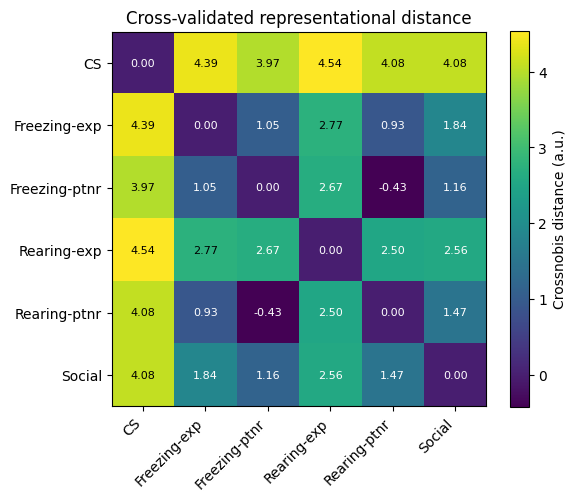

In [45]:
import numpy as np
import matplotlib.pyplot as plt

# nice labels in the order np.unique produced (adjust if your event ids differ)
label_names = ["CS", "Freezing-exp", "Freezing-ptnr",
               "Rearing-exp", "Rearing-ptnr", "Social"]

# squared crossnobis is the analysis quantity; for display take signed sqrt
D_display = np.sign(D2_mean) * np.sqrt(np.abs(D2_mean))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(D_display, cmap="viridis")

ax.set_xticks(range(len(events)), label_names, rotation=45, ha="right")
ax.set_yticks(range(len(events)), label_names)
ax.set_title("Cross-validated representational distance")
fig.colorbar(im, ax=ax, label="Crossnobis distance (a.u.)")

# annotate each cell
for i in range(len(events)):
    for j in range(len(events)):
        ax.text(j, i, f"{D_display[i, j]:.2f}", ha="center", va="center",
                color="white" if D_display[i, j] < D_display.max() * 0.6 else "black",
                fontsize=8)
plt.tight_layout()
plt.show()

In [35]:
from scipy import stats

# one-sample test of each off-diagonal squared distance > 0, across splits
n_ev = len(events)
pvals = np.ones((n_ev, n_ev))
for i in range(n_ev):
    for j in range(n_ev):
        if i != j:
            # one-sided: is the pair discriminable (D2 > 0)?
            t, p = stats.ttest_1samp(D2_all[:, i, j], 0)
            pvals[i, j] = p / 2 if t > 0 else 1.0

In [46]:
import numpy as np
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA

TRIAL_LEN = 100  # rows per trial


def _rdm_from_splits(splits, events, idx, k, shrinkage):
    """Mean crossnobis RDM over splits."""
    n_ev = len(events)
    D2_all = np.full((len(splits), n_ev, n_ev), np.nan)
    for s, (X_tr, y_tr, X_te, y_te) in enumerate(splits):
        if k is not None:
            pca = PCA(n_components=k).fit(X_tr)
            P_tr, P_te = pca.transform(X_tr), pca.transform(X_te)
        else:
            P_tr, P_te = X_tr, X_te
        m_tr = {e: P_tr[y_tr == e].mean(0) for e in events}
        m_te = {e: P_te[y_te == e].mean(0) for e in events}
        resid = np.vstack([P_tr[y_tr == e] - m_tr[e] for e in events])
        Sigma = LedoitWolf().fit(resid).covariance_ if shrinkage else np.cov(resid, rowvar=False)
        Sinv = np.linalg.inv(Sigma)
        for a in events:
            for b in events:
                D2_all[s, idx[a], idx[b]] = (m_tr[a]-m_tr[b]) @ Sinv @ (m_te[a]-m_te[b])
    return np.nanmean(D2_all, axis=0)


def _shuffle_trial_labels(y, rng, trial_len=TRIAL_LEN):
    """
    Permute labels at the trial-block level. y is sorted so each contiguous
    block of `trial_len` rows is one trial. Returns a relabeled copy where
    whole blocks keep their internal rows but get reassigned to shuffled labels.
    """
    n_trials = len(y) // trial_len
    # one label per trial block (first row of each block)
    block_labels = y[::trial_len].copy()
    shuffled = rng.permutation(block_labels)
    # expand back to per-row labels
    return np.repeat(shuffled, trial_len)


def crossnobis_permutation_test(splits, n_perm=1000, k=8, shrinkage=True,
                                trial_len=TRIAL_LEN, rng=0):
    """
    Trial-block permutation null for the crossnobis RDM, using pre-built splits.

    Labels within each split are shuffled at the whole-trial (block of
    `trial_len`) level, consistently for train and test, then the RDM is
    recomputed. The neural data (X) is never touched, so each trial's internal
    structure is preserved — only the event identity assigned to each trial is
    randomized. This is the correct null: 'population activity is unrelated to
    event identity'.

    Returns
    -------
    D2_observed : (n_ev, n_ev) real RDM
    pvals       : (n_ev, n_ev) one-sided P[null >= observed], diagonal = nan
    null_dist   : (n_perm, n_ev, n_ev)
    events
    """
    rng = np.random.default_rng(rng)

    events = np.unique(np.concatenate([np.asarray(y) for _, y, _, _ in splits]))
    idx = {e: i for i, e in enumerate(events)}
    n_ev = len(events)

    # --- observed ---
    D2_observed = _rdm_from_splits(splits, events, idx, k, shrinkage)

    # --- null ---
    null_dist = np.full((n_perm, n_ev, n_ev), np.nan)
    for p in range(n_perm):
        perm_splits = []
        for X_tr, y_tr, X_te, y_te in splits:
            y_tr = np.asarray(y_tr); y_te = np.asarray(y_te)
            perm_splits.append((
                X_tr, _shuffle_trial_labels(y_tr, rng, trial_len),
                X_te, _shuffle_trial_labels(y_te, rng, trial_len),
            ))
        null_dist[p] = _rdm_from_splits(perm_splits, events, idx, k, shrinkage)

    ge = (null_dist >= D2_observed[None, :, :]).sum(axis=0)
    pvals = (ge + 1) / (n_perm + 1)   # Phipson & Smyth unbiased estimator
    np.fill_diagonal(pvals, np.nan)

    return D2_observed, pvals, null_dist, events

In [47]:
splits = list(zip(X_trains[:20], y_trains[:20], X_validations[:20], y_validations[:20]))
D2_observed, pvals, null_dist, events = crossnobis_permutation_test(splits, n_perm=1000, k=20)

In [ ]:
# reports = []
# matrices = []
# matrices_all = []

# for X_train, X_validation, y_train, y_validation in tqdm(zip(X_trains, X_validations, y_trains, y_validations)):

#     mapping = {
#         0: 0, 
#         2: 1, 10: 1, 
#         4: 2, 8: 2, 
#         6: 3,
#         3: 4, 11: 4, 
#         5: 5, 9: 5,
#         7: 6, 
#     }
#     y_train = np.vectorize(mapping.get)(y_train)
#     y_validation = np.vectorize(mapping.get)(y_validation)

#     # unique = np.unique(y_train)
#     # mapping = {v: i for i, v in enumerate(unique)}
#     # y_train = np.vectorize(mapping.get)(y_train)
#     # y_validation = np.vectorize(mapping.get)(y_validation)

#     sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)
#     xgb_clf = XGBClassifier(booster="gblinear",
#                             n_estimators=100,
#                             seed=42,
#                             learning_rate=0.01,
#                             )
    
#     xgb_clf.fit(X_train, 
#                 y_train,
#                 sample_weight=sample_weights,
#                 )
#     y_pred = xgb_clf.predict(X_validation)
    
#     reports.append(classification_report(y_validation, y_pred, output_dict=True, zero_division=0))
#     matrices.append(confusion_matrix(y_validation, y_pred, normalize='true'))
#     matrices_all.append(confusion_matrix(y_validation, y_pred, normalize='pred'))

In [ ]:
dfs = []
for report in reports:
    dfs.append(pd.DataFrame(report))

df = pd.concat(dfs)
df = df.groupby(df.index).mean()

events = [
    '0_experimental_onsets',
    '1_experimental_onsets',
    '2_experimental_onsets',
    '3_experimental_onsets',
    '1_partner_onsets',
    '2_partner_onsets',
]

cols = [*events, "accuracy", "macro avg", "weigthed avg"]
df.columns = cols

matrix = np.mean(np.array(matrices), axis=0)+ 1e-8
matrix_prec = np.mean(np.array(matrices_all), axis=0)+ 1e-8

htmap = pd.DataFrame(np.round(matrix, 3), columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale="RdBu_r",
    zmin=0,
    zmax=1,
    title="<b>Recall</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=15, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
fig.write_image(r"/mnt/Konrad/results/recall_kmeans.svg")

htmap = pd.DataFrame(np.round(matrix_prec, 3), columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale="RdBu_r",
    zmin=0,
    zmax=1,
    title="<b>Precision</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=15, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
fig.write_image(r"/mnt/Konrad/results/precision_kmeans.svg")

matrix_f1 = np.round((2 * (matrix * matrix_prec)) / (matrix + matrix_prec), 3) 
htmap = pd.DataFrame(matrix_f1, columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale="RdBu_r",
    zmin=0,
    zmax=1,
    title="<b>F1-score</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=15, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
fig.write_image(r"/mnt/Konrad/results/f1_kmeans.svg")

In [ ]:
reports = []
matrices = []
matrices_all = []

for X_train, X_validation, y_train, y_validation in tqdm(zip(X_trains, X_validations, y_trains, y_validations)):
    X_train = X_train[np.isin(y_train, [1,3,5,7,9,11])]
    X_validation = X_validation[np.isin(y_validation, [1,3,5,7,9,11])]
    y_train = y_train[np.isin(y_train, [1,3,5,7,9,11])]
    y_validation = y_validation[np.isin(y_validation, [1,3,5,7,9,11])]



    mapping = {

    }
    y_train = np.vectorize(mapping.get)(y_train)
    y_validation = np.vectorize(mapping.get)(y_validation)

    sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)
    xgb_clf = XGBClassifier(booster="gblinear",
                            n_estimators=100,
                            seed=42,
                            learning_rate=0.01,
                            )
    
    xgb_clf.fit(X_train, 
                y_train,
                sample_weight=sample_weights,
                )
    y_pred = xgb_clf.predict(X_validation)
    
    reports.append(classification_report(y_validation, y_pred, output_dict=True, zero_division=0))
    matrices.append(confusion_matrix(y_validation, y_pred, normalize='true'))
    matrices_all.append(confusion_matrix(y_validation, y_pred, normalize='pred'))

In [ ]:
dfs = []
for report in reports:
    dfs.append(pd.DataFrame(report))

df = pd.concat(dfs)
df = df.groupby(df.index).mean()

events = [
    '1_partner_onsets',
    '2_partner_onsets',
    # '3_partner_onsets',
]

cols = [*events, "accuracy", "macro avg", "weigthed avg"]
df.columns = cols

matrix = np.mean(np.array(matrices), axis=0)
matrix_prec = np.mean(np.array(matrices_all), axis=0)


matrix = np.mean(np.array(matrices), axis=0)
htmap = pd.DataFrame(np.round(matrix, 3), columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale="RdBu_r",
    zmin=0,
    zmax=1,
    title="<b>Recall</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=15, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(r"/mnt/Konrad/results/recall_offsets.svg")

matrix_prec = np.mean(np.array(matrices_all), axis=0)
htmap = pd.DataFrame(np.round(matrix_prec, 3), columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale="RdBu_r",
    zmin=0,
    zmax=1,
    title="<b>Precision</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=15, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(r"/mnt/Konrad/results/precision_offsets.svg")

matrix_f1 = np.round((2 * (matrix * matrix_prec)) / (matrix + matrix_prec), 3)
htmap = pd.DataFrame(matrix_f1, columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale="RdBu_r",
    zmin=0,
    zmax=1,
    title="<b>F1-score</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=15, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(r"/mnt/Konrad/results/f1_offsets.svg")

In [ ]:
df = (
    pl.read_csv("/home/pne/Dokumenty/Konrad/SEBA/example_script/vocals.csv")
    .unpivot(
        on=["C21", 'NaCl'], 
        index='Frequency', 
        variable_name="Condition", 
        value_name="# of vocalizations",
    )
)

In [ ]:
df = df.with_columns([
    pl.col("Condition").cast(pl.Enum(["C21", "NaCl"])),
    pl.col("Frequency").cast(pl.Enum(["22kHz", "50kHz"])),
]).sort(["Condition", "Frequency"])


fig = px.box(
    df,
    x="Frequency",
    y="# of vocalizations",
    color="Condition",
    color_discrete_map={
        "C21": "#EF553B",
        "NaCl": "#636EFA", 
    },
    category_orders={
        "Condition": ["C21", "NaCl"],
        "Frequency": ["22kHz", "50kHz"],
    },
    points="all",
    width=500, 
    height=700,
)

fig.update_layout(
    xaxis=dict(
        title="<b>Frequency</b>",
        linewidth=3,
        tickwidth=3,
    ),
    yaxis=dict(
        title="<b># of vocalizations</b>",
        linewidth=3,
        tickwidth=3,
        range=[0, 1200]
    ),
    font=dict(family="Arial", size=20, color="black"),
    template="simple_white",
)
fig.update_traces(line_width=5, marker=dict(size=10))
fig.write_image("/mnt/Konrad/results/vocalizations.svg")

In [4]:
plot_df = (
    pl.read_csv("/mnt/Konrad/PL_ACC_chemo inhibition_freez.csv")
    .with_columns(
        pl.col("CS").str.replace("pre", "Hab"),
        pl.col("Time Spent %").str.replace(",", ".").cast(pl.Float64) * 100
    )
    .group_by("Structure", "Condition", "Animal", "CS", maintain_order=True)
    .agg(
        pl.mean("Time Spent %").alias("mean"), 
        (pl.std("Time Spent %") / pl.len().sqrt()).alias("sem"),
    )
    .with_columns(
        (pl.col("mean") - pl.col("sem")).alias("lower"),
        (pl.col("mean") + pl.col("sem")).alias("upper"),
    )
    .drop("sem")
)

plot_df = plot_df.with_columns(pl.col("Condition").replace({"NaCl": "SAL"}))

In [11]:
filtered = plot_df.filter(pl.col("Animal") == "Experimental")

for structure in ["PL", "ACC"]:
    fig = go.Figure()
    struct_df = filtered.filter(pl.col("Structure") == structure)

    for (i, condition), color in zip(enumerate(["C21", "SAL"]), ["#EF553B", "#636EFA"]):
        cond_df = struct_df.filter(pl.col("Condition") == condition)
        x = cond_df["CS"].to_list()
        y = cond_df["mean"].to_list()
        lower = cond_df["lower"].to_list()
        upper = cond_df["upper"].to_list()

        fig.add_trace(go.Scatter(
            x=x + x[::-1],
            y=upper + lower[::-1],
            fill="toself",
            fillcolor=color,
            line=dict(color="rgba(0,0,0,0)", shape="spline"),
            opacity=0.2,
            showlegend=False,
        ))
        fig.add_trace(go.Scatter(
            x=x,
            y=y,
            mode="lines",
            name=condition,
            line=dict(color=color, shape="spline", width=5),
        ))

    fig.update_layout(
        title=f"<b>{structure}</b>", 
        xaxis=dict(
            title="<b>Trial #</b>",
            tickvals=["Hab", 5, 10, 15], 
            ticktext=["Hab", "5", "10", "15"],
            linewidth=3,
            tickwidth=3,
        ),
        yaxis=dict(
            title="<b>Time Spent %</b>",
            tickvals=[25, 50, 75, 100], 
            ticktext=["25", "50", "75", "100"],
            range=[0, 100],
            linewidth=3,
            tickwidth=3,
        ), 
        template="simple_white", 
        font=dict(family="Arial", size=20, color="black"),
        width=800,
        showlegend=False
    )
    fig.show()
    fig.write_image(f"/mnt/Konrad/results/{structure}_freezing_Experimental.svg")

In [ ]:
plot_df = (
    pl.read_csv("/mnt/Konrad/new/PL_ACC_chemo inhibition_freez.csv")
    .with_columns(
        pl.col("CS").str.replace("pre", "Hab"),
        pl.col("Time Spent %").str.replace(",", ".").cast(pl.Float64) * 100
    )
    .group_by("Condition", "Animal", "CS", maintain_order=True)
    .agg(
        pl.mean("Time Spent %").alias("mean"), 
        (pl.std("Time Spent %") / pl.len().sqrt()).alias("sem"),
    )
    .with_columns(
        (pl.col("mean") - pl.col("sem")).alias("lower"),
        (pl.col("mean") + pl.col("sem")).alias("upper"),
    )
    .drop("sem")
)

for condition in ["C21", "NaCl"]:
    fig = go.Figure()
    cond_df = plot_df.filter(pl.col("Condition") == condition)
    for (i, animal), color in zip(enumerate(["Experimental", "Partner"]), ["#EF553B", "#636EFA"]):
        animal_df = cond_df.filter(pl.col("Animal") == animal)
        x = animal_df["CS"].to_list()
        y = animal_df["mean"].to_list()
        lower = animal_df["lower"].to_list()
        upper = animal_df["upper"].to_list()

        fig.add_trace(go.Scatter(
            x=x + x[::-1],
            y=upper + lower[::-1],
            fill="toself",
            fillcolor=color,
            line=dict(color="rgba(0,0,0,0)", shape="spline"),
            opacity=0.2,
            showlegend=False,
        ))
        fig.add_trace(go.Scatter(
            x=x,
            y=y,
            mode="lines",
            name=animal,
            line=dict(color=color, shape="spline", width=5),
        ))

    fig.update_layout(
        title=f"<b>{condition}</b>", 
        xaxis=dict(
            title=f"<b>Trial #</b>", 
            tickvals=["Hab", 5, 10, 15], 
            ticktext=["Hab", "5", "10", "15"],
            linewidth=3,
            tickwidth=3,
        ),
        yaxis=dict(
            title="<b>Time Spent %</b>",
            tickvals=[25, 50, 75, 100], 
            ticktext=["25", "50", "75", "100"],
            range=[0, 100],
            linewidth=3,
            tickwidth=3,
        ), 
        template="simple_white", 
        font=dict(family="Arial", size=20, color="black"),
        width=800,
        showlegend=False,
    )
    fig.show()
    fig.write_image(f"/mnt/Konrad/results/{condition}_freezing.svg")

In [ ]:
import numpy as np
from scipy import stats

raw_df = (
    pl.read_csv("/mnt/Konrad/new/PL_ACC_chemo inhibition_freez.csv")
    .with_columns(
        pl.col("CS").str.replace("pre", "Hab"),
        pl.col("Time Spent %").str.replace(",", ".").cast(pl.Float64) * 100
    )
    .filter(pl.col("CS") != "Hab")
    .with_row_index("_idx")
    .with_columns(
        pl.struct("Structure", "Pair")
          .rank("dense")
          .over("Condition")
          .alias("Pair")
    )
    .drop("_idx")
)

corr_raw = raw_df.pivot(on="Animal", index=["Condition", "Pair", "CS"], values="Time Spent %")

results_df = (
    corr_raw
    .group_by("Condition", "Pair", maintain_order=True)
    .agg(pl.corr("Experimental", "Partner", method="pearson").alias("r"))
    .sort("Condition", "Pair")
)
print(results_df)

# Fisher z-test
z_c21  = np.arctanh(results_df.filter(pl.col("Condition") == "C21")["r"].to_numpy())
z_nacl = np.arctanh(results_df.filter(pl.col("Condition") == "NaCl")["r"].to_numpy())
t, p = stats.ttest_ind(z_c21, z_nacl)

for condition, z in [("C21", z_c21), ("NaCl", z_nacl)]:
    print(f"{condition}: mean r={np.tanh(np.mean(z)):.3f}")
print(f"\nt-test on Fisher z: t={t:.3f}, p={p:.3f}")


In [ ]:
fig = px.box(
    results_df, 
    x="Condition",
    y="r", 
    color="Condition",
    color_discrete_map={
        "C21": "#EF553B",
        "NaCl": "#636EFA",
    },
    points="all", 
    width=500, 
    height=700,
    range_y=[-1, 1],
)

fig.update_layout(
    xaxis=dict(
        title="",
        linewidth=3,
        tickwidth=3,
    ),
    yaxis=dict(
        title="<b>Pearson Correlation Coeff</b>",
        linewidth=3,
        tickwidth=3,
    ), 
    template="simple_white", 
    font=dict(family="Arial", size=20, color="black"),
)

fig.update_traces(
    marker=dict(size=5),
    line=dict(width=5)
)
fig.show()
fig.write_image(f"/mnt/Konrad/results/correlation.svg")

In [ ]:
names = ["NP2", "NP3", "NP4", "NP7", "NP8","NP9"]

dfs = []

for name in names:
    features = (
        pl.DataFrame(datasets[name]['df'])
        .filter(pl.col('event_name').is_in(["rearing_ephys_onsets", "rearing_non_ephys_onsets"]))
        .select(pl.all().exclude("event_class", "timestamp", "event_name", "event_trial"))
    )

    sample_n = list(range(1,201)) * (len(features) // 200)

    class_trial = (
        pl.DataFrame(datasets[name]['df'])
        .select("event_name", "event_trial")
        .filter(pl.col('event_name').is_in(["rearing_ephys_onsets", "rearing_non_ephys_onsets"]))
        .with_columns(
            pl.lit(name).alias("rec_name"), 
            pl.Series(sample_n).alias("sample_n")
        )
    )
    pca = PCA(3, whiten=True, svd_solver="full")
    pca_res = pl.DataFrame(pca.fit_transform(features), schema=[f"PC{i}" for i in range(1, 4)])
    dfs.append(pl.concat([pca_res, class_trial], how='horizontal'))

In [ ]:
for i in range(6):

    fig_3comps = px.line_3d(
        dfs[i].group_by("event_name", "sample_n", maintain_order=True).agg(cs.float().mean()).with_columns(pl.col("event_name").replace({
            "rearing_ephys_onsets": "Rearing-Experimental",
            "rearing_non_ephys_onsets": "Rearing-Partner",
        })), 
        x="PC1", 
        y="PC2", 
        z="PC3", 
        color="event_name", 
        color_discrete_map={
            "Rearing-Experimental": "#AB63FA",
            "Rearing-Partner": "#FFA15A",
        },
        title=f"<b>Pair {i+1}</b>",
    )

    fig_3comps.update_traces(line_width=9)
    fig_3comps.update_layout(
        width=1200,
        height=1200,
        scene_camera=dict(eye=dict(x=2, y=2, z=2)),
        font=dict(family="Arial", size=16, color="black"),
        scene=dict(
            xaxis=dict(title="<b>PC1</b>", tickfont=dict(size=16, family="Arial", color="black")),
            yaxis=dict(title="<b>PC2</b>", tickfont=dict(size=16, family="Arial", color="black")),
            zaxis=dict(title="<b>PC3</b>", tickfont=dict(size=16, family="Arial", color="black")),
        ),
        legend=dict(title="Event"),
        template="plotly_white"
    )
    fig_3comps.show()
    fig_3comps.write_image(f"/mnt/Konrad/results/pair_rear_{i+1}_time.svg")

In [ ]:
plot_df = (
    dfs[0]
    .group_by("event_name", "sample_n", maintain_order=True)
    .agg(cs.float().mean())
    .with_columns(
        pl.col("sample_n").cast(pl.Float64).replace(
            {i: j for i, j in zip(range(1, 201), np.linspace(-1, 1, 200).round(2))}
        )
    )
)

fig_time = px.line_3d(
    plot_df, 
    x="PC1", 
    y="PC2", 
    z="sample_n", 
    color="event_name", 
    color_discrete_map={
        "freezing_ephys_onsets": "#EF553B",
        "freezing_non_ephys_onsets": "#00CC96",
    },
    title="<b>Pair 1</b>",
)

fig_time.update_traces(line_width=9)
fig_time.update_layout(
    width=1200,
    height=1200,
    scene_camera=dict(eye=dict(x=1, y=2, z=1)),
    font=dict(family="Arial", size=16, color="black"),
    scene=dict(
        xaxis=dict(title="<b>PC1</b>", tickfont=dict(size=16, family="Arial", color="black")),
        yaxis=dict(title="<b>PC2</b>", tickfont=dict(size=16, family="Arial", color="black")),
        zaxis=dict(title="<b>Time</b>", tickfont=dict(size=16, family="Arial", color="black")),
    ),
    template="plotly_white"
)

fig_time.write_image("/mnt/Konrad/results/pair_1_time.svg")

In [ ]:
plot_df = (
    pl.concat(dfs)
    .group_by("rec_name", "event_name", "sample_n", maintain_order=True)
    .agg(pl.mean("PC1"), pl.mean("PC2"), pl.mean("PC3"))
    .filter(pl.col('event_name').is_in(['rearing_ephys_onsets', 'rearing_non_ephys_onsets']))
)

colors = {e: c for e, c in zip(plot_df["event_name"].unique().to_list(), px.colors.qualitative.Plotly)}
n_cols = 3
n_rows = -(-len(names) // n_cols)

fig = make_subplots(
    rows=n_rows, cols=n_cols,
    specs=[[{"type": "scene"} for _ in range(n_cols)] for _ in range(n_rows)],
    subplot_titles=names,
    horizontal_spacing=0.04,
    vertical_spacing=0.1,
)

seen = set()
for i, rec in enumerate(names):
    row, col = divmod(i, n_cols)
    scene_id = f"scene{i+1 if i > 0 else ''}"
    rdf = plot_df.filter(pl.col("rec_name") == rec)
    for event in rdf["event_name"].unique().to_list():
        edf = rdf.filter(pl.col("event_name") == event).sort("sample_n")
        show_legend = event not in seen
        seen.add(event)
        fig.add_trace(go.Scatter3d(
            x=edf["PC1"], y=edf["PC2"], z=edf["PC3"],
            mode="lines", name=event,
            line=dict(color=colors[event], width=6),
            legendgroup=event, showlegend=show_legend,
        ), row=row+1, col=col+1)
    fig.update_layout(template="plotly_white", **{scene_id: dict(
        aspectmode="cube",
    )})

fig.update_annotations(font=dict(size=14, family="Arial", color="black"))
fig.update_layout(
    width=400 * n_cols,
    height=400 * n_rows,
    margin=dict(l=15, r=15, t=60, b=15),
    font=dict(family="Arial", size=12, color="black"),
    legend=dict(font=dict(size=12, family="Arial"), itemsizing="constant", tracegroupgap=4),
    paper_bgcolor="white",
    template="plotly_white"
)
fig.show()



In [ ]:
pca_res

In [328]:
x = np.concatenate([X_trains[0], X_validations[0]])
y = np.concatenate([y_trains[0], y_validations[0]])

x = (x - np.mean(x)) / np.std(x)

In [7]:
import umap

/home/pne/Dokumenty/Konrad/SEBA/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [61]:
# reducing to mean first to avoid issue with varaibility during trial
X_mean = X_trains[0].groupby(X_trains[0].index // 100).mean()
y_mean = (
    pd.DataFrame(y_trains[0])
    .groupby(X_trains[0].index // 100)
    .mean()
    .astype(int)
    .values.ravel()
)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=3, random_state=42)
embedding = reducer.fit_transform(X_mean)

df_umap = pd.DataFrame(embedding, columns=["UMAP_1", "UMAP_2", "UMAP_3"])
df_umap["target"] = y_mean.astype(str)
df_umap["target"] = (
    df_umap["target"]
    .astype("str")
    .replace({str(i): event for i, event in zip(range(6), all_events)})
)

fig_2d = px.scatter(
    df_umap,
    x="UMAP_1",
    y="UMAP_2",
    color="target",
    title="UMAP 2D Projection (Unsupervised)",
    template="plotly_white",
    width=800,
    height=600,
)
fig_2d.update_traces(marker=dict(size=10))
fig_2d.show()

fig_3d = px.scatter_3d(
    df_umap,
    x="UMAP_1",
    y="UMAP_2",
    z="UMAP_3",
    color="target",
    title="UMAP 3D Projection (Unsupervised)",
    opacity=0.7,
    width=900,
    height=700,
)
fig_3d.show()

/home/pne/Dokumenty/Konrad/SEBA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [16]:
plot_df

PC0,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,…,PC300,PC301,PC302,PC303,PC304,PC305,PC306,PC307,PC308,PC309,PC310,PC311,PC312,PC313,PC314,PC315,PC316,PC317,PC318,PC319,PC320,PC321,PC322,PC323,PC324,PC325,PC326,PC327,PC328,PC329,PC330,PC331,PC332,PC333,PC334,PC335,PC336
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
-0.729344,1.054248,-0.881335,-0.856863,-0.067232,-0.413976,-0.671456,-1.309081,0.939789,0.607371,-0.162786,-0.260757,0.598366,1.193603,-0.365124,0.763339,-0.700347,0.826524,0.208147,-0.572835,-0.612107,-0.578653,1.105335,0.138263,0.5843,-0.275295,-0.436127,-0.321622,-0.930249,-0.717893,0.252312,0.216138,-0.842126,-1.408716,-0.794354,0.463353,0.207148,…,0.503955,0.372773,-0.608517,-0.868719,0.465401,0.203563,0.241264,0.876927,-0.288353,0.4354,-0.224973,0.438751,-0.147803,-0.297351,-0.22915,-0.017403,-1.458654,-0.288733,-0.099363,-0.320709,0.632713,0.554885,-0.410198,-0.50106,-0.215848,-0.063529,-0.287074,-0.207537,-0.224718,0.104661,-0.439749,1.031567,-0.561715,-0.102377,0.666143,0.125285,-0.800112
-0.722498,1.358255,-1.043695,-0.773838,0.025982,-0.415867,-0.812601,-1.342077,1.055626,0.581111,-0.180223,-0.128779,0.445053,1.152522,-0.456665,0.832352,-0.696217,0.958448,0.283835,-0.733257,-0.622963,-0.63854,1.198474,0.26671,0.632514,-0.340923,-0.245574,-0.357726,-1.002161,-0.703124,0.273759,0.26908,-0.841836,-1.442617,-0.878904,0.514458,0.202206,…,0.537347,0.295877,-0.56651,-0.93852,0.49051,0.267532,0.225236,0.93987,-0.229971,0.452028,-0.301943,0.420889,-0.208933,-0.234489,-0.138637,0.136369,-1.431305,-0.291679,-0.123756,-0.343919,0.611833,0.530449,-0.215161,-0.461784,-0.15587,-0.114918,-0.13047,-0.228899,-0.228606,0.179526,-0.404194,1.055621,-0.464108,-0.322216,0.689565,0.11715,-0.694038
-0.713927,1.610048,-1.221769,-0.687815,0.109475,-0.419956,-0.95506,-1.356952,1.150428,0.543426,-0.203456,0.022338,0.274878,1.096084,-0.534833,0.930465,-0.705169,1.108225,0.34662,-0.888962,-0.650714,-0.650613,1.32056,0.400018,0.657876,-0.41942,-0.06572,-0.387566,-1.071223,-0.678221,0.27852,0.328643,-0.817058,-1.481893,-0.943604,0.549142,0.19925,…,0.573255,0.213644,-0.515101,-0.982752,0.501342,0.338619,0.203882,0.969715,-0.188486,0.470643,-0.392748,0.387859,-0.238464,-0.169898,-0.04388,0.277032,-1.371457,-0.308168,-0.148949,-0.338233,0.570053,0.50645,-0.023679,-0.435181,-0.096821,-0.178553,0.04307,-0.209857,-0.204064,0.226107,-0.360654,1.041494,-0.350206,-0.524158,0.701551,0.137754,-0.594433
-0.704291,1.782139,-1.404248,-0.602978,0.18238,-0.424057,-1.090766,-1.353165,1.227926,0.499482,-0.238857,0.178575,0.096471,1.027463,-0.599297,1.048465,-0.719444,1.270236,0.3877,-1.031492,-0.690588,-0.615792,1.476127,0.540022,0.662395,-0.497312,0.095552,-0.404988,-1.138649,-0.644107,0.265886,0.392737,-0.761814,-1.532253,-0.987277,0.565302,0.201681,…,0.606591,0.123877,-0.456352,-0.996994,0.498616,0.413247,0.164563,0.966032,-0.159405,0.485654,-0.485119,0.344966,-0.235084,-0.107284,0.048388,0.397408,-1.285073,-0.334183,-0.17491,-0.30167,0.509044,0.477032,0.151976,-0.431019,-0.043172,-0.249447,0.229553,-0.153683,-0.149979,0.242077,-0.309657,0.984506,-0.226696,-0.694337,0.701221,0.189309,-0.504616
-0.694248,1.854956,-1.579299,-0.521889,0.245536,-0.42704,-1.213072,-1.332802,1.293972,0.455526,-0.290135,0.324444,-0.08047,0.950921,-0.650664,1.173536,-0.730342,1.435047,0.399753,-1.152768,-0.737981,-0.53925,1.666392,0.689203,0.649912,-0.559108,0.233389,-0.405681,-1.204424,-0.602446,0.236069,0.460563,-0.671401,-1.597503,-1.010649,0.562478,0.212826,…,0.633315,0.02515,-0.393886,-0.979583,0.48303,0.488083,0.094908,0.930081,-0.135211,0.491474,-0.566463,0.2989,-0.200952,-0.047392,0.132098,0.4921

In [22]:
plot_df

Event,Time,PC0,PC1,PC2
str,f64,f64,f64,f64
"""CS""",-1.0,-0.23534,-0.791092,-0.400083
"""CS""",-0.979798,-0.19356,-0.878575,-0.413251
"""CS""",-0.959596,-0.155688,-0.973966,-0.425914
"""CS""",-0.939394,-0.125537,-1.072824,-0.438933
"""CS""",-0.919192,-0.105948,-1.169869,-0.452941
…,…,…,…,…
"""Social interaction""",0.919192,-0.595846,-0.555626,0.500935
"""Social interaction""",0.939394,-0.526925,-0.561787,0.458087
"""Social interaction""",0.959596,-0.461988,-0.565498,0.40882


In [ ]:
x = np.concatenate([X_trains[0], X_validations[0]])
y = np.concatenate([y_trains[0], y_validations[0]])

x = (x - np.mean(x)) / np.std(x)

n_components = 20

pca = PCA(n_components, whiten=False, svd_solver="full", random_state=42)
pca_res = pca.fit_transform(x)
plot_df = pl.DataFrame(pca_res, schema = {f"PC{i+1}": pl.Float64 for i in range(n_components)})
print(sum(pca.explained_variance_ratio_))

names = ["CS", "Freezing-experimental", "Freezing-partner", "Rearing-experimental", "Rearing-partner", "Social interaction"]

plot_df = (
    plot_df.with_columns(
        pl.Series(list(np.linspace(-1, 1, 100)) * int(len(plot_df) / 100)).alias("Time"),
        pl.Series(y)
        .cast(pl.String())
        .replace({str(i): event for i, event in enumerate(names)})
        .alias("Event"),
    )
    .group_by("Event", "Time", maintain_order=True)
    .agg(pl.all().mean())
)

fig = px.line_3d(plot_df, x="PC1", y="PC2", z="PC3", color="Event", width=800, height=700)
fig.update_layout(
    scene_camera=dict(eye=dict(x=1.8, y=1.8, z=1.8)),
    font=dict(family="Arial", size=12, color="black"),
    template="plotly_white",
)
fig.update_traces(line_width=5)
fig.write_image("/mnt/Konrad/results/pca_time_new.svg")
fig.show()

fig = px.line(plot_df, x="PC1", y="PC2", color="Event", width=800, height=700, template='simple_white', color_discrete_sequence=px.colors.qualitative.Plotly)
# fig.update_traces(line_width=4).write_image("/mnt/Konrad/results/pca2d_new.svg")

n_max = 50

pca_elbow = PCA(n_max, whiten=False, svd_solver="full", random_state=42)
pca_elbow.fit(x)

elbow_df = pl.DataFrame({
    "Component": list(range(1, n_max + 1)),
    "Explained variance": pca_elbow.explained_variance_ratio_,
    "Cumulative": np.cumsum(pca_elbow.explained_variance_ratio_),
})

components = list(range(1, n_max + 1))
evr = pca_elbow.explained_variance_ratio_
cum = np.cumsum(evr)


fig = make_subplots(specs=[[{"secondary_y": True}]])

fig.add_trace(
    go.Bar(
        x=components,
        y=cum,
        name="Cumulative",
        marker_color="lightslategray",
        zorder=0,
    ),
    secondary_y=True,
)

fig.add_trace(
    go.Scatter(
        x=components,
        y=evr,
        mode="lines+markers",
        name="Explained variance",
        line=dict(width=3),
        zorder=10,
        fillcolor='#636EFA',
    ),
    secondary_y=False,
)

fig.update_layout(
    width=800,
    height=500,
    template="plotly_white",
    font=dict(family="Arial", size=12, color="black"),
    legend=dict(x=0.6, y=0.9),
    title='<b>Explained variance across used N of components</b>',
)
fig.update_xaxes(title_text="<b>Number of components</b>")
fig.update_yaxes(title_text="<b>Cumulative explained variance</b>", secondary_y=True, range=[0, 1])
fig.update_yaxes(title_text="<b>Explained variance ratio</b>", secondary_y=False, range=[0, 0.06])

fig.write_image("/mnt/Konrad/results/pca_elbow.svg")
fig.show()

0.3624720829977964


In [ ]:
import numpy as np
from sklearn.decomposition import PCA

def crossnobis_rdm(splits, k=15, shrinkage=True):
    """
    Cross-validated (crossnobis) squared Mahalanobis RDM, averaged over splits.

    Parameters
    ----------
    splits : list of (X_train, y_train, X_test, y_test)
        Your 100 prepared sets. Each split must contain ALL events in both
        train and test (stratify when you build them).
    k : int
        Number of PCs (fit on training data only, per split).
    shrinkage : bool
        Use Ledoit-Wolf shrinkage for Sigma instead of plain np.cov.
        Recommended — keeps Sigma well-conditioned when k is not tiny.

    Returns
    -------
    D2_mean : (n_events, n_events) array
        Mean cross-validated squared distance. Diagonal ~0; off-diagonal
        can be slightly negative for indistinguishable pairs.
    events : array of event labels (consistent ordering across splits)
    D2_all : (n_splits, n_events, n_events) array, per-split estimates
             (useful for error bars / significance testing).
    """
    # fix a global, consistent event ordering across all splits
    events = np.unique(np.concatenate([s[1] for s in splits]))
    n_ev = len(events)
    idx = {e: i for i, e in enumerate(events)}

    if shrinkage:
        from sklearn.covariance import LedoitWolf

    D2_all = np.full((len(splits), n_ev, n_ev), np.nan)

    for s_i, (Xtr, ytr, Xte, yte) in enumerate(splits):
        ytr = np.asarray(ytr); yte = np.asarray(yte)

        # PCA fit on TRAIN only, then apply same projection to TEST
        pca = PCA(n_components=k).fit(Xtr)
        Ptr = pca.transform(Xtr)
        Pte = pca.transform(Xte)

        # event means in each fold (must exist in both)
        mtr = {e: Ptr[ytr == e].mean(0) for e in events}
        mte = {e: Pte[yte == e].mean(0) for e in events}

        # pooled within-event noise covariance from TRAIN residuals
        resid = np.vstack([Ptr[ytr == e] - mtr[e] for e in events])
        if shrinkage:
            Sigma = LedoitWolf().fit(resid).covariance_
        else:
            Sigma = np.cov(resid, rowvar=False)
        Sinv = np.linalg.inv(Sigma)

        # crossnobis: difference on train fold, whitened diff on test fold
        for a in events:
            for b in events:
                d_tr = mtr[a] - mtr[b]
                d_te = mte[a] - mte[b]
                D2_all[s_i, idx[a], idx[b]] = d_tr @ Sinv @ d_te

    D2_mean = np.nanmean(D2_all, axis=0)
    return D2_mean, events, D2_all

In [36]:
event_mahalanobis(x, y)[0],

(array([[0.        , 4.26493618, 4.21792579, 4.2135854 , 4.27983925,
         4.38868584],
        [4.26493618, 0.        , 1.00549606, 1.32014696, 1.06657986,
         1.02590473],
        [4.21792579, 1.00549606, 0.        , 1.64954235, 0.73285676,
         1.34915255],
        [4.2135854 , 1.32014696, 1.64954235, 0.        , 1.74000756,
         1.30929824],
        [4.27983925, 1.06657986, 0.73285676, 1.74000756, 0.        ,
         1.35889223],
        [4.38868584, 1.02590473, 1.34915255, 1.30929824, 1.35889223,
         0.        ]]),)

In [35]:
px.imshow(event_mahalanobis(x, y)[0], text_auto=True)

In [ ]:
classes = pl.Series(y).cast(pl.String).replace({
    i: name for i, name in zip(range(6), names)
}).to_numpy()

In [ ]:
from itertools import combinations

import numpy as np
import pandas as pd


def permanova_euclidean(X, y, n_perm=999, rng=None):
    """
    PERMANOVA with Euclidean distances, computed via SS decomposition
    (equivalent to skbio.permanova but O(N*p) per permutation instead of O(N^2)).
    """
    rng = np.random.default_rng(rng)
    X = np.asarray(X, dtype=np.float64)
    y = np.asarray(y)
    N, _ = X.shape
    groups = np.unique(y)
    a = len(groups)

    def pseudo_F(labels):
        grand = X.mean(axis=0)
        ss_total = ((X - grand) ** 2).sum()
        ss_within = 0.0
        for g in groups:
            Xg = X[labels == g]
            ss_within += ((Xg - Xg.mean(axis=0)) ** 2).sum()
        ss_between = ss_total - ss_within
        return (ss_between / (a - 1)) / (ss_within / (N - a))

    F_obs = pseudo_F(y)
    count = 1  # +1 for the observed value (standard PERMANOVA convention)
    labels = y.copy()
    for _ in range(n_perm):
        rng.shuffle(labels)
        if pseudo_F(labels) >= F_obs:
            count += 1
    p = count / (n_perm + 1)
    return {"pseudo_F": F_obs, "p": p, "n_perm": n_perm, "groups": a, "N": N}

# ---- omnibus test ----
res = permanova_euclidean(pca_res, classes, n_perm=999, rng=0)
print(res)

# ---- pairwise tests with Bonferroni ----
unique_classes = np.unique(classes)
pairs = list(combinations(unique_classes, 2))
n_tests = len(pairs)

rows = []
for a, b in tqdm(pairs):
    mask = (classes == a) | (classes == b)
    r = permanova_euclidean(pca_res[mask], classes[mask], n_perm=999, rng=0)
    rows.append({
        "class_A": a, "class_B": b,
        "pseudo_F": r["pseudo_F"],
        "p": r["p"],
        "p_bonf": min(r["p"] * n_tests, 1.0),
    })

pairwise = pd.DataFrame(rows).sort_values("p").reset_index(drop=True)
pairwise["significant"] = pairwise["p_bonf"] < 0.05
print(pairwise.to_string(index=False))


In [ ]:
X_train = pca_res[:len(y_trains[0])]
X_validation = pca_res[len(y_trains[0]):]

In [ ]:
X_train = pca_res[:len(y_trains[0])]
X_validation = pca_res[len(y_trains[0]):]

sample_weights = compute_sample_weight(class_weight='balanced', y=y_trains[0])
xgb_clf = XGBClassifier(booster="gblinear",
                        n_estimators=100,
                        seed=42,
                        learning_rate=0.01,
                        )

xgb_clf.fit(X_train, 
            y_trains[0],
            sample_weight=sample_weights,
            )
y_pred = xgb_clf.predict(X_validation)

report = classification_report(y_validations[0], y_pred, output_dict=True, zero_division=0)
matrice = confusion_matrix(y_validations[0], y_pred, normalize='true')
matrices_al = confusion_matrix(y_validations[0], y_pred, normalize='pred')

### PCA

In [93]:
_pca = pd.concat([X_trains[5], X_validations[5]])
event_class = np.concatenate([y_trains[5], y_validations[5]])

# _pca = _pca.subtract(_pca.mean(), axis=1).div(_pca.std(), axis=1) # zscore

pca = PCA(150, whiten=True, svd_solver="full")
pca_res = pca.fit_transform(_pca)
plot_df = pl.DataFrame(pca_res, schema = {f"PC{i}": pl.Float64 for i in range(1, 151)})
# print(pca.explained_variance_ratio_)

names = ["CS", "Freezing-experimental", "Freezing-partner", "Rearing-experimental", "Rearing-partner", "Social interaction"]

plot_df = (
    plot_df.with_columns(
        pl.Series(list(np.linspace(-0.5, 1, 150)) * 166).alias("Time"),
        pl.Series(event_class)
        .cast(pl.String())
        .replace({str(i): event for i, event in enumerate(names)})
        .alias("Event"),
    )
    .group_by("Event", "Time", maintain_order=True)
    .agg(pl.all().mean())
)

In [173]:
pairs = [
    ['Freezing-experimental', 'Freezing-partner'],
    ['Freezing-experimental', 'Rearing-experimental'],
    ['Rearing-experimental', 'Rearing-partner'],
    ['Freezing-experimental', 'Rearing-partner'],
]

In [ ]:
distances = []
cosines = []
for i in range(3, 100):
    for e1, e2 in pairs:
        if e1 == 'Freezing-experimental' and e2 == 'Freezing-partner':
            A = (
                plot_df.filter(pl.col("Event") == e1)
                .select([f"PC{i + 1}" for i in range(i)])
                .to_numpy()
            )
            B = (
                plot_df.filter(pl.col("Event") == e2)
                .select([f"PC{i + 1}" for i in range(i)])
                .to_numpy()
            )
            distance = np.linalg.norm(A - B)

            A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
            B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

            cos_sim = np.sum(A_norm * B_norm, axis=1)
            distances.append(distance)
            cosines.append(cosines)
            
            print(e1, e2, distance, cos_sim.mean())
            # divergence = np.linalg.norm(A - B, axis=1)
            # print(divergence)

In [103]:
fig = px.line_3d(plot_df, x='PC1', y='PC2', z='PC3', color='Event', hover_data='Time', width=800, height=800, template='plotly_white')
camera = dict(
    up=dict(x=0, y=0, z=1),
    center=dict(x=0, y=0, z=0),
    eye=dict(x=1.7, y=1.7, z=1.7)
)

fig.update_layout(font=dict(
    family='Arial',
    size=15,
), scene_camera=camera, showlegend=False)
fig.update_traces(line=dict(width=12))

In [ ]:
n_splits = 50

all_data = pd.concat(X_trains[:50] + X_validations[:50])
pca = PCA(20, whiten=True, svd_solver="full")
pca.fit(all_data)
split_dfs = []
for i in tqdm(range(n_splits), total=n_splits):
    _pca = pd.concat([X_trains[i], X_validations[i]])
    pca_res = pca.transform(_pca)  # same axes for all splits

    split_df = (
        pl.DataFrame(pca_res, schema={f"PC{j}": pl.Float64 for j in range(1, 21)})
        .with_columns(
            pl.Series(list(np.linspace(-1, 1, 200)) * (len(_pca) // 200)).alias("Time"),
            pl.Series(events)
            .cast(pl.String())
            .replace({str(j): event for j, event in enumerate(names)})
            .alias("Event"),
            pl.lit(i).alias("split"),
        )
        .group_by("Event", "Time", maintain_order=True)
        .agg(pl.all().mean())
    )
    split_dfs.append(split_df)

plot_df = (
    pl.concat(split_dfs)
    .group_by("Event", "Time", maintain_order=True)
    .agg(pl.all().exclude("split").mean())
    .sort("Event", "Time")
)


In [ ]:
fig = px.line_3d(
    plot_df,
    x="PC1",
    y="PC2",
    z="PC3",
    color="Event",
    template="plotly_white",
    width=1000,
    height=1200,
)
fig.update_traces(line_width=7)
fig.update_layout(
    scene_camera=dict(eye=dict(x=2, y=2, z=2)),
    font=dict(family="Arial", size=16, color="black"),
    scene=dict(
        xaxis=dict(title="<b>PC1</b>", tickfont=dict(size=16, family="Arial", color="black")),
        yaxis=dict(title="<b>PC2</b>", tickfont=dict(size=16, family="Arial", color="black")),
        zaxis=dict(title="<b>PC3</b>", tickfont=dict(size=16, family="Arial", color="black")),
    ),
)
# fig.write_image(r"./components_3.svg")
fig.show()

fig = px.line_3d(
    plot_df,
    x="PC1",
    y="PC2",
    z="Time",
    color="Event",
    template="plotly_white",
    width=1000,
    height=1200,
)
fig.update_traces(line_width=7)
fig.update_layout(
    scene_camera=dict(eye=dict(x=2, y=2, z=2)),
    font=dict(family="Arial", size=16, color="black"),
    scene=dict(
        xaxis=dict(title="<b>PC1</b>", tickfont=dict(size=16, family="Arial", color="black")),
        yaxis=dict(title="<b>PC2</b>", tickfont=dict(size=16, family="Arial", color="black")),
        zaxis=dict(title="<b>Time</b>", tickfont=dict(size=16, family="Arial", color="black")),
    ),
)
# fig.write_image(r"./components_over_time.svg")
fig.show()

In [ ]:
from dPCA import dPCA as dPCA_module

_data = pd.concat([X_trains[12], X_validations[12]])
event_class = np.concatenate([y_trains[12], y_validations[12]])

n_neurons = _data.shape[1]
n_time = 100
n_conditions = 6
names = ["CS", "Freezing-experimental", "Freezing-partner", "Rearing-experimental", "Rearing-partner", "Social interaction"]

# Assign trial index within each condition
data_arr = _data.values  # (n_total_timepoints, n_neurons)
n_total = len(data_arr) // n_time

# Reshape to (n_trials, n_time, n_neurons)
data_trials = data_arr.reshape(n_total, n_time, n_neurons)
labels = event_class.reshape(n_total, n_time)[:, 0].astype(int)  # one label per trial

n_trials_per_cond = min(np.bincount(labels))  # use minimum for balanced tensor

# Build tensors
tensor = np.zeros((n_neurons, n_conditions, n_time))
trialR = np.zeros((n_neurons, n_conditions, n_trials_per_cond, n_time))

for c in range(n_conditions):
    idx = np.where(labels == c)[0][:n_trials_per_cond]
    tensor[:, c, :] = data_trials[idx].mean(axis=0).T  # (n_neurons, n_time)
    for t, i in enumerate(idx):
        trialR[:, c, t, :] = data_trials[i].T

dpca = dPCA_module.dPCA(labels="ct", n_components=5, regularizer=1e-6)
dpca.protect = ["t"]
Z = dpca.fit_transform(tensor)
# Z["t"]  → time components  (n_components, n_conditions, n_time)
# Z["c"]  → condition components
# Z["ct"] → interaction components

# Build plot_df equivalent
records = []
time_axis = np.linspace(-1, 1, n_time)
for c, name in enumerate(names):
    for t_i, t in enumerate(time_axis):
        records.append({
            "Event": name,
            "Time": t,
            "dPC_t1":  Z["t"][0, c, t_i],
            "dPC_c1":  Z["c"][0, c, t_i],
            "dPC_ct1": Z["ct"][0, c, t_i],
        })

plot_df = pl.DataFrame(records)

In [ ]:
sum(pca.explained_variance_ratio_[:15])

In [ ]:
np.round(np.sort(np.abs(pca.components_))[5][::-1], 2)

In [ ]:
px.line(plot_df, x="Time", y="dPC_ct1", color="Event")

In [ ]:
fig = px.line_3d(
    plot_df,
    x="dPC_t1",
    y="dPC_c1",
    z="dPC_ct1",
    color="Event",
    template="plotly_white",
    width=1000,
    height=1200,
)
fig.update_traces(line_width=7)
fig.update_layout(
    scene_camera=dict(eye=dict(x=2, y=2, z=2)),
    font=dict(family="Arial", size=15, color="black"),
    scene=dict(
        xaxis=dict(title="<b>dPC_t1</b>"),
        yaxis=dict(title="<b>dPC_c1</b>"),
        zaxis=dict(title="<b>dPC_ct1</b>"),
    ),
)
fig.show()

### Classifier

In [ ]:
im_plot = np.abs(pca.components_).T
im_plot[np.where(im_plot < 0.1)] = np.nan

In [ ]:
fig = px.imshow(np.abs(pca.components_).T, color_continuous_scale='RdBu_r', width=1600, height=1000, zmax=0.5)
fig.update_layout(
    xaxis=dict(title='components'),
    yaxis=dict(title='neurons')
)

In [14]:
# Animal ablation
to_drop = {
    "NP2": list(range(83)),
    "NP3": list(range(83, 120)),
    "NP4": list(range(120, 176)),
    "NP7": list(range(176, 336)),
    "NP8": list(range(336, 501)),
    "NP9": list(range(501, 669)),
}

animal_ablation = {
    'NP2': [],
    'NP3': [],
    'NP4': [],
    'NP7': [],
    'NP8': [],
    'NP9': [],
    }

for animal in animal_ablation.keys(): 
    
    to_drop[animal]

    reports = []
    matrices_rec = []
    matrices_prec = []
    matrices_f1 = []

    for X_train, X_validation, y_train, y_validation in tqdm(
        zip(X_trains, X_validations, y_trains, y_validations), total=100
    ):
        sliced_train = X_train.loc[:, ~X_train.columns.isin(to_drop[animal])]
        sliced_validation = X_validation.loc[:, ~X_validation.columns.isin(to_drop[animal])]

        X_train_gpu = cp.array(sliced_train)
        X_validation_gpu = cp.array(sliced_validation)
        y_train_gpu = cp.array(y_train)

        sample_weights = cp.array(compute_sample_weight(class_weight="balanced", y=y_train))
        xgb_clf = XGBClassifier(
            booster="gbtree",
            objective="multi:softprob",
            tree_method="hist",
            device="cuda:0",
            n_estimators=300,
            seed=42,
            learning_rate=0.05,
            reg_lambda=10,
            reg_alpha=0,
            max_depth=12,
            subsample=0.8,
            colsample_bytree=0.8,
        )

        xgb_clf.fit(X_train_gpu, y_train_gpu, sample_weight=sample_weights)
        y_pred = xgb_clf.predict(X_validation_gpu)

        reports.append(
            classification_report(y_validation, y_pred, output_dict=True, zero_division=0)
        )
        recall = confusion_matrix(y_validation, y_pred, normalize="true")
        precision = confusion_matrix(y_validation, y_pred, normalize="pred")
        f1 = np.nan_to_num(
            np.round((2 * (recall * precision)) / (recall + precision + 1e-9), 2)
        )
        matrices_rec.append(recall)
        matrices_prec.append(precision)
        matrices_f1.append(f1)

    recall = np.round(np.mean(np.array(matrices_rec), axis=0), 2)
    precision = np.round(np.mean(np.array(matrices_prec), axis=0), 2)
    f1 = np.round(np.mean(np.array(matrices_f1), axis=0), 2)
    f1_sterr = np.round(np.std(np.array(matrices_f1), axis=0), 2)

    decoding_performance = np.diagonal(f1)
    decoding_err_bar = np.diagonal(f1_sterr)
    animal_ablation[animal].extend([recall, precision, f1, decoding_performance, decoding_err_bar])

100%|██████████| 100/100 [09:46<00:00,  5.86s/it]


In [ ]:
animal_col = sorted(list(to_drop.keys()) * 6)
df = pl.DataFrame(
    np.concatenate(
        [
            np.array([animal_ablation[animal][3], animal_ablation[animal][4]])
            for animal in to_drop.keys()
        ],
        axis=1,
    ).T,
    schema = {
        'F1-score': pl.Float64,
        'err': pl.Float64,
    },
)
df = df.with_columns(
    pl.Series(animal_col).alias('animal'),
    pl.Series(events*6).alias('event'),
)

fig = px.box(df, x='event', y='F1-score', color='event', points='all', hover_data='animal', title='<b>Animal ablation</b>', template='plotly_white', range_y=[0,1.01], width=1000, height=600)
fig.add_hrect(0, 0.16, fillcolor="grey", opacity=0.2, annotation_text="Chance level", annotation_position="top left", line_width=0)
fig.update_xaxes(title=None)
fig.update_layout(
    font=dict(
        family='Arial',
        size=20,
        color='black'
    ),
    yaxis=dict(
        title='<b>Decoding performance</b>'
    ),
    showlegend=True,
)
# fig.write_image('/mnt/Konrad/results/animal_ablation_box.svg', width=1000, height=600)

In [192]:
# CEBRA data preprocessing
from pathlib import Path
from natsort import natsorted
import cebra
import torch
import polars.selectors as cs

animal_id = 'NP9'
main_path = Path(f"/mnt/Konrad/new/{animal_id}")
acqusition_rate = 30000

# Read data
good_nrns = (
    pl.read_csv(main_path / "metrics.csv")
    .filter(
        pl.col("isi_viol") < 0.5,
        pl.col("amplitude_cutoff") < 0.1,
        pl.col("presence_ratio") > 0.9,
    )["cluster_id"]
    .to_list()
)

behaviors = pl.read_csv(main_path / "events/events_binary.csv").with_columns(
    pl.linear_space(
        pl.col("camera_timestamp").first(),
        pl.col("camera_timestamp").last(),
        pl.len(),
    )
    .round(2)
    .alias("camera_timestamp")
)
nrn_id = np.load(main_path / "spike_clusters.npy")
nrn_ts = np.load(main_path / "spike_times.npy")

# Create and apply conditions
real_cells = np.isin(nrn_id, good_nrns)
time_align = (nrn_ts / acqusition_rate) >= behaviors["camera_timestamp"].first()

nrn_id = nrn_id[real_cells & time_align]
nrn_ts = nrn_ts[real_cells & time_align]

# Prepare DataFrame
df = (
    (
        pl.LazyFrame(
            np.vstack([nrn_id, nrn_ts]),
            schema={
                "nrn_id": pl.Int16,
                "timestamp": pl.Int64,
            },
        )
        .group_by_dynamic("timestamp", every="600i", closed="left", group_by="nrn_id")
        .agg(pl.len().alias("spike_count"))
        .sort("nrn_id", "timestamp")
        .with_columns(pl.col("timestamp") / acqusition_rate)
        .rename({"timestamp": "camera_timestamp"})
        .sort("camera_timestamp")
    )
    .collect()
    .pivot(on="nrn_id", index="camera_timestamp", values="spike_count")
    .fill_null(0)
)

output_df = behaviors.join_asof(df, on="camera_timestamp", tolerance=0.2)

behaviors = [
    "rearing_ephys",
    "rearing_non_ephys",
    "freezing_ephys",
    "freezing_non_ephys",
    "social_both",
]

# Prepare data for CEBRA
X = output_df.select(cs.unsigned_integer())
X = X.select(natsorted(X.columns))
Y = output_df.select(behaviors)

In [ ]:
# Train on self, predict on partner decoder
reports = []
matrices_rec = []
matrices_prec = []
matrices_f1 = []

for X_train, X_validation, y_train, y_validation in tqdm(
    zip(X_trains, X_validations, y_trains, y_validations), total=100
):  
    condition_train = np.isin(y_train, [2,4])
    condition_validation = np.isin(y_validation, [2, 4])

    temp = y_train[condition_train]
    temp = np.where(temp == 2, 0, 1)

    temp2 = y_validation[condition_validation]
    temp2 = np.where(temp2 == 2, 0, 1)

    X_train_gpu = cp.array(X_train[condition_train])
    X_validation_gpu = cp.array(X_validation[condition_validation])
    y_train_gpu = cp.array(temp)
    y_validation = temp2

    ratio = cp.sum(y_train_gpu == 0) / cp.sum(y_train_gpu == 1)

    xgb_clf = XGBClassifier(
        booster="gbtree",
        # objective="binary:softprob",
        tree_method="hist",
        device="cuda:0",
        n_estimators=20,
        seed=42,
        learning_rate=0.05,
        reg_lambda=1,
        reg_alpha=0,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=ratio,
    )

    xgb_clf.fit(X_train_gpu, y_train_gpu)
    y_pred = xgb_clf.predict(X_validation_gpu)
    
    # y_probs = xgb_clf.predict_proba(X_validation_gpu)[:, 1]
    # y_pred = (y_probs >= 0.3).astype(int)

    reports.append(
        classification_report(y_validation, y_pred, output_dict=True, zero_division=0)
    )
    recall = confusion_matrix(y_validation, y_pred, normalize="true")
    precision = confusion_matrix(y_validation, y_pred, normalize="pred")
    f1 = np.nan_to_num(
        np.round((2 * (recall * precision)) / (recall + precision + 1e-9), 2)
    )
    matrices_rec.append(recall)
    matrices_prec.append(precision)
    matrices_f1.append(f1)

recall = np.round(np.mean(np.array(matrices_rec), axis=0), 2)
precision = np.round(np.mean(np.array(matrices_prec), axis=0), 2)
f1 = np.round(np.mean(np.array(matrices_f1), axis=0), 2)
f1_sterr = np.round(np.std(np.array(matrices_f1), axis=0), 2)

decoding_performance = np.diagonal(f1)
decoding_err_bar = np.diagonal(f1_sterr)

100%|██████████| 100/100 [00:12<00:00,  7.94it/s]


In [222]:
events = [
    "Freezing",
    "Rearing",
]

plot_confusion_matrix(recall, events, 'Recall', 'RdBu_r', "/mnt/Konrad/results/recall_noNP2.svg", False)
plot_confusion_matrix(precision, events, 'Precision', 'RdBu_r', "/mnt/Konrad/results/precision_noNP2.svg", False)
plot_confusion_matrix(f1, events, 'Decoding performance - confusion matrix', 'RdBu_r', "/mnt/Konrad/results/f1_noNP2.svg", False)

In [223]:
partner_importances = pl.DataFrame({'partner': xgb_clf.feature_importances_})

In [218]:
self_importances = pl.DataFrame({'self': xgb_clf.feature_importances_})

In [ ]:
plot_df = (
    pl.concat([self_importances, partner_importances], how="horizontal")
    .unpivot(variable_name="animal", value_name="feature_importance")
    .with_columns(pl.Series(list(range(669)) * 2).alias('nrn_id'))
)

plot_df.pivot(on="animal", values="feature_importance", index="nrn_id").select(
    pl.corr("self", "partner", method="spearman")
)

px.scatter(plot_df, x='nrn_id', y='feature_importance', color='animal', width=600)

In [123]:
X_validation = X_validations[0]
y_validation = y_validations[0]

cond1 = np.isin(y_train, [1, 3])
cond2 = np.isin(y_validation, [1, 3])

In [124]:
y_validation = y_validation[cond2].reshape(-1, 100).mean(axis=1)
y_validation = np.where(y_validation == 1, 0, 1)

In [144]:
sum(y_validation == 0) + sum(y_train == 0)

np.int64(42)

In [5]:
# Main decoder
reports = []
matrices_rec = []
matrices_prec = []
matrices_f1 = []

for X_train, X_validation, y_train, y_validation in tqdm(
    zip(X_trains, X_validations, y_trains, y_validations), total=100
):
    # cond1 = np.isin(y_train, [1, 3])
    # cond2 = np.isin(y_validation, [1, 3])

    # X_train = X_train[cond1].T.values.reshape(100, -1, 669).mean(axis=0)
    # y_train = y_train[cond1].reshape(-1, 100).mean(axis=1)
    # y_train = np.where(y_train == 1, 0, 1)

    # X_validation = X_validation[cond2].T.values.reshape(100, -1, 669).mean(axis=0)
    # y_validation = y_validation[cond2].reshape(-1, 100).mean(axis=1)
    # y_validation = np.where(y_validation == 1, 0, 1)

    X_train_gpu = cp.array(X_train)
    X_validation_gpu = cp.array(X_validation)
    y_train_gpu = cp.array(y_train)

    sample_weights = cp.array(compute_sample_weight(class_weight="balanced", y=y_train))
    xgb_clf = XGBClassifier(
        booster="gbtree",
        objective="binary:logistic",
        tree_method="hist",
        device="cuda:0",
        n_estimators=200,
        seed=42,
        learning_rate=0.2,
        reg_lambda=10,
        reg_alpha=0,
        max_depth=12,
        subsample=0.8,
        colsample_bytree=0.8,
    )

    xgb_clf.fit(X_train_gpu, y_train_gpu, sample_weight=sample_weights)
    y_pred = xgb_clf.predict(X_validation_gpu)

    y_validation = (
        pl.DataFrame(y_validation, schema={"class": pl.Int8})
        .with_row_index()
        .with_columns(pl.col("index").cast(pl.Int32))
        .group_by_dynamic("index", every="100i")
        .agg(pl.col("class").mode().first())["class"]
        .to_numpy()
    )
    y_pred = (
        pl.DataFrame(y_pred, schema={"class": pl.Int8})
        .with_row_index()
        .with_columns(pl.col("index").cast(pl.Int32))
        .group_by_dynamic("index", every="100i")
        .agg(pl.col("class").mode().first())["class"]
        .to_numpy()
    )

    reports.append(
        classification_report(y_validation, y_pred, output_dict=True, zero_division=0)
    )
    recall = confusion_matrix(y_validation, y_pred, normalize="true")
    precision = confusion_matrix(y_validation, y_pred, normalize="pred")
    f1 = np.nan_to_num(
        np.round((2 * (recall * precision)) / (recall + precision + 1e-9), 2)
    )
    matrices_rec.append(recall)
    matrices_prec.append(precision)
    matrices_f1.append(f1)

recall_main = np.round(np.mean(np.array(matrices_rec), axis=0), 2)
precision_main = np.round(np.mean(np.array(matrices_prec), axis=0), 2)
f1_main = np.round(np.mean(np.array(matrices_f1), axis=0), 2)
f1_sterr_main = np.round(np.std(np.array(matrices_f1), axis=0), 2)

decoding_performance = np.diagonal(f1)
decoding_err_bar = np.diagonal(f1_sterr_main)

  2%|▏         | 2/100 [00:02<02:08,  1.31s/it]


In [20]:
plot_events = [
    "CS",
    "Freezing-experimental",
    "Freezing-partner",
    "Rearing-experimental",
    "Rearing-partner",
    "Social interaction",
]

plot_confusion_matrix(recall_main, plot_events, 'Recall', colors, "/mnt/Konrad/results/recall_main_result.svg", False)
plot_confusion_matrix(precision_main, plot_events, 'Precision', colors, "/mnt/Konrad/results/precision_main_result.svg", False)
plot_confusion_matrix(f1_main, plot_events, 'Decoding performance - confusion matrix', colors, "/mnt/Konrad/results/f1_main_result.svg", False)

In [8]:
plt.savefig?

Signature: plt.savefig(*args, **kwargs) -> 'None'
Docstring:
Save the current figure as an image or vector graphic to a file.

Call signature::

  savefig(fname, *, transparent=None, dpi='figure', format=None,
          metadata=None, bbox_inches=None, pad_inches=0.1,
          facecolor='auto', edgecolor='auto', backend=None,
          **kwargs
         )

The available output formats depend on the backend being used.

Parameters
----------
fname : str or path-like or binary file-like
    A path, or a Python file-like object, or
    possibly some backend-dependent object such as
    `matplotlib.backends.backend_pdf.PdfPages`.

    If *format* is set, it determines the output format, and the file
    is saved as *fname*.  Note that *fname* is used verbatim, and there
    is no attempt to make the extension, if any, of *fname* match
    *format*, and no extension is appended.

    If *format* is not set, then the format is inferred from the
    extension of *fname*, if there is one.  If

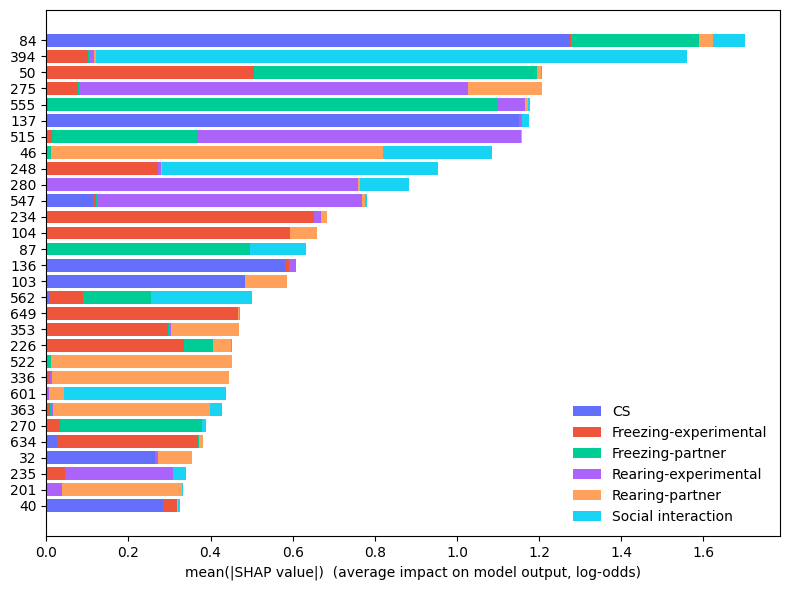

In [10]:
import numpy as np
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer.shap_values(X_validation)

# --- normalize to per-feature importance, collapsing samples AND classes ---
if isinstance(shap_values, list):                      # old multiclass: list of (n, f)
    mean_abs = np.mean([np.abs(sv).mean(0) for sv in shap_values], axis=0)
    sv_list  = shap_values
elif shap_values.ndim == 3:                            # new multiclass: (n, f, c)
    mean_abs = np.abs(shap_values).mean(axis=(0, 2))
    sv_list  = [shap_values[:, :, c] for c in range(shap_values.shape[2])]
else:                                                  # binary: (n, f)
    mean_abs = np.abs(shap_values).mean(0)
    sv_list  = [shap_values]

assert mean_abs.ndim == 1, mean_abs.shape

top10 = np.argsort(mean_abs)[::-1][:30]
X_top = X_validation.iloc[:, top10]

plot_events = {
    "CS": "#636EFA",
    "Freezing-experimental": "#EF553B",
    "Freezing-partner": "#00CC96",
    "Rearing-experimental": "#AB63FA",
    "Rearing-partner": "#FFA15A",
    "Social interaction": "#19D3F3",
}

# mean |SHAP| (log-odds) per klasa dla top-10 cech -> (n_classes, 10)
global_imp = np.vstack([np.abs(sv[:, top10]).mean(0) for sv in sv_list])

feat_names = list(X_top.columns)
order = np.argsort(global_imp.sum(0))          # rosnąco -> największe na górze
global_imp = global_imp[:, order]
feat_names = [feat_names[i] for i in order]

classes = list(plot_events.keys())             # zgodne z xgb_clf.classes_
colors  = list(plot_events.values())

fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(feat_names))
left = np.zeros(len(feat_names))
for c, (name, col) in enumerate(zip(classes, colors)):
    ax.barh(y, global_imp[c], left=left, color=col, label=name)
    left += global_imp[c]

ax.set_yticks(y); ax.set_yticklabels(feat_names)
ax.set_xlabel("mean(|SHAP value|)  (average impact on model output, log-odds)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(r"/mnt/Konrad/results/shap_top_30nrns.svg", format='svg')
plt.show()

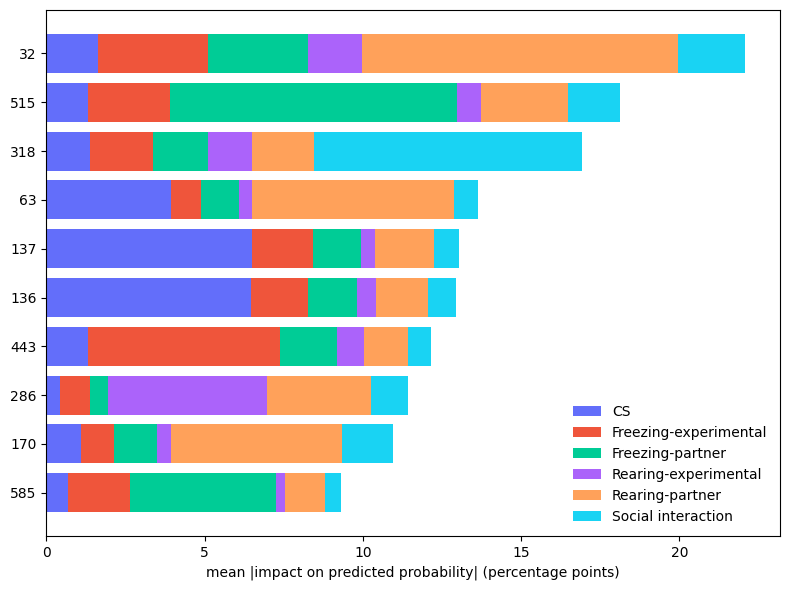

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

global_imp = np.vstack([np.abs(sv_pct[c]).mean(0) for c in range(len(sv_pct))])

feat_names = list(X_top.columns)
order = np.argsort(global_imp.sum(0))         
global_imp = global_imp[:, order]
feat_names = [feat_names[i] for i in order]

classes = list(plot_events.keys())           
colors  = list(plot_events.values())

fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(feat_names))
left = np.zeros(len(feat_names))
for c, (name, col) in enumerate(zip(classes, colors)):
    ax.barh(y, global_imp[c], left=left, color=col, label=name)
    left += global_imp[c]

ax.set_yticks(y)
ax.set_yticklabels(feat_names)
ax.set_xlabel("mean |impact on predicted probability| (percentage points)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
# --- per-feature importance, collapsing samples AND classes ---------------
mean_abs = np.abs(vals).mean(axis=(0, 2))
assert mean_abs.ndim == 1, mean_abs.shape

top10 = np.argsort(mean_abs)[::-1][:10]
X_top = X_explain.iloc[:, top10]
sv_list = [vals[:, :, c] for c in range(vals.shape[2])]

plot_events = {
    "CS": "#636EFA",
    "Freezing-experimental": "#EF553B",
    "Freezing-partner": "#00CC96",
    "Rearing-experimental": "#AB63FA",
    "Rearing-partner": "#FFA15A",
    "Social interaction": "#19D3F3",
}
listed = matplotlib.colors.ListedColormap(list(plot_events.values()))

# scale to percentage points
sv_pct = [sv_list[c][:, top10] * 100 for c in range(len(sv_list))]

shap.summary_plot(
    sv_pct, X_top,
    plot_type="bar",
    class_names=list(plot_events.keys()),
    color=listed,
    show=False,
)
plt.xlabel("mean |impact on predicted probability| (percentage points)")
plt.tight_layout()
plt.show()

In [ ]:
print(list(xgb_clf.classes_))
print(list(plot_events.keys()))

[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
['CS', 'Freezing-experimental', 'Freezing-partner', 'Rearing-experimental', 'Rearing-partner', 'Social interaction']


In [62]:
ev = np.atleast_1d(explainer.expected_value)          # shape (n_classes,)

# get raw margins from the model (log-odds, matches TreeExplainer default)
margins = xgb_clf.predict(X_validation_gpu, output_margin=True)   # (n_samples, n_classes)

# reconstruct from SHAP, per class
if isinstance(shap_values, list):                     # list of (n, f)
    recon = np.column_stack([ev[c] + shap_values[c].sum(1)
                             for c in range(len(shap_values))])
else:                                                 # 3-D: (n, f, c)
    recon = ev + shap_values.sum(axis=1)              # broadcast over classes

np.allclose(recon, margins, atol=1e-4)   # -> True

True

In [59]:
shap_values[:, :, 0][0].sum()

np.float32(-0.79630524)

In [42]:
explainer.expected_value

[np.float32(0.2850946),
 np.float32(0.22890076),
 np.float32(0.1875041),
 np.float32(0.07231655),
 np.float32(0.24982066),
 np.float32(-0.041098084)]

In [193]:
recall = np.round(np.mean(np.array(matrices_rec[-100:]), axis=0), 2)
precision = np.round(np.mean(np.array(matrices_prec[-100:]), axis=0), 2)
f1 = np.round(np.mean(np.array(matrices_f1[-100:]), axis=0), 2)
f1_sterr = np.round(np.std(np.array(matrices_f1[-100:]), axis=0), 2)

In [ ]:
class_weights = {event: w for event, w in zip(events, np.mean(all_weights, axis=0))}
importance_df = (
    pl.DataFrame(class_weights)
    .with_row_index()
    .unpivot(index="index", variable_name="event", value_name="importance")
    .rename({"index": "neuron"})
    .with_columns(cs.float().abs())
)

fig = px.scatter(importance_df, x="neuron", y="importance", color='event')
fig.show()

In [8]:
base_colors = px.colors.diverging.RdBu_r  
n_colors = len(base_colors)
mid_idx = n_colors // 6

chance_level = 1/len(events)

low_stops = np.linspace(0, chance_level, mid_idx + 1)
high_stops = np.linspace(chance_level, 1, n_colors - mid_idx)

colors = []

for i in range(mid_idx):
    colors.append([low_stops[i], base_colors[i]])

for i in range(n_colors - mid_idx):
    colors.append([high_stops[i], base_colors[mid_idx + i]])

In [325]:
animals = ['NP2', 'NP3', 'NP4', 'NP7', 'NP8', 'NP9']

In [330]:
results = {animal: {'spearman_rank': None, 'decoding': None} for animal in animals}

for animal in animals:

    # Slice out two classes
    X_train = datasets[animal]["X_train"]
    X_test = datasets[animal]["X_test"]

    y_train = datasets[animal]["y_train"][:, 0]
    condition_train = np.isin(y_train, [1, 3])

    X_train = X_train[condition_train]
    y_train = y_train[condition_train]
    y_train = np.where(y_train == 1, 0, 1)

    y_test = datasets[animal]["y_test"][:, 0]
    condition_test = np.isin(y_test, [1, 3])

    X_test = X_test[condition_test]
    y_test = y_test[condition_test]
    y_test = np.where(y_test == 1, 0, 1)

    sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

    # Run model
    xgb_clf_self = XGBClassifier(
        booster="gbtree",
        objective="binary:logistic",
        n_estimators=64,
        seed=42,
        learning_rate=0.05,
        reg_lambda=1,
        max_depth=3,
    )

    xgb_clf_self.fit(X_train, y_train, sample_weight=sample_weights)
    y_pred = xgb_clf_self.predict(X_test)

    # Get metrics
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    recall = np.round(confusion_matrix(y_test, y_pred, normalize="true"), 2)
    precision = np.round(confusion_matrix(y_test, y_pred, normalize="pred"), 2)
    f1_self = np.round(
        np.nan_to_num(
            np.round((2 * (recall * precision)) / (recall + precision + 1e-9), 2)
        ),
        2,
    )

    decoding_performance = np.diagonal(f1)

    # Plot results
    # px.imshow(
    #     recall, x=["freez", "rear"], y=["freez", "rear"], text_auto=True, width=600
    # ).show()
    # px.imshow(
    #     precision, x=["freez", "rear"], y=["freez", "rear"], text_auto=True, width=600
    # ).show()
    # px.imshow(
    #     f1, x=["freez", "rear"], y=["freez", "rear"], text_auto=True, width=600
    # ).show()

    # Slice out two classes
    X_train = datasets[animal]["X_train"]
    X_test = datasets[animal]["X_test"]

    y_train = datasets[animal]["y_train"][:, 0]
    condition_train = np.isin(y_train, [2, 4])

    X_train = X_train[condition_train]
    y_train = y_train[condition_train]
    y_train = np.where(y_train == 2, 0, 1)

    y_test = datasets[animal]["y_test"][:, 0]
    condition_test = np.isin(y_test, [2, 4])

    X_test = X_test[condition_test]
    y_test = y_test[condition_test]
    y_test = np.where(y_test == 2, 0, 1)

    sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

    # Run model
    xgb_clf_partner = XGBClassifier(
        booster="gbtree",
        objective="binary:logistic",
        n_estimators=100,
        seed=42,
        learning_rate=0.05,
        reg_lambda=5,
        max_depth=3,
    )

    xgb_clf_partner.fit(X_train, y_train, sample_weight=sample_weights)
    y_pred = xgb_clf_partner.predict(X_test)

    # Get metrics
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    recall = np.round(confusion_matrix(y_test, y_pred, normalize="true"), 2)
    precision = np.round(confusion_matrix(y_test, y_pred, normalize="pred"), 2)
    f1_partner = np.round(
        np.nan_to_num(
            np.round((2 * (recall * precision)) / (recall + precision + 1e-9), 2)
        ),
        2,
    )

    decoding_performance = np.diagonal(f1)

    # Plot results
    # px.imshow(
    #     recall, x=["freez", "rear"], y=["freez", "rear"], text_auto=True, width=600
    # ).show()
    # px.imshow(
    #     precision, x=["freez", "rear"], y=["freez", "rear"], text_auto=True, width=600
    # ).show()
    # px.imshow(
    #     f1, x=["freez", "rear"], y=["freez", "rear"], text_auto=True, width=600
    # ).show()

    self_importances = pl.DataFrame({'self': xgb_clf_self.feature_importances_})
    partner_importances = pl.DataFrame({'partner': xgb_clf_partner.feature_importances_})

    plot_df = (
        pl.concat([self_importances, partner_importances], how="horizontal")
        .unpivot(variable_name="animal", value_name="feature_importance")
        .with_columns(pl.Series(list(range(X_train.shape[1])) * 2).alias('nrn_id'))
    )

    results[animal]['spearman_rank'] = plot_df.pivot(on="animal", values="feature_importance", index="nrn_id").select(
        pl.corr("self", "partner", method="spearman")
    ).item()
    results[animal]['decoding'] = {'self': f1_self, 'partner': f1_partner}
    px.scatter(plot_df, x='nrn_id', y='feature_importance', color='animal', width=600)

In [345]:
for animal in animals:
    print(results[animal]["spearman_rank"])
    fig1 = px.imshow(
        results[animal]["decoding"]["self"], width=200, height=200, text_auto=True, title='self'
    ).update_layout(font=dict(size=8), margin=dict(t=25, b=0, r=0, l=0)).show()
    fig2 = px.imshow(
        results[animal]["decoding"]["partner"], width=200, height=200, text_auto=True, title='partner'
    ).update_layout(font=dict(size=8), margin=dict(t=25, b=0, r=0, l=0)).show()

0.3439255654811859


0.2568996250629425


0.15522201359272003


0.15770015120506287


0.11935169249773026


0.28338101506233215


Computing SHAP values (this may take a moment)...


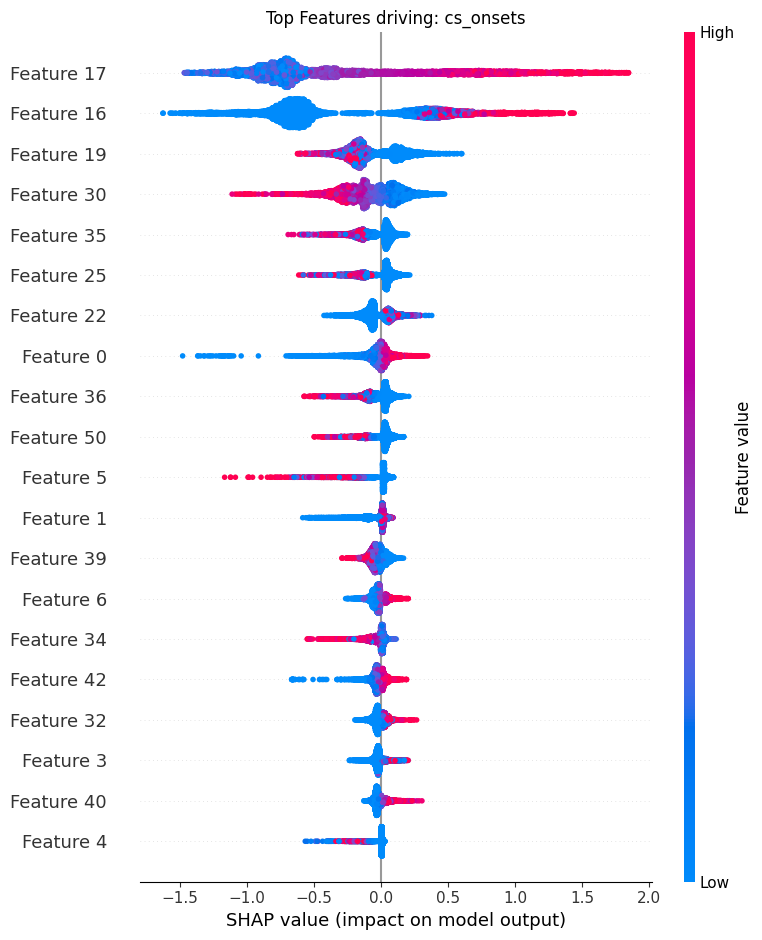

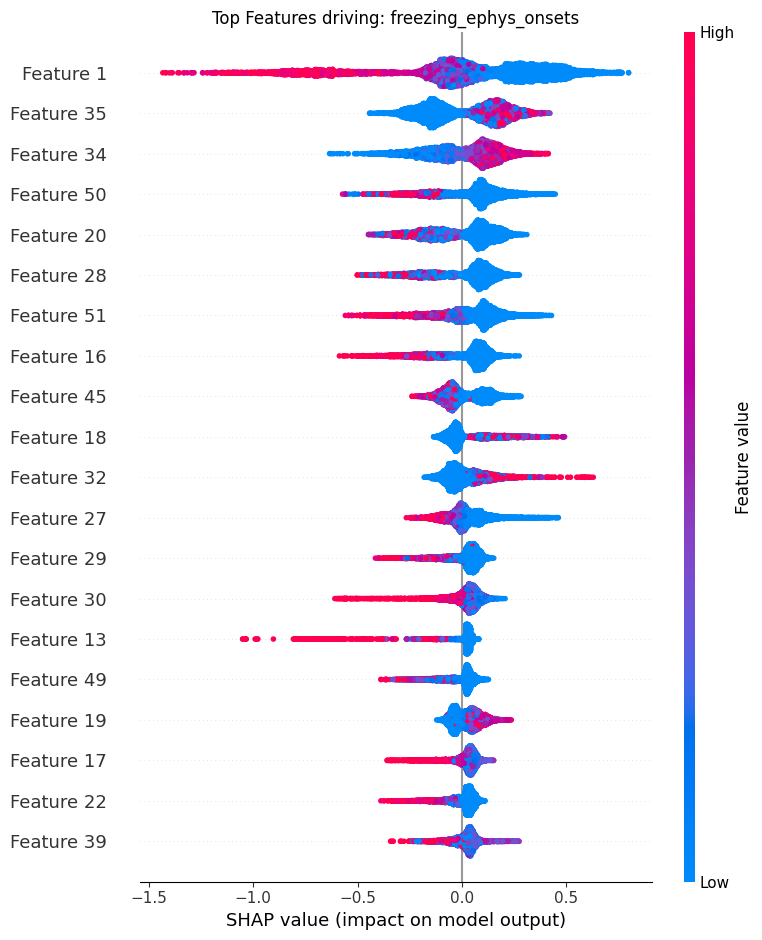

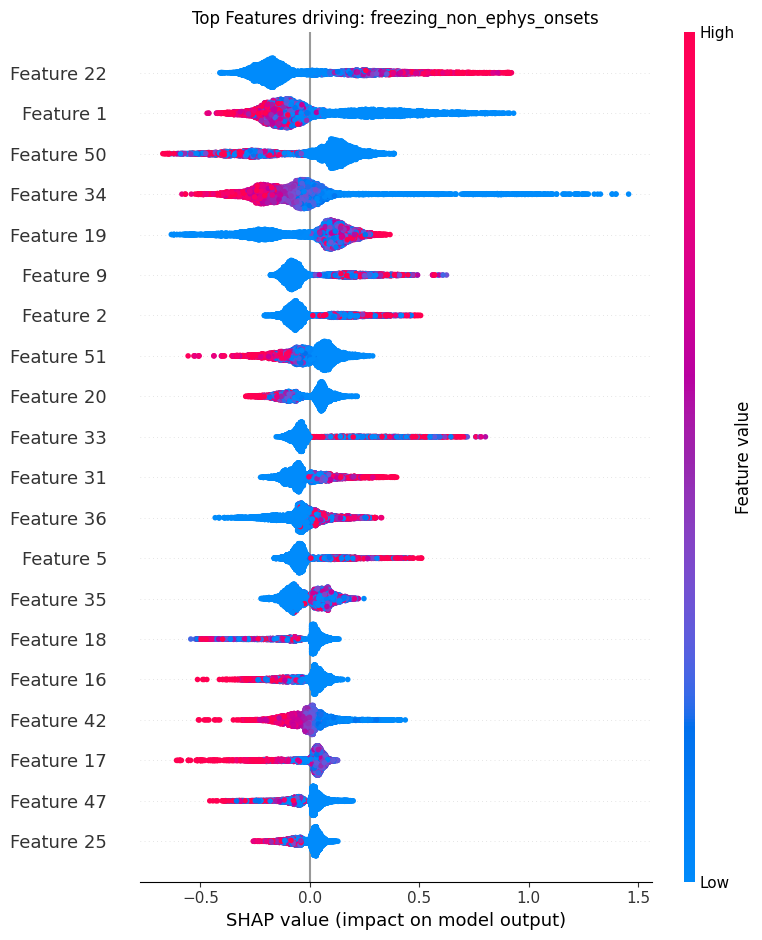

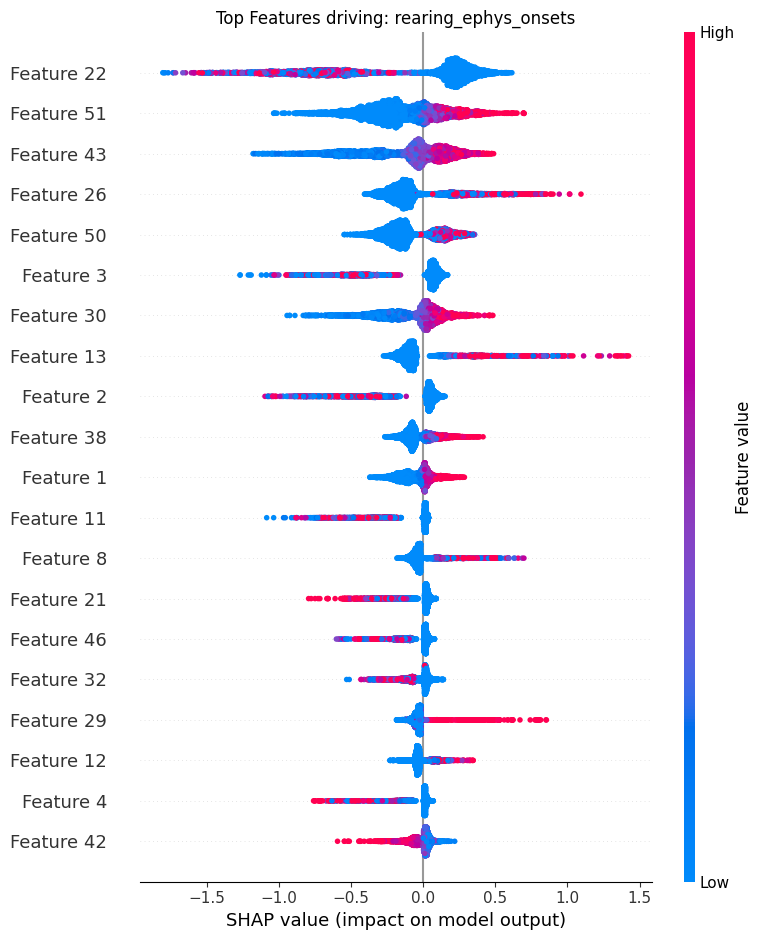

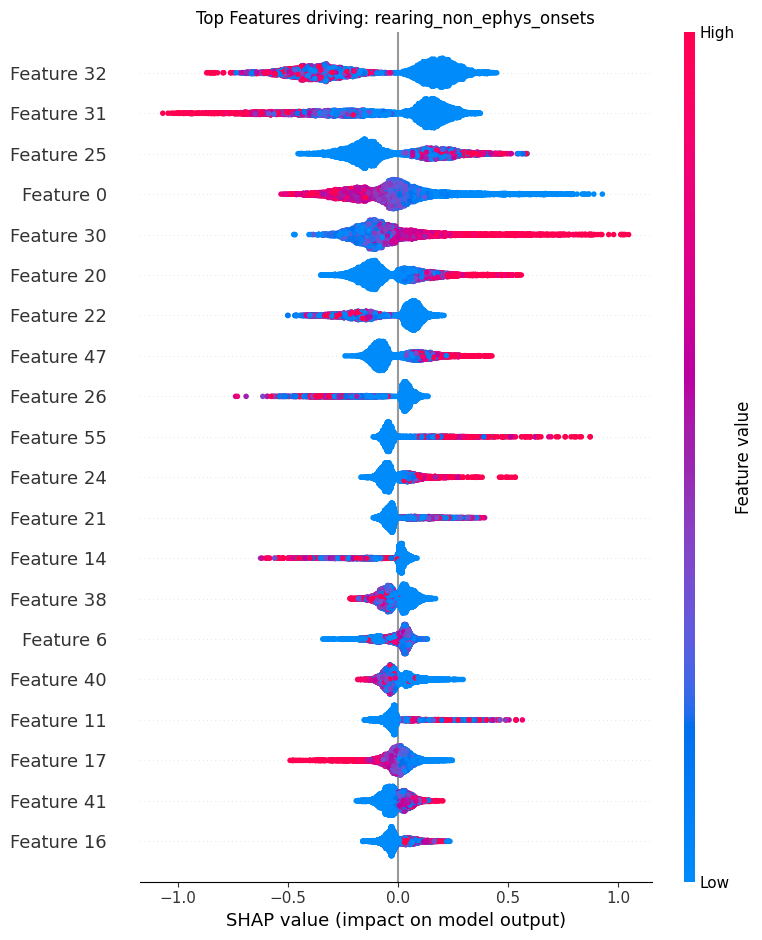

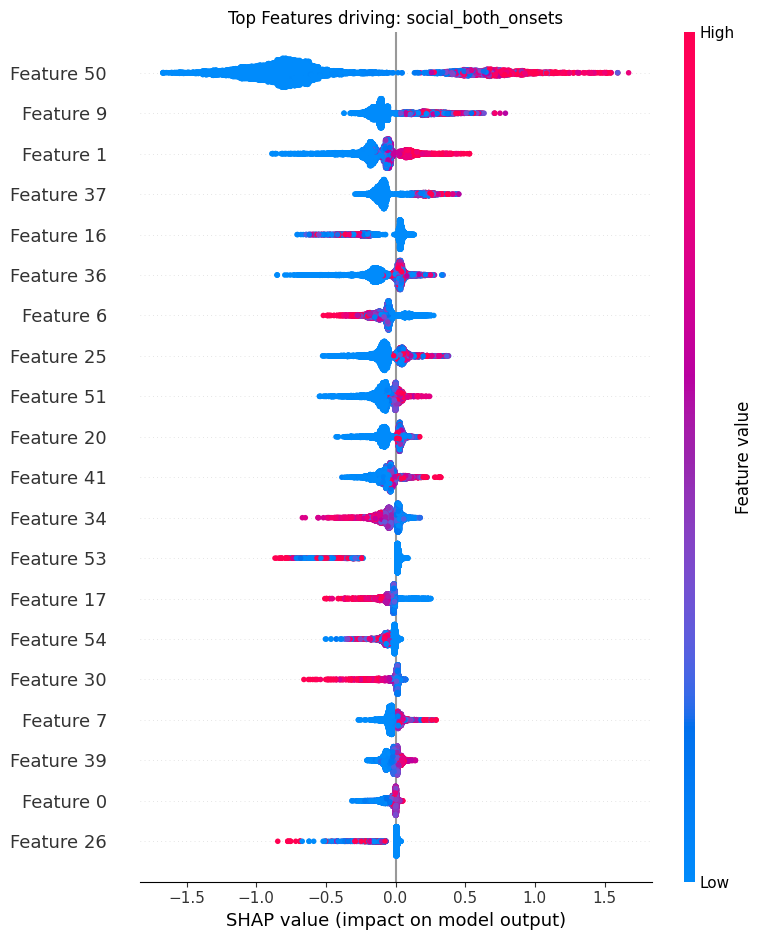

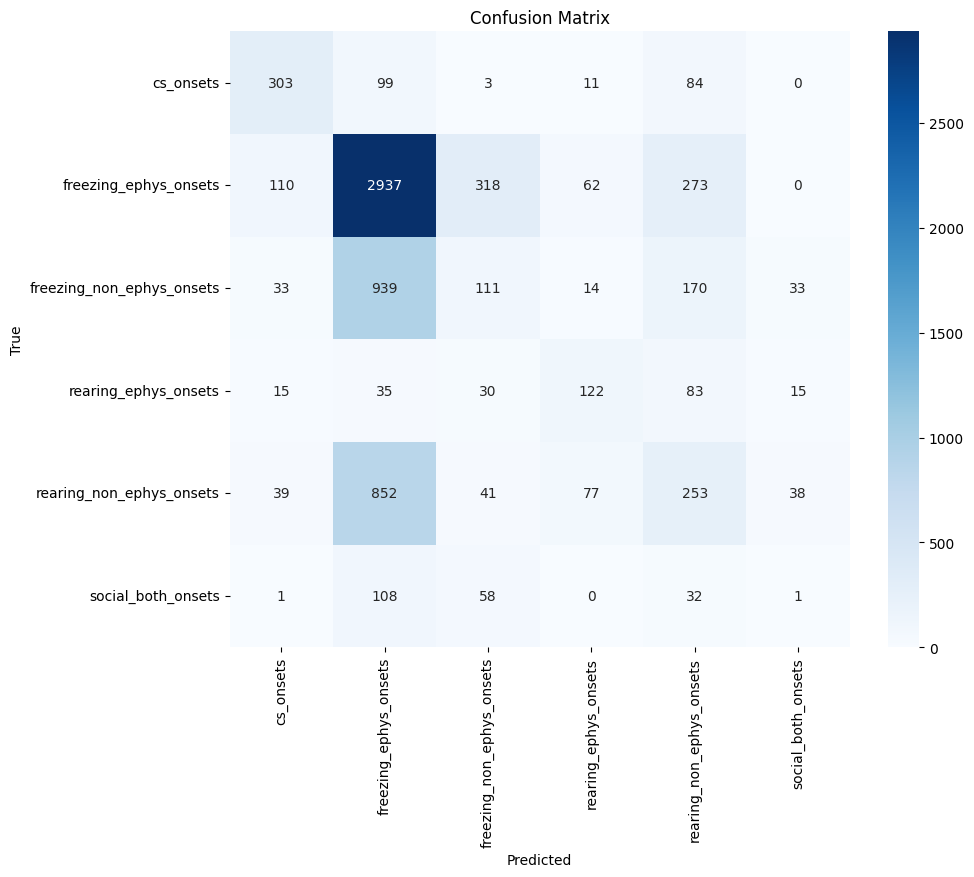


Classification Report:
                            precision    recall  f1-score   support

                cs_onsets       0.60      0.61      0.61       500
    freezing_ephys_onsets       0.59      0.79      0.68      3700
freezing_non_ephys_onsets       0.20      0.09      0.12      1300
     rearing_ephys_onsets       0.43      0.41      0.42       300
 rearing_non_ephys_onsets       0.28      0.19      0.23      1300
       social_both_onsets       0.01      0.01      0.01       200

                 accuracy                           0.51      7300
                macro avg       0.35      0.35      0.34      7300
             weighted avg       0.44      0.51      0.46      7300


Analyzing 939 trials where freezing_non_ephys_onsets was misclassified as freezing_ephys_onsets.


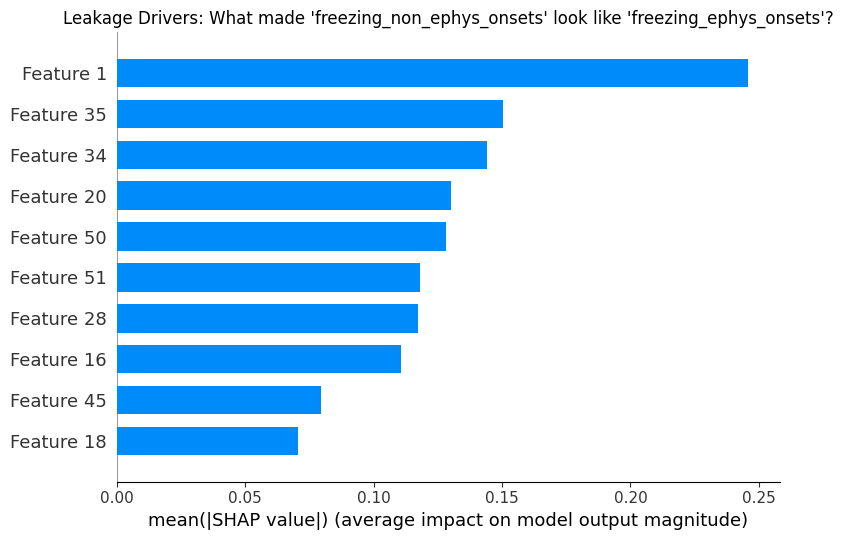


Analyzing 852 trials where rearing_non_ephys_onsets was misclassified as freezing_ephys_onsets.


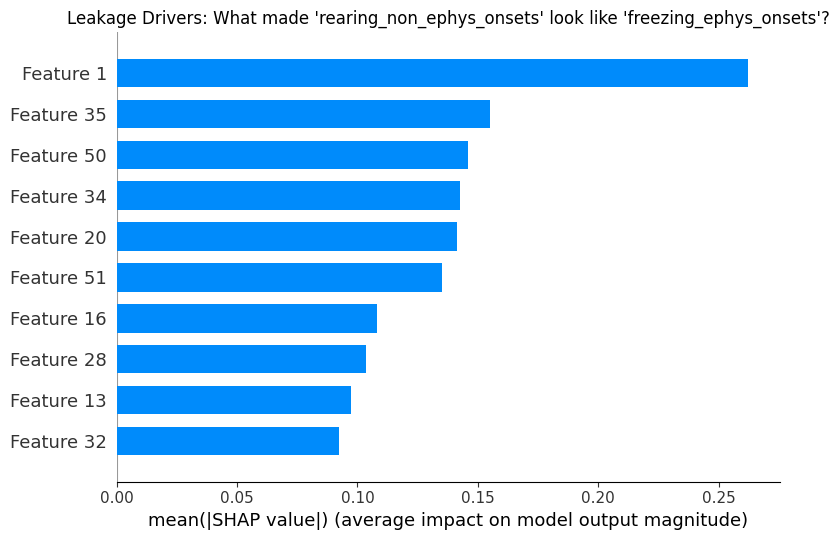


Analyzing 318 trials where freezing_ephys_onsets was misclassified as freezing_non_ephys_onsets.


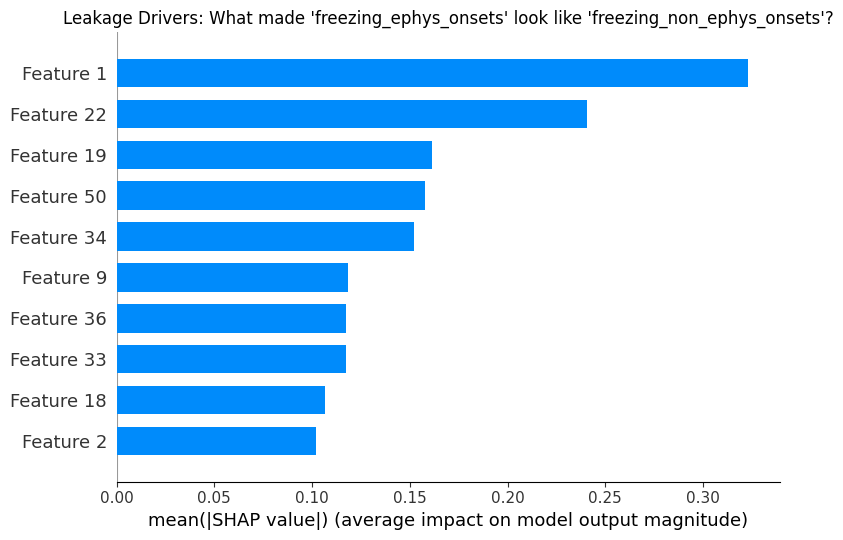

X_test must be a pandas DataFrame with feature names to parse temporal data.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

class_names = [
    'cs_onsets', 
    'freezing_ephys_onsets', 
    'freezing_non_ephys_onsets', 
    'rearing_ephys_onsets', 
    'rearing_non_ephys_onsets', 
    'social_both_onsets'
]

X_test=datasets[animal]["X_test"]

print("Computing SHAP values (this may take a moment)...")
explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer.shap_values(X_test)


if isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:
    shap_values = [shap_values[:, :, i] for i in range(shap_values.shape[2])]

def plot_global_shap():
    """Plots top features for each class to check for suspicious overlaps."""
    for i, class_name in enumerate(class_names):
        plt.figure(figsize=(8, 5))
        plt.title(f"Top Features driving: {class_name}")
        shap.summary_plot(shap_values[i], X_test, plot_type="dot", show=False)
        plt.tight_layout()
        plt.show()

def analyze_confusion():
    """Identifies classes that are frequently confused."""
    cm = confusion_matrix(y_test[:, 0], y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion Matrix')
    plt.show()
    print("\nClassification Report:\n", classification_report(y_test[:, 0], y_pred, target_names=class_names))

def analyze_misclassification_leakage(true_class_idx, pred_class_idx, top_n=10):
    """
    Analyzes why True Class A was confused for Predicted Class B.
    Extracts features that drove the false prediction.
    """
    true_name = class_names[true_class_idx]
    pred_name = class_names[pred_class_idx]
    
    confused_indices = np.where((y_test[:,0].to_numpy() == true_class_idx) & (y_pred == pred_class_idx))[0]
    
    if len(confused_indices) == 0:
        print(f"No instances where {true_name} was confused for {pred_name}.")
        return
        
    print(f"\nAnalyzing {len(confused_indices)} trials where {true_name} was misclassified as {pred_name}.")
    
    shap_confused = shap_values[pred_class_idx][confused_indices]
    X_confused = X_test.iloc[confused_indices] if isinstance(X_test, pd.DataFrame) else X_test[confused_indices]
    
    plt.figure(figsize=(8, 5))
    plt.title(f"Leakage Drivers: What made '{true_name}' look like '{pred_name}'?")
    shap.summary_plot(shap_confused, X_confused, plot_type="bar", max_display=top_n, show=False)
    plt.show()

def plot_temporal_shap_profile():
    """
    Groups SHAP values by time step (0 to 99) to see WHEN the model is making its decisions.
    Assumes feature columns have a naming convention like 'sensorName_t0', 'sensorName_t1', etc.
    If your columns are just named 0 to 668, you will need to map them back to their time steps.
    """
    if not isinstance(X_test, pd.DataFrame):
        print("X_test must be a pandas DataFrame with feature names to parse temporal data.")
        return
        
    # Example logic: extract time integer from feature name (e.g., "ephys_ch1_t45" -> 45)
    # Adjust this regex/extraction based on your actual column names!
    try:
        import re
        # Find all numbers in the column name, assume the last one is the time step (0-99)
        time_steps = [int(re.findall(r'\d+', col)[-1]) for col in X_test.columns]
    except Exception as e:
        print("Could not parse time steps from feature names. Ensure they contain time indices.")
        return

    # Calculate mean absolute SHAP value across all samples, for all features, for all classes
    # Shape of mean_abs_shap: (n_classes, n_features)
    mean_abs_shap = np.array([np.abs(sv).mean(axis=0) for sv in shap_values])
    
    temporal_importance = {class_name: np.zeros(100) for class_name in class_names}
    
    # Aggregate importance by time step
    for class_idx, class_name in enumerate(class_names):
        for feat_idx, t in enumerate(time_steps):
            if 0 <= t < 100:
                temporal_importance[class_name][t] += mean_abs_shap[class_idx, feat_idx]
                
    # Plotting
    plt.figure(figsize=(14, 6))
    for class_name in class_names:
        # Smooth the line slightly for readability
        smoothed = pd.Series(temporal_importance[class_name]).rolling(window=3, center=True).mean()
        plt.plot(range(100), smoothed, label=class_name, linewidth=2)
        
    plt.axvline(x=0, color='red', linestyle='--', alpha=0.5, label='Trial Start')
    plt.axvline(x=99, color='black', linestyle='--', alpha=0.5, label='Trial End')
    plt.title("Temporal SHAP Profile: When is the model looking?")
    plt.xlabel("Time Step (0-99)")
    plt.ylabel("Aggregated SHAP Importance")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


plot_global_shap()
analyze_confusion()

analyze_misclassification_leakage(true_class_idx=2, pred_class_idx=1) 
analyze_misclassification_leakage(true_class_idx=4, pred_class_idx=1)
analyze_misclassification_leakage(true_class_idx=1, pred_class_idx=2)

plot_temporal_shap_profile()

In [18]:
df = (
    y_test.with_columns(pl.Series(y_pred).alias("pred"))
    .with_columns(pl.col("class_idx").eq(pl.col("pred")).alias("correct"))
)
df

class_idx,timestamp,class,trial,sample,pred,correct
i32,f32,str,i32,i64,i64,bool
0,126.269859,"""cs_onsets""",0,1,1,false
0,126.289864,"""cs_onsets""",0,2,1,false
0,126.30986,"""cs_onsets""",0,3,4,false
0,126.329865,"""cs_onsets""",0,4,4,false
0,126.349861,"""cs_onsets""",0,5,4,false
…,…,…,…,…,…,…
5,1046.12146,"""social_both_onsets""",3,96,1,false
5,1046.141357,"""social_both_onsets""",3,97,1,false
5,1046.161377,"""social_both_onsets""",3,98,1,false


In [ ]:
animal_col = sorted(list(to_drop.keys()) * 6)
df = pl.DataFrame(
    np.concatenate(
        [
            np.array([animal_ablation[animal][3], animal_ablation[animal][4]])
            for animal in to_drop.keys()
        ],
        axis=1,
    ).T,
    schema = {
        'F1-score': pl.Float64,
        'err': pl.Float64,
    },
)
df = df.with_columns(
    pl.Series(animal_col).alias('animal'),
    pl.Series(events*6).alias('event'),
)

fig = px.box(df, x='event', y='F1-score', color='event', points='all', hover_data='animal', width=1000, title='Animal ablation', template='plotly_white')
fig.add_hrect(0, 0.16, fillcolor="grey", opacity=0.2, annotation_text="Chance level", annotation_position="top left")
fig.update_xaxes(title=None)

In [66]:
events = [
    "CS",
    "Freezing-experimental",
    "Freezing-partner",
    "Rearing-experimental",
    "Rearing-partner",
    "Social interaction",
]

def plot_confusion_matrix(matrix, events, title, path, save):
    htmap = pd.DataFrame(matrix, columns=events, index=events)
    fig = px.imshow(
        htmap,
        text_auto=True,
        labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
        height=600,
        width=600,
        color_continuous_scale=colors,
        zmin=0,
        zmax=1,
        title=f"<b>{title}</b>",
        template="plotly_white",
    )
    fig.update_layout(
        title_x=0.57,
        title_y=0.83,
        font=dict(family="Arial", size=14, color="black"),
    )
    fig.update_coloraxes(colorbar_len=0.85)
    fig.show()
    if save:
        fig.write_image(rf"{path}")

# plot_confusion_matrix(animal_ablation['NP2'][0], events, 'Recall', "/mnt/Konrad/results/recall_noNP2.svg", False)
# plot_confusion_matrix(animal_ablation['NP2'][1], events, 'Precision', "/mnt/Konrad/results/precision_noNP2.svg", False)
plot_confusion_matrix(animal_ablation['NP9'][2], events, 'Decoding performance - confusion matrix', "/mnt/Konrad/results/f1_noNP2.svg", False)

In [83]:
dfs = []
for report in reports:
    dfs.append(pd.DataFrame(report))

df = pd.concat(dfs)
df = df.groupby(df.index).mean()

cols = [*events, "accuracy", "macro avg", "weigthed avg"]
df.columns = cols

events = [
    "CS",
    "Freezing-experimental",
    "Freezing-partner",
    "Rearing-experimental",
    "Rearing-partner",
    "Social interaction",
]

htmap = pd.DataFrame(recall, columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale=colors,
    zmin=0,
    zmax=1,
    title="<b>Recall</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=14, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(r"/mnt/Konrad/results/recall_main.svg")

htmap = pd.DataFrame(precision, columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale=colors,
    zmin=0,
    zmax=1,
    title="<b>Precision</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=14, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(r"/mnt/Konrad/results/precision_main.svg")


htmap = pd.DataFrame(f1, columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale=colors,
    zmin=0,
    zmax=1,
    title="<b>Decoding performance - confusion matrix</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=14, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(r"/mnt/Konrad/results/f1_main.svg")

ValueError: Length mismatch: Expected axis has 5 elements, new values have 9 elements

In [27]:
y_test

class_idx,timestamp,class,trial,sample
i32,f32,str,i32,i64
0,123.129936,"""cs_onsets""",0,1
0,123.14994,"""cs_onsets""",0,2
0,123.169937,"""cs_onsets""",0,3
0,123.189941,"""cs_onsets""",0,4
0,123.209938,"""cs_onsets""",0,5
…,…,…,…,…
5,2376.339111,"""social_both_onsets""",10,96
5,2376.359131,"""social_both_onsets""",10,97
5,2376.37915,"""social_both_onsets""",10,98


In [ ]:
# Cross validation with ablation step
n_steps = 50
all_records = []  # {shuffle, neurons_removed, class, f1}

matrices2 = {i: {} for i in range(n_steps + 1)}
matrices_all2 = {i: {} for i in range(n_steps + 1)}
matrices_f1 = {i: {} for i in range(n_steps + 1)}

for X_train, X_validation, y_train, y_validation, step in tqdm(
    zip(
        X_trains[:n_steps],
        X_validations[:n_steps],
        y_trains[:n_steps],
        y_validations[:n_steps],
        range(n_steps),
    ),
    total=n_steps,
):
    available = np.arange(X_train.shape[1])
    n_removed = 0

    while len(available) > 0:
        X_tr = cp.array(X_train.values[:, available])
        X_val = cp.array(X_validation.values[:, available])

        sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)
        xgb_clf = XGBClassifier(
            booster="gbtree",
            objective="multi:softprob",
            tree_method="hist",
            device="cuda:0",
            n_estimators=300,
            seed=42,
            learning_rate=0.05,
            reg_lambda=10,
            reg_alpha=0,
            max_depth=12,
            subsample=0.8,
            colsample_bytree=0.8,
        )
        xgb_clf.fit(X_tr, cp.array(y_train), sample_weight=sample_weights)

        y_pred = xgb_clf.predict(X_val)
        report = classification_report(
            y_validation, y_pred, output_dict=True, zero_division=0
        )

        matrices2[step][len(available)] = confusion_matrix(
            y_validation, y_pred, normalize="true"
        )
        matrices_all2[step][len(available)] = confusion_matrix(
            y_validation, y_pred, normalize="pred"
        )
        matrices_f1[step][len(available)] = np.nan_to_num(
            np.round(
                (
                    2
                    * (
                        matrices2[step][len(available)]
                        * matrices_all2[step][len(available)]
                    )
                )
                / (
                    matrices2[step][len(available)]
                    + matrices_all2[step][len(available)]
                    + 1e-9
                ),
                2,
            )
        )

        for label in range(6):
            all_records.append(
                {
                    "step": step,
                    "neurons_removed": n_removed,
                    "class": str(label),
                    "f1": report[str(label)]["f1-score"],
                }
            )

        importances = xgb_clf.feature_importances_
        n_to_remove = min(60, len(available))
        top_relative_indices = np.argsort(importances)[-n_to_remove:]
        n_removed += len(top_relative_indices)
        available = np.delete(available, top_relative_indices)

100%|██████████| 50/50 [1:00:27<00:00, 72.56s/it]


In [149]:
results = []

for j in matrices2[0].keys():
    arr = np.array([
        (2 * (matrices2[i][j] * matrices_all2[i][j])) /
        (matrices2[i][j] + matrices_all2[i][j] + 1e-9)
        for i in range(50)
    ])

    mean = np.mean(arr, axis=0)
    std_err = np.std(arr, axis=0) / np.sqrt(50)

    results.append((np.diagonal(mean), np.diagonal(std_err)))

df = pl.DataFrame(np.array([r[0] for r in results]))
df_std = pl.DataFrame(np.array([r[1] for r in results]))


df_std.columns = events
df.columns = events
df = df.with_columns(
    pl.Series([j for j in matrices2[0].keys()]).alias("n_neurons")
).unpivot(index="n_neurons", variable_name="event", value_name="mean")
df_std = df_std.with_columns(
    pl.Series([j for j in matrices2[0].keys()]).alias("n_neurons")
).unpivot(index="n_neurons", variable_name="event", value_name="std")

plot_df = df_std.join(df, on=["n_neurons", "event"]).with_columns(
    (pl.col("mean") - pl.col("std")).alias("lower"),
    (pl.col("mean") + pl.col("std")).alias("upper"),
)

In [150]:
fig = go.Figure()

for (i, animal), color in zip(
    enumerate(plot_df["event"].unique().sort()),
    [
        "rgb(99,110,250)",
        "rgb(239,85,59)",
        "rgb(0,204,150)",
        "rgb(171,99,250)",
        "rgb(255,161,90)",
        "rgb(25,211,243)",
    ],
):
    animal_df = plot_df.filter(pl.col("event") == animal)
    x = animal_df["n_neurons"].to_list()
    y = animal_df["mean"].to_list()
    lower = animal_df["lower"].to_list()
    upper = animal_df["upper"].to_list()

    fig.add_trace(
        go.Scatter(
            x=x + x[::-1],
            y=upper + lower[::-1],
            fill="toself",
            fillcolor=color,
            line=dict(color="rgba(0,0,0,0)", shape="spline"),
            opacity=0.2,
            showlegend=False,
        )
    )
    fig.add_trace(
        go.Scatter(
            x=x,
            y=y,
            mode="lines",
            name=animal,
            line=dict(color=color, shape="spline", width=5),
            showlegend=False,
        )
    )

fig.update_layout(
    template="simple_white",
    font=dict(family="Arial", size=20, color="black"),
    width=1000,
    height=500,
    # showlegend=True,
    xaxis=dict(autorange="reversed", title='<b># of neurons used</b>'),
    yaxis=dict(title='<b>Decoding performance</b>', range=[0,1], autorange=False),
)
fig.add_hrect(0, 0.16, fillcolor="grey", opacity=0.2, annotation_text="Chance level", annotation_position="top left")
fig.show()
fig.write_image(r'/mnt/Konrad/results/nrn_ablation.svg')

In [151]:
# Cross validation: decoding performance by top-N neurons per class
reports_topn = []
all_records_topn = []

n_steps = 50
n_total_neurons_steps = range(6, 669, 60)  # 10, 20, ..., 100 neurons per class

matrices3 = {i: {} for i in range(n_steps + 1)}
matrices_all3 = {i: {} for i in range(n_steps + 1)}
matrices3_f1 = {i: {} for i in range(n_steps + 1)}

for X_train, X_validation, y_train, y_validation, step in tqdm(
    zip(
        X_trains[:n_steps],
        X_validations[:n_steps],
        y_trains[:n_steps],
        y_validations[:n_steps],
        range(n_steps),
    ),
    total=n_steps,
):
    # Fit full model to get per-class neuron importance
    sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)
    xgb_full = XGBClassifier(
        booster="gbtree",
        objective="multi:softprob",
        tree_method="hist",
        n_estimators=300,
        seed=42,
        learning_rate=0.05,
        reg_lambda=10,
        reg_alpha=0,
        max_depth=12,
        subsample=0.8,
        colsample_bytree=0.8,
        device='cuda:0',
    )
    xgb_full.fit(cp.array(X_train.values), cp.array(y_train), sample_weight=sample_weights)
    global_importances = xgb_full.feature_importances_
    sorted_indices = np.argsort(global_importances)[::-1]
    for n_neurons in n_total_neurons_steps:
        selected_indices = sorted_indices[:n_neurons]

        X_tr = cp.array(X_train.values[:, selected_indices])
        X_val = cp.array(X_validation.values[:, selected_indices])

        sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)
        xgb_clf = XGBClassifier(
            booster="gbtree",
            objective="multi:softprob",
            tree_method="hist",
            n_estimators=300,
            seed=42,
            learning_rate=0.05,
            reg_lambda=10,
            reg_alpha=0,
            max_depth=12,
            subsample=0.8,
            colsample_bytree=0.8,
            device='cuda:0',
        )
        xgb_clf.fit(X_tr, y_train, sample_weight=sample_weights)

        y_pred = xgb_clf.predict(cp.array(X_val))
        report = classification_report(
            y_validation, y_pred, output_dict=True, zero_division=0
        )

        reports.append(
            classification_report(
                y_validation, y_pred, output_dict=True, zero_division=0
            )
        )
        matrices3[step][n_neurons] = confusion_matrix(
            y_validation, y_pred, normalize="true"
        )
        matrices_all3[step][n_neurons] = confusion_matrix(
            y_validation, y_pred, normalize="pred"
        )
        matrices3_f1[step][n_neurons] = np.nan_to_num(
            np.round(
                (
                    2
                    * (
                        matrices3[step][n_neurons]
                        * matrices_all3[step][n_neurons]
                    )
                )
                / (
                    matrices3[step][n_neurons]
                    + matrices_all3[step][n_neurons]
                    + 1e-9
                ),
                2,
            )
        )

        for label in range(6):
            all_records_topn.append(
                {
                    "step": step,
                    "n_neurons": n_neurons,
                    "class": str(label),
                    "f1": report[str(label)]["f1-score"],
                }
            )

100%|██████████| 50/50 [52:25<00:00, 62.91s/it]


In [154]:
results = []

for j in matrices3[0].keys():
    arr = np.array([
        (2 * (matrices3[i][j] * matrices_all3[i][j])) /
        (matrices3[i][j] + matrices_all3[i][j] + 1e-9)
        for i in range(50)
    ])

    mean = np.mean(arr, axis=0)
    std_err = np.std(arr, axis=0) / np.sqrt(50)

    results.append((np.diagonal(mean), np.diagonal(std_err)))

df = pl.DataFrame(np.array([r[0] for r in results]))
df_std = pl.DataFrame(np.array([r[1] for r in results]))


df_std.columns = events
df.columns = events
df = df.with_columns(
    pl.Series([j for j in matrices3[0].keys()]).alias("n_neurons")
).unpivot(index="n_neurons", variable_name="event", value_name="mean")
df_std = df_std.with_columns(
    pl.Series([j for j in matrices3[0].keys()]).alias("n_neurons")
).unpivot(index="n_neurons", variable_name="event", value_name="std")

plot_df = df_std.join(df, on=["n_neurons", "event"]).with_columns(
    (pl.col("mean") - pl.col("std")).alias("lower"),
    (pl.col("mean") + pl.col("std")).alias("upper"),
)

In [161]:
plot_df

n_neurons,event,std,mean,lower,upper
i64,str,f64,f64,f64,f64
6,"""CS""",0.0147,0.585985,0.571285,0.600684
66,"""CS""",0.008057,0.787448,0.779391,0.795505
126,"""CS""",0.007277,0.804075,0.796797,0.811352
186,"""CS""",0.007886,0.811284,0.803398,0.81917
246,"""CS""",0.007476,0.815156,0.80768,0.822632
…,…,…,…,…,…
426,"""Social interaction""",0.036351,0.30483,0.26848,0.341181
486,"""Social interaction""",0.035829,0.305113,0.269284,0.340942
546,"""Social interaction""",0.036193,0.309194,0.273001,0.345387


In [162]:
fig = go.Figure()

for (i, animal), color in zip(
    enumerate(plot_df["event"].unique().sort()),
    [
        "rgb(99,110,250)",
        "rgb(239,85,59)",
        "rgb(0,204,150)",
        "rgb(171,99,250)",
        "rgb(255,161,90)",
        "rgb(25,211,243)",
    ],
):
    animal_df = plot_df.filter(pl.col("event") == animal)
    x = animal_df["n_neurons"].to_list()
    y = animal_df["mean"].to_list()
    lower = animal_df["lower"].to_list()
    upper = animal_df["upper"].to_list()

    fig.add_trace(
        go.Scatter(
            x=x + x[::-1],
            y=upper + lower[::-1],
            fill="toself",
            fillcolor=color,
            line=dict(color="rgba(0,0,0,0)", shape="spline"),
            opacity=0.2,
            showlegend=False,
        )
    )
    fig.add_trace(
        go.Scatter(
            x=x,
            y=y,
            mode="lines",
            name=animal,
            line=dict(color=color, shape="spline", width=5),
            showlegend=False,
        )
    )

fig.update_layout(
    template="simple_white",
    font=dict(family="Arial", size=20, color="black"),
    width=1000,
    height=500,
    # showlegend=True,
    xaxis=dict(title='<b># of neurons used</b>'),
    yaxis=dict(title='<b>Decoding performance</b>', range=[0,1], autorange=False),
)
fig.add_hrect(0, 0.16, fillcolor="grey", opacity=0.2, annotation_text="Chance level", annotation_position="top left")
fig.show()
fig.write_image(r'/mnt/Konrad/results/nrn_addition.svg')

In [169]:
px.imshow(np.array([matrices_all3[i][6] for i in range(50)]).mean(axis=0).round(2), text_auto=True)

In [ ]:
px.imshow(np.array([matrices3[i][6] for i in range(50)]).mean(axis=0).round(2), text_auto=True)

dict_keys([6, 66, 126, 186, 246, 306, 366, 426, 486, 546, 606, 666])

In [ ]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(rows=3, cols=4, subplot_titles=(tuple(matrices3[i].keys())))  # Set subplot titles

subplot_positions = [(row, col) for row in range(1, 4) for col in range(1, 5)]
counter = 0

for nrns in matrices3[i].keys():
    if counter >= len(subplot_positions):
        break

    row, col = subplot_positions[counter]
    showscale = True if counter == 0 else False  # Only show colorbar for the first subplot

    fig.add_trace(
        go.Heatmap(
            z=np.fliplr(np.array(
                [
                    (2 * (matrices3[i][nrns] * matrices_all3[i][nrns]))
                    / (matrices3[i][nrns] + matrices_all3[i][nrns] + 1e-9)
                    for i in range(50)
                ]
            ))
            .mean(axis=0)
            .round(2),
            text=np.fliplr(np.array(
                [
                    (2 * (matrices3[i][nrns] * matrices_all3[i][nrns]))
                    / (matrices3[i][nrns] + matrices_all3[i][nrns] + 1e-9)
                    for i in range(50)
                ]
            ))
            .mean(axis=0)
            .round(2),
            texttemplate="%{text}",
            textfont={"size": 8},
            showscale=showscale,
        ),
        row=row,
        col=col,
    )
    counter += 1

fig.update_layout(height=800, width=1000)
fig.show()
fig.write_image(r'/mnt/Konrad/results/nrn_addition_f1_heatmaps.svg')

In [362]:
dfs = []
for report in reports:
    dfs.append(pd.DataFrame(report))

df = pd.concat(dfs)
df = df.groupby(df.index).mean()

cols = [*events, "accuracy", "macro avg", "weigthed avg"]
df.columns = cols

matrix = np.mean(np.array(matrices), axis=0)
matrix_prec = np.mean(np.array(matrices_all), axis=0)

events = [
    "CS",
    "Freezing-experimental",
    "Freezing-partner",
    "Rearing-experimental",
    "Rearing-partner",
    "Social interaction",
]

matrix = np.mean(np.array(matrices), axis=0)
htmap = pd.DataFrame(np.round(matrix, 3), columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale=colors,
    zmin=0,
    zmax=1,
    title="<b>Recall</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=14, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(r"/mnt/Konrad/results/recall_main.svg")

matrix_prec = np.mean(np.array(matrices_all), axis=0)
htmap = pd.DataFrame(np.round(matrix_prec, 3), columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale=colors,
    zmin=0,
    zmax=1,
    title="<b>Precision</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=14, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(r"/mnt/Konrad/results/precision_main.svg")

matrix_f1 = np.round((2 * (matrix * matrix_prec)) / (matrix + matrix_prec), 2)
htmap = pd.DataFrame(np.nan_to_num(matrix_f1), columns=events, index=events)
fig = px.imshow(
    htmap,
    text_auto=True,
    labels={"y": "<b>True</b>", "x": "<b>Predicted</b>"},
    height=600,
    width=600,
    color_continuous_scale=colors,
    zmin=0,
    zmax=1,
    title="<b>Decoding performance - confusion matrix</b>",
    template="plotly_white",
)
fig.update_layout(
    title_x=0.57,
    title_y=0.83,
    font=dict(family="Arial", size=14, color="black"),
)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(r"/mnt/Konrad/results/f1_main.svg")

/tmp/ipykernel_2134809/1636464063.py:69: RuntimeWarning: invalid value encountered in divide
  matrix_f1 = np.round((2 * (matrix * matrix_prec)) / (matrix + matrix_prec), 2)


In [366]:
df_topn.group_by("n_neurons", "class", maintain_order=True).agg(pl.mean('f1'))

n_neurons,class,f1
i64,str,f64
10,"""0""",0.668607
10,"""1""",0.364838
10,"""2""",0.447201
10,"""3""",0.442479
10,"""4""",0.30574
10,"""5""",0.307896


In [363]:
df_topn = pl.DataFrame(all_records_topn)

plot_df = (
    df_topn.group_by("n_neurons", "class", maintain_order=True)
    .agg(pl.mean('f1'))
    .sort("n_neurons")
    .with_columns(pl.col('class').cast(pl.String).replace({i: name for i, name in enumerate(events)}))
)

fig = px.line(plot_df, x='n_neurons', y='f1', color='class', line_shape="spline", color_discrete_sequence=px.colors.qualitative.Plotly, range_y=[0, 1], template="simple_white")
fig.update_traces(line_width=3, mode='lines+markers')
fig.update_layout(
    font=dict(family="Arial", size=20, color="black"),
    xaxis=dict(showgrid=True, ticks="outside", tickwidth=2, title="<b># of most important neurons used</b>", linewidth=2),
    yaxis=dict(showgrid=True, ticks="outside", tickwidth=2, title="<b>Decoding performance</b>", linewidth=2),
    width=1200,
    height=500,
)
# fig.write_image("./performance_topn_neurons.svg")
fig.show()

In [ ]:
for y_train in y_trains:
    np.random.shuffle(y_train)

In [ ]:
reports = []
reports_test = []
matrices = []
matrices_all = []
matrices_test = []
feature_importances = []

for X_train, X_validation, y_train, y_validation in zip(X_trains, X_validations, y_trains, y_validations):
    sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

    xgb_clf = XGBClassifier(objective='multi:softmax',
                            num_class=len(events),
                            n_estimators=60,
                            seed=42,
                            learning_rate=0.01,
                            early_stopping_rounds=10,
                            eval_metric=['merror','mlogloss'],
                            booster="gblinear",
                            updater="shotgun",
                            feature_selector="cyclic",
                            # device="cuda",
                            )
    xgb_clf.fit(X_train, 
                y_train,
                sample_weight=sample_weights,
                eval_set=[(X_train, y_train), (X_validation, y_validation)],
                verbose=False
                )

    y_pred_valid = xgb_clf.predict(X_validation)
    # y_pred_test = xgb_clf.predict(X_test)

    # # preparing evaluation metric plots
    # results = xgb_clf.evals_result()
    # epochs = len(results['validation_0']['mlogloss'])
    # x_axis = range(0, epochs)

    # # xgboost 'mlogloss' plot
    # fig, ax = plt.subplots(figsize=(9,5))
    # ax.plot(x_axis, results['validation_0']['mlogloss'], label='Train')
    # ax.plot(x_axis, results['validation_1']['mlogloss'], label='Test')
    # ax.legend()
    # plt.ylabel('mlogloss')
    # plt.title('GridSearchCV XGBoost mlogloss')
    # plt.show()

    # # xgboost 'merror' plot
    # fig, ax = plt.subplots(figsize=(9,5))
    # ax.plot(x_axis, results['validation_0']['merror'], label='Train')
    # ax.plot(x_axis, results['validation_1']['merror'], label='Test')
    # ax.legend()
    # plt.ylabel('merror')
    # plt.title('GridSearchCV XGBoost merror')
    # plt.show()

    # print('\n-------------------- Key Metrics --------------------')
    # print('\nAccuracy: {:.2f}'.format(accuracy_score(y_test, y_pred)))
    # print('Balanced Accuracy: {:.2f}\n'.format(balanced_accuracy_score(y_test, y_pred)))

    # print('Micro Precision: {:.2f}'.format(precision_score(y_test, y_pred, average='micro')))
    # print('Micro Recall: {:.2f}'.format(recall_score(y_test, y_pred, average='micro')))
    # print('Micro F1-score: {:.2f}\n'.format(f1_score(y_test, y_pred, average='micro')))

    # print('Macro Precision: {:.2f}'.format(precision_score(y_test, y_pred, average='macro')))
    # print('Macro Recall: {:.2f}'.format(recall_score(y_test, y_pred, average='macro')))
    # print('Macro F1-score: {:.2f}\n'.format(f1_score(y_test, y_pred, average='macro')))

    # print('Weighted Precision: {:.2f}'.format(precision_score(y_test, y_pred, average='weighted', sample_weight=sample_weights_test)))
    # print('Weighted Recall: {:.2f}'.format(recall_score(y_test, y_pred, average='weighted', sample_weight=sample_weights_test)))
    # print('Weighted F1-score: {:.2f}'.format(f1_score(y_test, y_pred, average='weighted', sample_weight=sample_weights_test)))

    # print('\n--------------- Classification Report ---------------\n')
    # print(classification_report(y_test, y_pred))

    # ConfusionMatrixDisplay.from_estimator(xgb_clf, X_test, y_test, xticks_rotation="vertical", display_labels=[event.split("_onsets")[0] for event in events], normalize="true")
    # ConfusionMatrixDisplay.from_estimator(xgb_clf, X_test, y_test, xticks_rotation="vertical", display_labels=[event.split("_onsets")[0] for event in events], normalize="pred", sample_weight=sample_weights_test)

    reports.append(classification_report(y_validation, y_pred_valid, output_dict=True))
    matrices.append(confusion_matrix(y_validation, y_pred_valid, normalize='true'))
    matrices_all.append(confusion_matrix(y_validation, y_pred_valid, normalize='pred'))
    # reports_test.append(classification_report(y_test, y_pred_test, output_dict=True))
    # matrices_test.append(confusion_matrix(y_test, y_pred_test, normalize='true'))
    feature_importances.append(xgb_clf.feature_importances_)

In [ ]:
dfs = []
for report in reports:
    dfs.append(pd.DataFrame(report))

df = pd.concat(dfs)
df = df.groupby(df.index).mean()

cols = [*events, "accuracy", "macro avg", "weigthed avg"]
df.columns = cols

matrix = np.mean(np.array(matrices), axis=0)
matrix_prec = np.mean(np.array(matrices_all), axis=0)

matrix_f1 = np.round((2*(matrix*matrix_prec))/(matrix+matrix_prec), 3)
htmap = pd.DataFrame(matrix_f1, columns=events, index=events)
fig = px.imshow(htmap, text_auto=True, labels={'y': "true label", 'x': 'predicted'}, height=600, width=600, color_continuous_scale="cividis", zmin=0, zmax=1, title="F1-score shuffle")
fig.update_layout(title_x=0.57, title_y=0.83)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()

### PCA

In [ ]:
for dataset in datasets:
    datasets[dataset]["df"].reset_index(drop=True, inplace=True)

subplot_coords = list(product(range(1,3), range(1,4)))

In [ ]:
# 2D scatters
fig = make_subplots(rows=2, cols=3, subplot_titles=[name.split("_")[0] for name in data_obj["recording_names"]])
for name, coord in zip(data_obj["recording_names"], subplot_coords):
    if coord == (1,1):
        legend = True
    else:
        legend = False
    labels = datasets[name]["df"].iloc[:, -4:]
    data = datasets[name]["df"].iloc[:, :-4]

    pca = PCA(n_components=15, svd_solver="full", whiten=True)
    res = pca.fit_transform(data)

    pca_df = pd.DataFrame(res)

    per_event_mean = []

    for event in events:
        per_event_mean.append(pca_df.loc[labels["event_name"]==event].values.reshape(-1, len_slice, 15).mean(axis=0))

    pca_df = pd.DataFrame(np.concatenate(per_event_mean, axis=0))

    label_col = [[event] * len_slice for event in events]
    label_col = sum(label_col, [])

    pca_df["event_name"] = label_col

    for color, event in zip(colors, events):
        PC1 = pca_df.query("event_name == @event").iloc[:,0].values
        PC2 = pca_df.query("event_name == @event").iloc[:,1].values
        time = np.linspace(-0.5, 1.3, len_slice)
        fig.add_trace(
            go.Scatter(
                x=PC1,
                y=PC2,
                mode='markers',
                legendgroup=event,
                showlegend=legend,
                name=event.split("_onsets")[0].replace("_", " "),
                marker=dict(
                    color=color,
                    opacity=0.8,
                    )
                ),
                row = coord[0],
                col = coord[1],
            )

    fig.update_traces(marker_size=4)
    fig.update_xaxes(title="PC1")
    fig.update_yaxes(title="PC2")

    # fig.update_layout(
    #     showlegend=True,
    #     width=800,
    #     height=600,
    #     legend={
    #         "font":{"size":18},
    #         "bgcolor":'rgba(0,0,0,0)',
    #         'itemsizing': 'constant',
    #         }
    # )

# fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\PCA_mean_event_per_animal.png", width=1600, height=900, scale=4)
# fig.write_html(f"C:\\Users\\kdani\\Desktop\\corr_plots\\PCA_mean_event_per_animal.html")

In [ ]:
# 3D Meshes
colors = ["red", "blue", "green", "yellow", "purple"]
fig = make_subplots(
    rows=2,
    cols=3,
    subplot_titles=[name.split("_")[0] for name in data_obj["recording_names"]],
    specs=[[{'type': 'surface'}, {'type': 'surface'}, {'type': 'surface'}],
           [{'type': 'surface'}, {'type': 'surface'}, {'type': 'surface'}]])
for name, coord in zip(data_obj["recording_names"], subplot_coords):
    if coord == (1,1):
        legend = True
    else:
        legend = False
    labels = datasets[name]["df"].iloc[:, -4:]
    data = datasets[name]["df"].iloc[:, :-4]

    pca = PCA(n_components=15, svd_solver="full", whiten=True)
    res = pca.fit_transform(data)

    pca_df = pd.DataFrame(res)

    per_event_mean = []

    for event in events:
        per_event_mean.append(pca_df.loc[labels["event_name"]==event].values.reshape(-1, event_samples_N, 15).mean(axis=0))

    pca_df = pd.DataFrame(np.concatenate(per_event_mean, axis=0))

    label_col = [[event] * event_samples_N for event in events]
    label_col = sum(label_col, [])

    pca_df["event_name"] = label_col

    for color, event in zip(colors, events):
        PC1 = pca_df.query("event_name == @event").iloc[:,0].values
        PC2 = pca_df.query("event_name == @event").iloc[:,1].values
        PC3 = pca_df.query("event_name == @event").iloc[:,2].values
        time = np.linspace(-0.5, 1.3, len_slice)
        fig.add_trace(
            go.Mesh3d(
                x=PC1,
                y=PC2,
                z=PC3,
                color=color,
                opacity=0.5,
                legendgroup=event,
                showlegend=legend,
                name=event.split("_onsets")[0].replace("_", " "),
                row = coord[0],
                col = coord[1],
            )
        )

    fig.update_traces(line_width=6)

    fig.update_layout(
        width=1600,
        height=900,
        showlegend=True,
        legend={
            "font":{"size":18},
            "bgcolor":'rgba(0,0,0,0)',
            'itemsizing': 'constant',
            }
    )

for i, j in subplot_coords:
    fig.update_scenes(
        xaxis_title='PC1',
        yaxis_title='PC2',
        zaxis_title='PC3',
        aspectmode='manual',
        aspectratio=go.layout.scene.Aspectratio(
        x=0.95, y=0.95, z=0.95),
        row=i,
        col=j,
        )
fig.show()
# fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\PCA_mean_event_per_animal_3d.png", width=1600, height=900, scale=4)

In [ ]:
pca.explained_variance_ratio_

In [ ]:
pca_df

In [ ]:
labels = labels.reset_index()

In [ ]:
# 3D scatters
fig = make_subplots(
    rows=2,
    cols=3,
    subplot_titles=[name.split("_")[0] for name in data_obj["recording_names"]],
    specs=[
        [{"type": "surface"}, {"type": "surface"}, {"type": "surface"}],
        [{"type": "surface"}, {"type": "surface"}, {"type": "surface"}],
    ],
)
for name, coord in zip(data_obj["recording_names"], subplot_coords):
    if coord == (1, 1):
        legend = True
    else:
        legend = False
    labels = datasets[name]["df"].iloc[:, -4:].reset_index(drop=True)
    data = datasets[name]["df"].iloc[:, :-4].reset_index(drop=True)

    pca = PCA(n_components=15, svd_solver="full", whiten=True)
    res = pca.fit_transform(data)

    pca_df = pd.DataFrame(res)

    per_event_mean = []

    for event in events:
        per_event_mean.append(
            pca_df.loc[labels["event_name"] == event]
            .values.reshape(-1, len_slice, 15)
            .mean(axis=0)
        )

    pca_df = pd.DataFrame(np.concatenate(per_event_mean, axis=0))

    label_col = [[event] * len_slice for event in events]
    label_col = sum(label_col, [])

    pca_df["event_name"] = label_col

    for color, event in zip(colors, events):
        PC1 = pca_df.query("event_name == @event").iloc[:, 0].values
        PC2 = pca_df.query("event_name == @event").iloc[:, 1].values
        time = np.linspace(-0.5, 1.3, len_slice)
        fig.add_trace(
            go.Scatter3d(
                x=PC1,
                y=PC2,
                z=time,
                mode="lines",
                legendgroup=event,
                showlegend=legend,
                name=event.split("_onsets")[0].replace("_", " "),
                marker=dict(
                    color=color,
                    opacity=0.8,
                ),
            ),
            row=coord[0],
            col=coord[1],
        )

    fig.update_traces(line_width=6)

    fig.update_layout(
        showlegend=True,
        legend={
            "font": {"size": 18},
            "bgcolor": "rgba(0,0,0,0)",
            "itemsizing": "constant",
        },
    )

for i, j in subplot_coords:
    fig.update_scenes(
        xaxis_title="PC1",
        yaxis_title="PC2",
        zaxis_title="Time",
        aspectmode="manual",
        aspectratio=go.layout.scene.Aspectratio(x=0.95, y=0.95, z=0.95),
        row=i,
        col=j,
    )

# fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\PCA_mean_event_per_animal_3d.png", width=1600, height=900, scale=4)

In [ ]:
fig.show()

In [ ]:
fig = go.Figure()
for color, event in zip(colors, events):
    PC1 = np.mean(pca_df[i], axis=0)[:,0]
    PC2 = np.mean(pca_df[i], axis=0)[:,1]
    time = np.linspace(-0.5, 1.3, len_slice)
    fig.add_trace(go.Scatter3d(x=PC1, y=PC2, z=time, mode='lines', name=event,
        marker=dict(
            color=color,
            opacity=0.8
        )))

fig.update_traces(line_width=6)
fig.update_layout(
    scene = dict(
    xaxis_title='PC1',
    yaxis_title='PC2',
    zaxis_title='Time'),
    width=800,
    height=600,
)

fig.show()
# fig.write_image(r"C:\Users\kdani\Desktop\corr_plots\PCA_in_time_mean_event_zscore_based.png", width=800, height=600, scale=2)
# fig.write_html(r"C:\Users\kdani\Desktop\corr_plots\PCA_in_time_mean_event_zscore_based.html")

In [ ]:
pca_df = pd.concat([X_trains[4], X_validations[4]])
pca_df["class"] = np.concatenate([y_trains[4], y_validations[4]])

In [ ]:
pca = PCA(n_components=180, svd_solver="full", whiten=True)
res = pca.fit_transform(pca_df.iloc[:, :-1])
sum(pca.explained_variance_ratio_)

In [ ]:
res = res.reshape(-1, event_samples_N, 180)
label = pca_df["class"][::event_samples_N].values

cs = np.where(label==0)[0]
freez_self = np.where(label==1)[0]
freez_part = np.where(label==2)[0]
rear_self = np.where(label==3)[0]
rear_part = np.where(label==4)[0]

event_indices = [cs, freez_self, freez_part, rear_self, rear_part]
colors = ["red", "blue", "green", "yellow", "purple"]

In [ ]:
pca_results = pd.DataFrame(res)
pca_results["class"] = np.concatenate([y_trains[4], y_validations[4]])

In [ ]:
event_indices = []
for ind, event in enumerate(events):
    event_indices.append(pca_results.loc[pca_results["class"] == ind, :].index.to_list())

In [ ]:
pairs = list(combinations(range(len(events)), 2))

In [ ]:
distance_df_first3 = pd.DataFrame(index=events, columns=events)

for ev1, ev2 in pairs:
    event1 = pca_results.iloc[event_indices[ev1], :3].values.T
    event2 = pca_results.iloc[event_indices[ev2], :3].values.T

    if event1.shape[1] < event2.shape[1]:
        distance = np.linalg.norm(event1 - event2[:, :event1.shape[1]])
    else:
        distance = np.linalg.norm(event1[:, :event2.shape[1]] - event2)

    distance_df_first3.loc[events[ev1], events[ev2]] = distance

In [ ]:
distance_df = pd.DataFrame(index=events, columns=events)

for ev1, ev2 in pairs:
    event1 = pca_results.iloc[event_indices[ev1], :-1].values.T
    event2 = pca_results.iloc[event_indices[ev2], :-1].values.T

    if event1.shape[1] < event2.shape[1]:
        distance = np.linalg.norm(event1 - event2[:, :event1.shape[1]])
    else:
        distance = np.linalg.norm(event1[:, :event2.shape[1]] - event2)

    distance_df.loc[events[ev1], events[ev2]] = distance

In [ ]:
px.imshow(distance_df_first3.round(2), text_auto=True, width=700, height=600, title="Euclidian distance, first 3 PCs")

In [ ]:
px.imshow(distance_df.round(2), text_auto=True, width=700, height=600, title="Euclidian distance, all PCs")

In [ ]:
fig = go.Figure()
for i, color, event in zip(event_indices, colors, events):
    PC1 = pca_results.iloc[i, 0].values
    PC2 = pca_results.iloc[i, 1].values
    PC3 = pca_results.iloc[i, 2].values
    time = np.linspace(-0.5, 1.3, len_slice)
    fig.add_trace(go.Scatter3d(x=PC1, y=PC2, z=PC3, showlegend=True, name=event))

fig.update_layout(
    scene = dict(
    xaxis_title='PC1',
    yaxis_title='PC2',
    zaxis_title='PC3'),
    width=800,
    height=600,
    showlegend=True,
)

fig.show()
# fig.write_image(r"C:\Users\kdani\Desktop\corr_plots\PCA_in_time_mean_event_zscore_based.png", width=800, height=600, scale=2)
# fig.write_html(r"C:\Users\kdani\Desktop\corr_plots\PCA_in_time_mean_event_zscore_based.html")

In [ ]:
fig = go.Figure()
for i, color, event in zip(event_indices, colors, events):
    PC1 = pca_results.iloc[i, 0].values
    PC2 = pca_results.iloc[i, 1].values
    PC3 = pca_results.iloc[i, 2].values
    time = np.linspace(-0.5, 1.3, len_slice)
    fig.add_trace(go.Mesh3d(x=PC1, y=PC2, z=PC3, color=color, opacity=0.5, showlegend=True, name=event))

fig.update_layout(
    scene = dict(
    xaxis_title='PC1',
    yaxis_title='PC2',
    zaxis_title='PC3'),
    width=800,
    height=600,
    showlegend=True,
)

fig.show()
# fig.write_image(r"C:\Users\kdani\Desktop\corr_plots\PCA_in_time_mean_event_zscore_based.png", width=800, height=600, scale=2)
# fig.write_html(r"C:\Users\kdani\Desktop\corr_plots\PCA_in_time_mean_event_zscore_based.html")

In [ ]:
fig = go.Figure()
for i, color, event in zip(event_indices, colors, events):
    PC1 = np.mean(res[i], axis=0)[:,0]
    PC2 = np.mean(res[i], axis=0)[:,1]
    time = np.linspace(-0.5, 1.3, len_slice)
    fig.add_trace(go.Scatter3d(x=PC1, y=PC2, z=time, mode='lines', name=event,
        marker=dict(
            color=color,
            opacity=0.8
        )))

fig.update_traces(line_width=6)
fig.update_layout(
    scene = dict(
    xaxis_title='PC1',
    yaxis_title='PC2',
    zaxis_title='Time'),
    width=800,
    height=600,
)

fig.show()
fig.write_image(r"C:\Users\kdani\Desktop\corr_plots\PCA_in_time_mean_event_zscore_based.png", width=800, height=600, scale=2)
fig.write_html(r"C:\Users\kdani\Desktop\corr_plots\PCA_in_time_mean_event_zscore_based.html")

In [ ]:
fig = go.Figure()

time = np.linspace(-0.5, 1.3, len_slice)

for i in range(len(res[cs])):
    plot_scat = pd.DataFrame(res[cs][i,:,:2], columns=["PC1", "PC2"])
    legend = True
    if i > 0:
        legend=False

    fig.add_trace(
        go.Scatter3d(
            x=plot_scat["PC1"].values,
            y=plot_scat["PC2"].values,
            z=time,
            mode='lines',
            name="CS",
            legendgroup="CS",
            showlegend=legend,
            marker=dict(
                color="red",
                opacity=0.8
            )
        )
    )

for i in range(len(res[freez_self])):
    plot_scat = pd.DataFrame(res[freez_self][i,:,:2], columns=["PC1", "PC2"])
    legend = True
    if i > 0:
        legend=False
    
    fig.add_trace(
        go.Scatter3d(
            x=plot_scat["PC1"].values,
            y=plot_scat["PC2"].values,
            z=time,
            mode='lines',
            name="freezing_experimental",
            legendgroup="freezing_experimental",
            showlegend=legend,
            marker=dict(
                color="blue",
                opacity=0.8
            )
        )
    )

for i in range(len(res[freez_part])):
    plot_scat = pd.DataFrame(res[freez_part][i,:,:2], columns=["PC1", "PC2"])
    legend = True
    if i > 0:
        legend=False

    fig.add_trace(
        go.Scatter3d(
            x=plot_scat["PC1"].values,
            y=plot_scat["PC2"].values,
            z=time,
            mode='lines',
            name="freezing_partner",
            legendgroup="freezing_partner",
            showlegend=legend,
            marker=dict(
                color="green",
                opacity=0.8
            )
        )
    )

for i in range(len(res[rear_self])):
    plot_scat = pd.DataFrame(res[rear_self][i,:,:2], columns=["PC1", "PC2"])
    legend = True
    if i > 0:
        legend=False

    fig.add_trace(
        go.Scatter3d(
            x=plot_scat["PC1"].values,
            y=plot_scat["PC2"].values,
            z=time,
            mode='lines',
            name="rearing_experimental",
            legendgroup="rearing_experimental",
            showlegend=legend,
            marker=dict(
                color="yellow",
                opacity=0.8
            )
        )
    )

for i in range(len(res[rear_part])):
    plot_scat = pd.DataFrame(res[rear_part][i,:,:2], columns=["PC1", "PC2"])
    legend = True
    if i > 0:
        legend=False

    fig.add_trace(
        go.Scatter3d(
            x=plot_scat["PC1"].values,
            y=plot_scat["PC2"].values,
            z=time,
            mode='lines',
            name="rearing_partner",
            legendgroup="rearing_partner",
            showlegend=legend,
            marker=dict(
                color="purple",
                opacity=0.8
            )
        )
    )

fig.update_traces(line_width=3)
fig.update_layout(
    scene = dict(
    xaxis_title='PC1',
    yaxis_title='PC2',
    zaxis_title='Time'),
    width=800,
    height=600,
)

fig.write_image(r"C:\Users\kdani\Desktop\corr_plots\PCA_in_time_event_zscore_based.png", width=800, height=600, scale=2)
fig.write_html(r"C:\Users\kdani\Desktop\corr_plots\PCA_in_time_event_zscore_based.html")

fig.show()

In [ ]:
trains = []

for X_train, X_validation, y_train, y_validation in zip(X_trains, X_validations, y_trains, y_validations):
    X_train = pd.concat([X_train, X_validation])
    y_train = np.concatenate([y_train, y_validation])
    
    pca_data = []
    for event in events:
        event_data = X_train.values[y_train == class_map[event]]
        event_data = event_data.reshape(-1, 375, event_samples_N).mean(axis=0)
        pca_data.append(event_data)

    pca_data = np.concatenate(pca_data, axis=1).T

    pca = PCA(n_components=60, svd_solver="full", whiten=True)
    out = pca.fit_transform(pca_data)
    trains.append(out)

In [ ]:
pca_mean = trains[0]
event_names = sum([[event]*event_samples_N for event in events], [])

In [ ]:
out1 = out.reshape(-1, event_samples_N, 180).mean(axis=1)

In [ ]:
out1_class = pca_df["class"].values.reshape(-1, event_samples_N).mean(axis=1)

In [ ]:
# Map class to name
events_dict = {i: event for i, event in enumerate(events)}
plot_df = pd.DataFrame(out1[:, :3], columns=["PC1", "PC2", "PC3"])
plot_df["event"] = out1_class
plot_df = plot_df.replace({"event": events_dict})

# Make figs
fig = px.scatter(plot_df, x="PC1", y="PC2", color="event", width=1000, height=600)
fig.update_traces(marker_size=10)
fig.update_layout(font={"size":18}, 
                  legend={
                        "font":{"size":18},
                        "bgcolor":'rgba(0,0,0,0)',
                        'itemsizing': 'constant',
                        }
)

fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\PCA_superrat.png", scale=3)
fig.write_html(f"C:\\Users\\kdani\\Desktop\\corr_plots\\PCA_superrat.html")

fig = px.scatter_3d(plot_df, x="PC1", y="PC2", z="PC3", color="event", width=1000, height=1000)
fig.update_traces(marker_size=4)
fig.update_layout(legend={"font":{"size":18},
                          "x":0.8,
                          'itemsizing': 'constant',
                          }
)
fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\PCA_superrat_3d.png", width=1500, height=1000, scale=3)
fig.write_html(f"C:\\Users\\kdani\\Desktop\\corr_plots\\PCA_superrat_3d.html")

### Scores

In [ ]:
dfs = []
for report in reports:
    dfs.append(pd.DataFrame(report))

df = pd.concat(dfs)
df = df.groupby(df.index).mean()
names = [event.split("_onsets")[0] for event in events]

cols = [*names, "accuracy", "macro avg", "weigthed avg"]
df.columns = cols
df.T.iloc[:-3]

### Confusion matrices

In [ ]:
matrix = np.mean(np.array(matrices), axis=0)
htmap = pd.DataFrame(np.round(matrix, 3), columns=[event.split("_onsets")[0] for event in events], index=[event.split("_onsets")[0] for event in events])
fig = px.imshow(htmap, text_auto=True, labels={'y': "true label", 'x': 'predicted'}, height=600, width=600, color_continuous_scale="cividis", zmin=0, zmax=1, title="Recall")
fig.update_layout(title_x=0.57, title_y=0.83)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\shuffle_recall_score.png", width=600, height=600, scale=3)

matrix_prec = np.mean(np.array(matrices_all), axis=0)
htmap = pd.DataFrame(np.round(matrix_prec, 3), columns=[event.split("_onsets")[0] for event in events], index=[event.split("_onsets")[0] for event in events])
fig = px.imshow(htmap, text_auto=True, labels={'y': "true label", 'x': 'predicted'}, height=600, width=600, color_continuous_scale="cividis", zmin=0, zmax=1, title="Precision")
fig.update_layout(title_x=0.57, title_y=0.83)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\shuffle_precission_score.png", width=600, height=600, scale=3)

matrix_f1 = np.round((2*(matrix*matrix_prec))/(matrix+matrix_prec), 3)
htmap = pd.DataFrame(matrix_f1, columns=[event.split("_onsets")[0] for event in events], index=[event.split("_onsets")[0] for event in events])
fig = px.imshow(htmap, text_auto=True, labels={'y': "true label", 'x': 'predicted'}, height=600, width=600, color_continuous_scale="cividis", zmin=0, zmax=1, title="F1-score shuffle")
fig.update_layout(title_x=0.57, title_y=0.83)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\shuffle_f1_score.png", width=600, height=600, scale=3)

In [ ]:
df = pd.read_hdf(r"C:\Users\kdani\Downloads\ephys_project-Konrad-2024-05-17\videos\NP2_testDLC_dekr_w18_ephys_projectMay17shuffle1_120_el.h5")

In [ ]:
df.loc[:, (slice(None), slice(None), slice(None), "likelihood")] = 1

In [ ]:
df.to_hdf(r"C:\Users\kdani\Downloads\ephys_project-Konrad-2024-05-17\videos\NP2_testDLC_dekr_w18_ephys_projectMay17shuffle1_120_el.h5", key="df")

In [ ]:
importances_df

In [ ]:
mean_importances

In [ ]:
std_importances = pd.DataFrame(np.std(np.array(feature_importances), axis=0))
std_importances.rename(columns={i: name for i, name in enumerate(events)}, inplace=True)

In [ ]:
std_importances

In [ ]:
plot_df = pd.DataFrame(columns=["mean", "std", "event"], index=list(range(375)) * len(events))

mean_d = []
std_d = []
event_d = []

for event in events:
    mean_d.append(mean_importances[event].values)
    std_d.append(std_importances[event].values)
    event_d.append([event]*len(mean_importances))

plot_df["mean"] = np.concatenate(mean_d)
plot_df["std"] = np.concatenate(std_d)
plot_df["event"] = sum(event_d, [])

In [ ]:
fig = px.scatter(plot_df, error_y="std", color="event", height=600)
fig.show()

In [ ]:
importances_df.to_csv(r"C:\Users\kdani\Desktop\corr_plots\dane.csv")

In [ ]:
std_importances = pd.DataFrame(np.std(np.array(feature_importances), axis=0))
std_importances.rename(columns={i: name for i, name in enumerate(events)}, inplace=True)

In [ ]:
std_importances[std_importances["rearing_partner_onsets"] > 2]

In [ ]:
fig = px.histogram(std_importances, width=1000, height=600, title="Feature importance distribution", marginal="violin")
fig.update_layout(font=dict(size=18), legend_title_text=None, legend=dict(font=dict(size=18), bgcolor='rgba(0,0,0,0)'), barmode='overlay')
fig.update_traces(opacity=0.75)
fig.show()

In [ ]:
mean_importances = pd.DataFrame(np.mean(np.array(feature_importances), axis=0))
mean_importances.rename(columns={i: name for i, name in enumerate(events)}, inplace=True)
# mean_importances = mean_importances.sort_values("freezing_experimental_onsets").reset_index(drop=True)
fig = px.scatter(mean_importances, height=600)
fig.show()
fig.write_html(f"C:\\Users\\kdani\\Desktop\\corr_plots\\feature_importances.html")

fig = px.histogram(mean_importances, width=1000, height=600, title="Feature importance distribution", marginal="violin")
fig.update_layout(font=dict(size=18), legend_title_text=None, legend=dict(font=dict(size=18), bgcolor='rgba(0,0,0,0)'), barmode='overlay')
fig.update_traces(opacity=0.75)
fig.show()
fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\feature_importance_distribution.png", scale=3)
fig.write_html(f"C:\\Users\\kdani\\Desktop\\corr_plots\\feature_importance_distribution.html")

In [ ]:
importances_df = pd.DataFrame(np.array(feature_importances[1]))
importances_df.rename(columns={i: name for i, name in enumerate(events)}, inplace=True)
importances_df = importances_df.sort_values("freezing_experimental_onsets").reset_index(drop=True)
fig = px.scatter(importances_df, height=600)
fig.show()
# fig.write_html(f"C:\\Users\\kdani\\Desktop\\corr_plots\\feature_importances.html")

fig = px.histogram(importances_df, width=1000, height=600, title="Feature importance distribution", marginal="violin")
fig.update_layout(font=dict(size=18), legend_title_text=None, legend=dict(font=dict(size=18), bgcolor='rgba(0,0,0,0)'), barmode='overlay')
fig.update_traces(opacity=0.75)
fig.show()
# fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\feature_importance_distribution.png", scale=3)
# fig.write_html(f"C:\\Users\\kdani\\Desktop\\corr_plots\\feature_importance_distribution.html")

In [ ]:
importances_df = pd.DataFrame(np.array(feature_importances[0]))
importances_df.rename(columns={i: name for i, name in enumerate(events)}, inplace=True)
fig = px.scatter(importances_df, height=400)
fig.show()

In [ ]:
importances_df = pd.DataFrame(np.array(feature_importances[1]))
importances_df.rename(columns={i: name for i, name in enumerate(events)}, inplace=True)
fig = px.scatter(importances_df, height=400)
fig.show()

In [ ]:
binary_files = glob(r"C:\Ephys_analysis\data\Ephys_new_behaviors\*\events\*.csv")

In [ ]:
temps = []
for file in binary_files:
    df = pd.read_csv(file, usecols=[event.split("_onsets")[0] for event in data_obj["event_names"]])

    temp = pd.DataFrame(columns=["event", "time_of_event"])
    temp["event"] = df.sum(axis=0).index.to_list()
    temp["time_of_event"] = df.sum(axis=0).values
    temps.append(temp.iloc[1:])

df = pd.concat(temps)

In [ ]:
df = df.groupby("event").mean().astype(int)

In [ ]:
df_self = df.loc[[event for event in df.index.to_list() if "_experimental" in event or "social" in event]]
df_partner = df.loc[[event for event in df.index.to_list() if "_partner" in event or "social" in event]]

In [ ]:
colors_ = map_events_to_colors([event.split("_onsets")[0] for event in data_obj["event_names"]])

In [ ]:
df_partner = df_partner.sort_index()

In [ ]:
df_self = df_self.sort_index()

In [ ]:
go

In [ ]:
fig = make_subplots(rows=1, cols=2, specs=[[{"type": "pie"}, {"type": "pie"}]])

labels = [name.split("_")[0] for name in df_self.index.to_list()]
values = df_self["time_of_event"].values

common_props = dict(labels=labels,
                    values=values,)

trace1 = go.Pie(
    **common_props,
    textinfo='percent',
    textposition='inside',
    insidetextfont={"color": "black"},
    sort=False,
    domain=dict(x=[0, 0.5]),
) 

trace2 = go.Pie(
    **common_props,
    textinfo='label',
    textposition='outside',
    sort=False,
    domain=dict(x=[0, 0.5]),
)

fig.add_trace(trace2, row=1, col=1)
fig.add_trace(trace1, row=1, col=1)
# fig.update_layout(showlegend=False, width=600, height=600, title="Behaviors partner")
# fig.write_image(r"C:\Users\kdani\Desktop\corr_plots\partner_behavs.png", width=600, height=600, scale=3)

labels = [name.split("_")[0] for name in df_partner.index.to_list()]
values = df_partner["time_of_event"].values

common_props = dict(labels=labels,
                    values=values,)

trace3 = go.Pie(
    **common_props,
    textinfo='percent',
    textposition='inside',
    insidetextfont={"color": "black"},
    sort=False,
    domain=dict(x=[0.5, 1.0]),
) 

trace4 = go.Pie(
    **common_props,
    textinfo='label',
    textposition='outside',
    sort=False,
    domain=dict(x=[0.5, 1.0]),
)

fig.add_trace(trace4, row=1, col=2)
fig.add_trace(trace3, row=1, col=2)
fig.update_layout(showlegend=False, width=1200, height=600, font=dict(size=16))
fig.update_traces(marker=dict(colors=["#D81B60", '#1E88E5', '#FFC107', '#004D40']))
fig.write_image(r"C:\Users\kdani\Desktop\corr_plots\experimental_behavs.png", width=1200, height=600, scale=2)
fig.show()

In [ ]:
depth_files = glob(r"C:\ephys_analysis\data\Ephys_new_behaviors\*\cluster_info_good.csv")
depth = []
for file in depth_files:
    df = pd.read_csv(file)
    depth.append(list(df.loc[df["group"] == "good", "Structure"].values))

In [ ]:
ser = pd.Series(sum(depth, []))
ser = ser.value_counts()

In [ ]:
labels = ser.index.to_list()
values = ser.values

common_props = dict(labels=labels,
                    values=values,)

trace1 = go.Pie(
    **common_props,
    textinfo='percent',
    textposition='inside',
    insidetextfont={"color": "black"},
) 

trace2 = go.Pie(
    **common_props,
    textinfo='label',
    textposition='outside',
)

fig = go.Figure()
fig.add_traces([trace2, trace1])
fig.update_layout(width=600, height=600, showlegend=False, font=dict(size=16))
fig.update_traces(marker=dict(colors=["#D81B60", '#1E88E5', '#FFC107', '#004D40', '#1AFF1A']))
fig.write_image(r"C:\Users\kdani\Desktop\corr_plots\structures.png", width=600, height=600, scale=2)

### Subplots of class vs class feature importance

In [ ]:
depth_files = glob(r"C:\ephys_analysis\data\Ephys_new_behaviors\*\cluster_info.csv")
depth = []
for file in depth_files:
    df = pd.read_csv(file)
    depth.append(list(df.loc[df["group"] == "good", "depth"].values))

importances_df["depth"] = sum(depth, [])

behav_pairs = list(combinations(events, 2))
subtitles = ["<br>vs<br>".join(behav_pairs[i]) for i in range(len(behav_pairs))]

fig = make_subplots(
    rows=5, cols=2,
    # subplot_titles=subtitles,
    vertical_spacing=0.06,
    horizontal_spacing=0.15
    )

i = 0
for col1, col2 in behav_pairs:
    i += 1
    if i < 6:
        fig.add_trace(px.scatter(importances_df, x=col1, y=col2, color="depth", width=600, height=600)["data"][0], row=i, col=1)
    else:
        fig.add_trace(px.scatter(importances_df, x=col1, y=col2, color="depth", width=600, height=600)["data"][0], row=i-5, col=2)

fig.update_traces(marker_size=4)
fig.update_layout(
    autosize=False,
    width=800,
    height=1200,
)
fig.update_coloraxes(colorbar_len=0.5)

axes_names = ((pair1.split("_onsets")[0], pair2.split("_onsets")[0]) for pair1, pair2 in behav_pairs)

for i, (col1, col2) in enumerate(axes_names):
    i += 1
    if i == 1:
        fig["layout"]['xaxis']["title"] = col1
        fig["layout"]['yaxis']["title"] = col2
    else:
        fig["layout"][f'xaxis{i}']["title"] = col1
        fig["layout"][f'yaxis{i}']["title"] = col2

fig.update_xaxes(
        title_standoff = 1)

fig.update_yaxes(
        title_standoff = 1)

# fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\plot_correlations_depth.png", width=800, height=1400, scale=3)
# fig.write_html(f"C:\\Users\\kdani\\Desktop\\corr_plots\\plot_correlations_depth.html")

In [ ]:
depth_files = glob(r"C:\ephys_analysis\data\Ephys_new_behaviors\*\cluster_info_good.csv")
depth = []
for file in depth_files:
    df = pd.read_csv(file)
    depth.append(list(df.loc[df["group"] == "good", "Structure"].values))

importances_df["Structure"] = sum(depth, [])

behav_pairs = list(combinations(events, 2))
# subtitles = ["<br>vs<br>".join(behav_pairs[i]) for i in range(len(behav_pairs))]

fig = make_subplots(
    rows=5, cols=2,
    # subplot_titles=subtitles,
    vertical_spacing=0.06,
    horizontal_spacing=0.15
    )

i = 0
for col1, col2 in behav_pairs:
    i += 1
    if i < 6:
        plot = px.scatter(importances_df, x=col1, y=col2, color="Structure")
        if i < len(behav_pairs):
            for trace in plot["data"]:
                trace.showlegend = False
        fig.add_traces(plot["data"], rows=[i]*5, cols=[1]*5)
    else:
        plot = px.scatter(importances_df, x=col1, y=col2, color="Structure")
        if i < len(behav_pairs):
            for trace in plot["data"]:
                trace.showlegend = False
        fig.add_traces(plot["data"], rows=[i-5]*5, cols=[2]*5)


fig.update_traces(marker_size=4)
fig.update_layout(
    autosize=False,
    width=800,
    height=1200,
)
fig.update_coloraxes(colorbar_len=0.5)

axes_names = ((pair1.split("_onsets")[0], pair2.split("_onsets")[0]) for pair1, pair2 in behav_pairs)

for i, (ax1, ax2) in enumerate(axes_names):
    i += 1
    if i == 1:
        fig["layout"]['xaxis']["title"] = ax1
        fig["layout"]['yaxis']["title"] = ax2
    else:
        fig["layout"][f'xaxis{i}']["title"] = ax1
        fig["layout"][f'yaxis{i}']["title"] = ax2

fig.update_xaxes(
        title_standoff = 1)

fig.update_yaxes(
        title_standoff = 1)
fig.show()
# fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\plot_correlations_structure.png", width=800, height=1400, scale=3)
# fig.write_html(f"C:\\Users\\kdani\\Desktop\\corr_plots\\plot_correlations_structure.html")

### Feature importance correlation matrix

In [ ]:
import matplotlib

# Make gold/black/blue colorscale
colors = [
    (0.25, 0.41, 0.88), # rayalblue
    (0.0, 0.0, 0.0),   # black
    (1.0, 0.84, 0.0), # gold
]
positions = [0.0, 0.5, 1.0]  

custom_cmap = matplotlib.colors.LinearSegmentedColormap.from_list(cmap_name, list(zip(positions, colors)))

gold_blue = []
for i in range(256):
    gold_blue.append('#%02x%02x%02x' % tuple((np.array(custom_cmap(i)[:-1]) * 255).astype(int)))

In [ ]:
vals = np.linspace(0, 1, 256)

rgb_vals = []

for tick, val in zip(vals, gold_blue):
    val = val[1:]
    rgb_vals.append([tick, f"rgb{tuple(int(val[i:i+2], 16) for i in (0, 2, 4))}"])

In [ ]:
df_corrs = pd.DataFrame(index=importances_df.columns, columns=importances_df.columns)
for col1, col2 in behav_pairs:
    stat, pval = stats.spearmanr(importances_df.loc[:, col1], importances_df.loc[:, col2])
    df_corrs.loc[col1, col2] = stat
df_corrs = df_corrs.drop(["depth", "Structure"], axis=1)
df_corrs = df_corrs.drop(["depth", "Structure"], axis=0)
df_corrs = df_corrs.astype(float).round(3)
fig = px.imshow(df_corrs, text_auto=True, color_continuous_scale=gold_blue, color_continuous_midpoint=0, width=750, height=600, title="Feature importance correlation matrix")
fig.show()
fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\feature_importance_correlation.png", width=750, height=600, scale=3)
fig.write_html(f"C:\\Users\\kdani\\Desktop\\corr_plots\\feature_importance_correlation.html")

In [ ]:
# sorted_idx = data.mean(axis=1).sort_values(ascending=False).index

In [ ]:
for event in events:
    data = data_obj["mean_zscored_events_all_rats"][event]
    # data = data.reindex(sorted_idx)

    title = event.split("_onsets")[0].replace("_", " ")

    axis_template = dict(
        title="Time",
        tickmode = 'array',
        tickvals = list(range(0,300))[::25],
        ticktext = data.columns.astype(str).to_list()[::25],
        )

    fig = go.Figure(
        go.Heatmap(
            z=data,
            zauto=False,
            zmin=-5,
            zmax=5,
            colorscale=rgb_vals,
            zmid=0
        ), 
        layout={
            "width":600,
            "height":900,
            "title":title,
            "title_x":0.5,
            "yaxis":
                {"title":"z-score"},
            "xaxis": axis_template,
            "plot_bgcolor":'rgba(0,0,0,0)',
            "paper_bgcolor":'rgba(0,0,0,0)'
        }
    )

    # fig.update_traces(showscale=False)
    name = event.split("_onsets")[0]
    fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\heatmap_{name}.png", width=600, height=900, scale=3,)

In [ ]:
for event in events:
    order = data_obj["mean_fr_events_all_rats"][event].iloc[:, 100:].mean(axis=1).sort_values().index
    data = data_obj["mean_fr_events_all_rats"][event].reindex(order)
    data = data.reset_index(drop=True)

    import seaborn as sns

    fig, ax = plt.subplots(figsize=(8,10))

    sns.heatmap(
        data,
        ax=ax,
        center=0,
        cmap=custom_cmap,
        xticklabels=50,
        yticklabels=50,
    )

    if event == "cs_onsets":
        title = "CS"
    else:
        title = event.split("_onsets")[0]

    ax.set_title(title, fontdict={"size":20})
    ax.set_ylabel("Neurons", fontdict={"size":16})
    ax.set_xlabel("Time", fontdict={"size":16})
    ax.tick_params(axis='both', which='major', labelsize=14)

    fig.savefig(f"C:\\Users\\kdani\\Desktop\\corr_plots\\{title}_heatmap_fr.png", dpi=300, transparent=True)

    fig.clf()

In [ ]:
class_map = {event: val for val, event in enumerate(events)}
prod_events = [(event1, event2) for event1, event2 in product(events, events) if event1 != event2]

In [ ]:
neurons_with_same_distribution_cross_val = []
train_distr_dfs = []
val_distr_dfs = []

for X_train, X_validation, y_train, (i, y_validation) in zip(X_trains, X_validations, y_trains, enumerate(y_validations)):
    importances_df = pd.DataFrame(feature_importances[i])
    importances_df.rename(columns={i: name for i, name in enumerate(events)}, inplace=True)

    distribution_df_train = pd.DataFrame(index=events, columns=events)
    distribution_df_val = pd.DataFrame(index=events, columns=events)

    neurons_with_same_distribution = []

    for event1, event2 in prod_events:
        ev1 = importances_df[importances_df > 0].loc[:, event1].dropna().index
        ev2 = importances_df[importances_df > 0].loc[:, event2].dropna().index
        important_neurons = np.intersect1d(ev1, ev2)

        weight = importances_df.loc[important_neurons, event2].mean() / importances_df.loc[important_neurons, event1].mean()
        
        ev1_labels_train = np.where(y_train == class_map[event1])[0]
        ev2_labels_train = np.where(y_train == class_map[event2])[0]

        ev1_labels_val = np.where(y_validation == class_map[event1])[0]
        ev2_labels_val = np.where(y_validation == class_map[event2])[0]

        ev1_train = X_train.iloc[ev1_labels_train, important_neurons]
        ev2_train = X_train.iloc[ev2_labels_train, important_neurons]
        ev1_train = ev1_train.groupby(ev1_train.index // event_samples_N).mean()
        ev2_train = ev2_train.groupby(ev2_train.index // event_samples_N).mean()

        ev1_validation = X_validation.iloc[ev1_labels_val, important_neurons]
        ev2_validation = X_validation.iloc[ev2_labels_val, important_neurons]
        ev1_validation = ev1_validation.groupby(ev1_validation.index // event_samples_N).mean()
        ev2_validation = ev2_validation.groupby(ev2_validation.index // event_samples_N).mean()

        res_train = stats.ks_2samp(ev1_train, ev2_train)
        res_val = stats.ks_2samp(ev1_validation, ev2_validation)

        same_distribution_train = np.where(res_train.pvalue > 0.05)[0]
        same_distribution_val = np.where(res_val.pvalue > 0.05)[0]

        distribution_overlap_train = (len(same_distribution_train) / len(important_neurons))
        distribution_overlap_val = (len(same_distribution_val) / len(important_neurons))

        distribution_df_train.loc[event1, event2] = distribution_overlap_train
        distribution_df_val.loc[event1, event2] = distribution_overlap_val

        nrns_same_distribution = np.intersect1d(important_neurons[same_distribution_train], important_neurons[same_distribution_val])
        neurons_with_same_distribution.append(nrns_same_distribution)

    neurons_with_same_distribution_cross_val.append(neurons_with_same_distribution)
    train_distr_dfs.append(distribution_df_train)
    val_distr_dfs.append(distribution_df_val)

In [ ]:
df = pd.concat(val_distr_dfs)
df = df.groupby(df.index).mean()

In [ ]:
px.imshow(df, text_auto=True)

In [ ]:
event_files = glob(r"C:\Ephys_analysis\data\Ephys_new_behaviors\*\events\events_binary.csv")

In [ ]:
event_binary = {name: None for name in data_obj["recording_names"]}

In [ ]:
split_names = [event.split("_onsets")[0] for event in events]
for file, name in zip(event_files, event_binary.keys()):
    event_binary[name] = pd.read_csv(file, usecols=split_names)

In [ ]:
pairs = list(combinations(event_binary["NP2_test"].columns, 2))

In [ ]:
overlap_dfs = []

for name in data_obj["recording_names"]:
    overlap_df = pd.DataFrame(np.nan, index=split_names, columns=split_names)
    for pair in pairs:
        event1 = pair[0]
        event2 = pair[1]
        
        a = event_binary[name][event1]
        b = event_binary[name][event2]

        overlap = sum(np.logical_and(a, b))/ len(event_binary[name])

        overlap_df.loc[event1, event2] = overlap

    overlap_dfs.append(overlap_df)

xd = pd.concat(overlap_dfs)

In [ ]:
xd = xd.groupby(xd.index).mean().round(3)

In [ ]:
px.imshow(xd, text_auto=True)

In [ ]:
histology = glob(r"C:\Ephys_analysis\data\NP_tiled\*\probe*.pkl")

In [ ]:
obj = pd.read_pickle(r"C:\Ephys_analysis\data\NP_tiled\NP2_test\probe 0.pkl")

In [ ]:
chan_map = np.load(r"C:\Ephys_analysis\data\Ephys\NP2_test\channel_map.npy")

In [ ]:
chan_pos = np.load(r"C:\Ephys_analysis\data\Ephys\NP2_test\channel_positions.npy")

In [ ]:
chan_map.shape

In [ ]:
chan_pos.shape

In [ ]:
cluster_info = pd.read_csv(r"C:\Ephys_analysis\data\Ephys_new_behaviors\NP2_test\cluster_info_good.csv")

In [ ]:
channels = cluster_info.ch

In [ ]:
channels.unique()

In [ ]:
obj["data"]["sites_loc_b"][3].shape

In [ ]:
obj["data"]["sites_vox"][3].shape

In [ ]:
obj["data"].keys()

In [ ]:
tmp = pd.read_csv(r"C:\Ephys_analysis\data\Ephys_new_behaviors\NP4_test\cluster_info.csv")
good_rows = tmp.query("group == 'good'").copy()

In [ ]:
keys = pd.Series(obj["data"]["region_label"]).unique()
values = pd.Series(obj["data"]["label_name"]).unique()

areas = {keys[i]: values[i] for i in range(len(keys))}

In [ ]:
temporary = pd.Series(np.append(obj["data"]["sites_label"][0], obj["data"]["sites_label"][1]))
region_label_per_row = []
for key in keys:
    a = temporary.loc[temporary == key]
    region_label_per_row.append(a)
region_label_per_row = pd.concat(region_label_per_row, ignore_index=True)
row_depth = np.arange(0, (obj["data"]["sites_label"][0].shape[0] * 2) * 20 + 1, 20)

In [ ]:
area_name = region_label_per_row.map(areas)

In [ ]:
df = pd.DataFrame(data={"depth": row_depth, "Structure": area_name})

In [ ]:
temp = good_rows.query("sh == @shank").copy()
temp["Structure"] = np.nan
temp = temp.set_index("depth")
df = df.set_index("depth")
temp["Structure"] = temp["Structure"].fillna(df["Structure"])

In [ ]:
feature_importance = np.array(feature_importances).mean(axis=0)

In [ ]:
importance_df = pd.DataFrame(feature_importance, index=range(284), columns=events).melt()
importance_df.index = [*range(284)]*len(events)
importance_df.loc[importance_df["value"] < 0, "value"] = np.nan

In [ ]:
important_neurons = sorted(importance_df.dropna().index.unique().to_list())

In [ ]:
cs_features = importance_df.query("variable == 'cs_onsets' and value > 0").loc[:40, :].index

In [ ]:
event_timestamps = datasets_with_baseline["NP2_test"]["df"].query("event_name == 'cs_onsets'").timestamp
event_baseline = datasets_with_baseline["NP2_test"]["df"].query("timestamp in @event_timestamps and event_name == 'baseline'")
event_onset = datasets_with_baseline["NP2_test"]["df"].query("timestamp in @event_timestamps and event_name == 'cs_onsets'")

In [ ]:
grouped = datasets_with_baseline["NP2_test"]["df"].query("timestamp in @event_timestamps").groupby(["event_name", "timestamp"]).mean().iloc[:, :-2]

In [ ]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

In [ ]:
cs_pvals = []
for i in range(41):
    p_val = wilcoxon(grouped.loc["baseline", i], grouped.loc["cs_onsets", i], correction=True, zero_method="zsplit")[1]
    cs_pvals.append(p_val)

corrected = multipletests(cs_pvals, method="fdr_tsbh")

responsive_nrns = np.where(corrected[1].round(3) < 0.05)[0]

In [ ]:
print(cs_features)
print(responsive_nrns)

In [ ]:
np.intersect1d(cs_features, responsive_nrns)

In [ ]:
px.scatter(importance_df.iloc[cs_features], y="value", color="variable")

In [ ]:
px.scatter(importance_df.iloc[responsive_nrns], y="value", color="variable")

In [ ]:
n_neurons = len(datasets["NP2_test"]["df"].iloc[:, :-4].columns)
n_rows = ceil(n_neurons/3)

fig = make_subplots(
    rows=n_rows,
    cols=3,
    specs=[[{'type': 'polar'}]*3]*n_rows,
    subplot_titles=data_obj["brain_regions"]["NP2_test"][data_obj["brain_regions"]["NP2_test"] == brain_region].index.to_list()#data_obj["unit_ids"]["NP2_test"].astype(str),
    )
row_col = list(product(range(1,n_rows+1), range(1,4)))

for i in range(n_neurons):
    plot_df = []
    for event_n in events:
        timestamps = datasets["NP2_test"]["df"].query("event_name == @event_n").timestamp.unique()
        baseline_fr = datasets["NP2_test"]["df"].query("timestamp in @timestamps and event_name == 'baseline'")
        event_fr = datasets["NP2_test"]["df"].query("timestamp in @timestamps and event_name == @event_n")

        baseline_mean = baseline_fr.loc[:, [*range(n_neurons), "timestamp"]].groupby("timestamp").mean()
        # baseline_std = baseline_mean.std()
        baseline_mean = baseline_mean.mean()

        event_mean = event_fr.loc[:, [*range(n_neurons), "timestamp"]].groupby("timestamp").mean()
        # event_std = event_mean.std()
        event_mean = event_mean.mean()

        plot_df.append(pd.DataFrame({"mean": [baseline_mean[i], event_mean[i]], "state":["baseline", "event"]}))

    plot_df = pd.concat(plot_df)
    plot_df["event_name"] = sorted([event.split("_onsets")[0] for event in events] * 2)
    fig_baseline = go.Scatterpolar(px.scatter_polar(plot_df, r="mean", color="state", theta="event_name", width=300, height=300)["data"][0], showlegend=True if i==0 else False)
    fig_event = go.Scatterpolar(px.scatter_polar(plot_df, r="mean", color="state", theta="event_name", width=300, height=300)["data"][1], showlegend=True if i==0 else False)
    fig.add_trace(fig_baseline, *row_col[i])
    fig.add_trace(fig_event, *row_col[i])

fig.update_traces(fill='toself')
fig.update_layout(
    autosize=False, 
    width=1500,
    height=8000,
    margin=dict(
        l=30,
        r=20,
        b=30,
        t=30,
        pad=2,
    ),
)
fig.show()

In [ ]:
xgb_clf.coef_

### Cebra emedding

In [ ]:
model_params = {"model_architecture":'offset36-model',
                "batch_size":1024,
                "num_hidden_units":8,
                "learning_rate":0.001,
                "temperature":0.65,
                "min_temperature":1e-1,
                "output_dimension":15,
                "max_iterations":200,
                "distance":'cosine',
                "device":'cuda',
                "verbose":True,
                # "hybrid":True,
                # "time_offsets":5,
                }

cebra_model = cebra.CEBRA(**model_params)

cebra_model.fit(X_train, y_train)
cebra.plot_loss(cebra_model)

In [ ]:
train_df, test_df = embedding_data_prep(cebra_model, X_train, X_test, y_train, y_test)
plot_train_test_embeddings(train_df, test_df, events)

In [ ]:
X_train = cebra_model.transform(X_train)
X_test = cebra_model.transform(X_test)

In [ ]:
trai = np.median(X_train[y_train == 1], axis=0)
tes = np.median(X_test[y_test == 1], axis=0)

cosine(trai, tes)

### Multilabel

In [ ]:
sample_weights_test = compute_sample_weight(class_weight='balanced', y=y_test)

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

xgb_clf = XGBClassifier(objective='multi:softmax',
                        num_class=len(events),
                        n_estimators=45,
                        seed=42,
                        learning_rate=0.002,
                        early_stopping_rounds=10,
                        eval_metric=['merror','mlogloss'],
                        booster="gblinear",
                        # max_depth=4,
                        # subsample=0.1,
                        # sampling_method="gradient_based",
                        # num_parallel_tree=5,
                        updater="shotgun",
                        feature_selector="cyclic",
                        device="cuda",
                        )
xgb_clf.fit(X_train, 
            y_train,
            sample_weight=sample_weights,
            eval_set=[(X_train, y_train), (X_test, y_test)],
            verbose=False
            )

y_pred = xgb_clf.predict(X_test)

# preparing evaluation metric plots
results = xgb_clf.evals_result()
epochs = len(results['validation_0']['mlogloss'])
x_axis = range(0, epochs)

# xgboost 'mlogloss' plot
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(x_axis, results['validation_0']['mlogloss'], label='Train')
ax.plot(x_axis, results['validation_1']['mlogloss'], label='Test')
ax.legend()
plt.ylabel('mlogloss')
plt.title('GridSearchCV XGBoost mlogloss')
plt.show()

classification_report(y_test, y_pred, output_dict=True, sample_weight=sample_weights_test)
ConfusionMatrixDisplay.from_estimator(xgb_clf, X_test, y_test, xticks_rotation="vertical", display_labels=[event.split("_onsets")[0] for event in events], normalize="true")
ConfusionMatrixDisplay.from_estimator(xgb_clf, X_train, y_train, xticks_rotation="vertical", display_labels=[event.split("_onsets")[0] for event in events], normalize="true")

In [ ]:
sample_weights_test = compute_sample_weight(
        class_weight='balanced',
        y=y_test)

reports = []
matrices = []
reports_weight = []
matrices_pred = []    
neural = []
label = None
for rec_name in data_obj["recording_names"]:
    training_data = []
    for event in events:
        trials = datasets[rec_name]["df"].query("event_name == @event")["event_trial"].unique()
        validation_trials = np.random.permutation(trials)[:N_train_samples[event]]
        training_data.append(datasets[rec_name]["df"].query("event_name == @event and event_trial in @validation_trials"))
    
    animal_training = pd.concat(training_data)
    neural.append(animal_training.iloc[:, :-4].reset_index(drop=True))
    label = animal_training.loc[:, "event_class"]

X_train = pd.concat(neural, ignore_index=True, axis=1)
y_train = list(label)
matrices_weight_pred = []
for i in range(100):
    sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

    xgb_clf = XGBClassifier(objective='multi:softmax',
                            # num_class=len(events),
                            n_estimators=60,
                            seed=42,
                            learning_rate=0.001,
                            early_stopping_rounds=10,
                            eval_metric=['merror','mlogloss'],
                            booster="gblinear",
                            updater="shotgun",
                            feature_selector="cyclic",
                            device="cuda",
                            )
    xgb_clf.fit(X_train, 
                y_train,
                sample_weight=sample_weights,
                eval_set=[(X_train, y_train), (X_test, y_test)],
                )

    y_pred = xgb_clf.predict(X_test)

    # preparing evaluation metric plots
    # results = xgb_clf.evals_result()
    # epochs = len(results['validation_0']['mlogloss'])
    # x_axis = range(0, epochs)

    # xgboost 'mlogloss' plot
    # fig, ax = plt.subplots(figsize=(9,5))
    # ax.plot(x_axis, results['validation_0']['mlogloss'], label='Train')
    # ax.plot(x_axis, results['validation_1']['mlogloss'], label='Test')
    # ax.legend()
    # plt.ylabel('mlogloss')
    # plt.title('GridSearchCV XGBoost mlogloss')
    # plt.show()

    # # xgboost 'merror' plot
    # fig, ax = plt.subplots(figsize=(9,5))
    # ax.plot(x_axis, results['validation_0']['merror'], label='Train')
    # ax.plot(x_axis, results['validation_1']['merror'], label='Test')
    # ax.legend()
    # plt.ylabel('merror')
    # plt.title('GridSearchCV XGBoost merror')
    # plt.show()

    # # Plot confusion matrix
    # ConfusionMatrixDisplay.from_estimator(xgb_clf, X_test, y_test, xticks_rotation="vertical", display_labels=[event.split("_onsets")[0] for event in events])#, normalize="true")
    # ConfusionMatrixDisplay.from_estimator(xgb_clf, X_train, y_train, xticks_rotation="vertical", display_labels=[event.split("_onsets")[0] for event in events], normalize="true")

    # print('\n------------------ Confusion Matrix -----------------\n')
    # print(confusion_matrix(y_test, y_pred))

    # print('\n-------------------- Key Metrics --------------------')
    # print('\nAccuracy: {:.2f}'.format(accuracy_score(y_test, y_pred)))
    # print('Balanced Accuracy: {:.2f}\n'.format(balanced_accuracy_score(y_test, y_pred)))

    # print('Micro Precision: {:.2f}'.format(precision_score(y_test, y_pred, average='micro')))
    # print('Micro Recall: {:.2f}'.format(recall_score(y_test, y_pred, average='micro')))
    # print('Micro F1-score: {:.2f}\n'.format(f1_score(y_test, y_pred, average='micro')))

    # print('Macro Precision: {:.2f}'.format(precision_score(y_test, y_pred, average='macro')))
    # print('Macro Recall: {:.2f}'.format(recall_score(y_test, y_pred, average='macro')))
    # print('Macro F1-score: {:.2f}\n'.format(f1_score(y_test, y_pred, average='macro')))

    print('Weighted Precision: {:.2f}'.format(precision_score(y_test, y_pred, average='weighted', sample_weight=sample_weights_test)))
    print('Weighted Recall: {:.2f}'.format(recall_score(y_test, y_pred, average='weighted', sample_weight=sample_weights_test)))
    print('Weighted F1-score: {:.2f}'.format(f1_score(y_test, y_pred, average='weighted', sample_weight=sample_weights_test)))

    # print('\n--------------- Classification Report ---------------\n')
    # print(classification_report(y_test, y_pred))
    # print('---------------------- XGBoost ----------------------') # fancy styling
    reports.append(classification_report(y_test, y_pred, output_dict=True))
    reports_weight.append(classification_report(y_test, y_pred, output_dict=True, sample_weight=sample_weights_test))
    matrices.append(confusion_matrix(y_test, y_pred, normalize='true'))
    matrices_pred.append(confusion_matrix(y_test, y_pred, normalize='pred'))
    matrices_weight_pred.append(confusion_matrix(y_test, y_pred, normalize='pred', sample_weight=sample_weights_test))

### Offsets

In [ ]:
offsets = [event.replace("onsets", "offsets") for event in events]

In [ ]:
offsets

In [ ]:
events.extend(offsets)

In [ ]:
events = sorted(events)

In [ ]:
data_obj_offsets = pd.read_pickle(r"C:\Ephys_analysis\data\Results_new_behavs\offsets\ephys_data.pickle")

In [ ]:
event_samples_N = 65
z_score = False
filter_time = True
time_window = 2
arbitrary_slice = range(75, 100+event_samples_N)
len_slice = len(arbitrary_slice)
baseline = False
baseline_size = 50
shuffle = True
train_fraction = 0.8

skip_events = [event for event in data_obj_offsets["event_names"] if event not in offsets]
class_map = {event: val for val, event in enumerate(offsets)}

datasets = {rec_name: {name: None for name in ["df", "X_train", "X_test", "y_train", "y_test"]} for rec_name in data_obj_offsets["recording_names"]}
for rec_name in tqdm(data_obj["recording_names"]):
    df, X_train, X_test, y_train, y_test = preprocess_data(data_obj=data_obj_offsets,
                                                        rec_name=rec_name,
                                                        event_dir=f"C:\ephys_analysis\data\Ephys_new_behaviors\\{rec_name}\\events",
                                                        event_samples_N=event_samples_N,
                                                        train_size=train_fraction,
                                                        shuffle=shuffle,
                                                        baseline=baseline,
                                                        # arbitrary_slice=arbitrary_slice,
                                                        filter_time=filter_time,
                                                        time_window=time_window,
                                                        z_score=z_score,
                                                        brain_region=None,
                                                        skip_events=skip_events
                                                        )
    
    datasets[rec_name]["df"] = df
    datasets[rec_name]["X_train"] = X_train
    datasets[rec_name]["X_test"] = X_test
    datasets[rec_name]["y_train"] = y_train
    datasets[rec_name]["y_test"] = y_test

In [ ]:
mapping = {event: event for event in events}

mapping["rearing_partner_offsets"] = "rearing_partner_onsets"
mapping["freezing_partner_offsets"] = "freezing_partner_onsets"

class_mapping = {i: i for i in range(len(events))}
class_mapping[5] = 4
class_mapping[6] = 5
class_mapping[7] = 6
class_mapping[8] = 7
class_mapping[9] = 7

In [ ]:
for dataset in datasets:
    datasets[dataset]["df"].loc[:, "event_name"] = datasets[dataset]["df"].loc[:, "event_name"].map(mapping)
    datasets[dataset]["df"].loc[:, "event_class"] = datasets[dataset]["df"].loc[:, "event_class"].map(class_mapping)

In [ ]:
events_partner_collapsed = sorted(list(set(mapping.values())))

In [ ]:
X_trains, X_validations, y_trains, y_validations = cross_validation_splits(datasets, data_obj_offsets["recording_names"], event_names=offsets, n_splits=50, train_fraction=train_fraction, event_samples_N=event_samples_N)

In [ ]:
reports = []
reports_test = []
matrices = []
matrices_all = []
matrices_test = []
feature_importances = []

for X_train, X_validation, y_train, y_validation in zip(X_trains, X_validations, y_trains, y_validations):
    sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

    xgb_clf = XGBClassifier(objective='multi:softmax',
                            num_class=len(offsets),
                            n_estimators=45,
                            seed=42,
                            learning_rate=0.01,
                            early_stopping_rounds=10,
                            eval_metric=['merror','mlogloss'],
                            booster="gblinear",
                            updater="shotgun",
                            feature_selector="cyclic",
                            # device="cuda",
                            )
    xgb_clf.fit(X_train, 
                y_train,
                sample_weight=sample_weights,
                eval_set=[(X_train, y_train), (X_validation, y_validation)],
                verbose=False
                )

    y_pred_valid = xgb_clf.predict(X_validation)

    reports.append(classification_report(y_validation, y_pred_valid, output_dict=True))
    matrices.append(confusion_matrix(y_validation, y_pred_valid, normalize='true'))
    matrices_all.append(confusion_matrix(y_validation, y_pred_valid, normalize='pred'))
    feature_importances.append(xgb_clf.feature_importances_)

In [ ]:
dfs = []
for report in reports:
    dfs.append(pd.DataFrame(report))

df = pd.concat(dfs)
df = df.groupby(df.index).mean()
names = offsets

cols = [*names, "accuracy", "macro avg", "weigthed avg"]
df.columns = cols
df.T.iloc[:-3]

matrix = np.mean(np.array(matrices), axis=0)
htmap = pd.DataFrame(np.round(matrix, 3), columns=offsets, index=offsets)
fig = px.imshow(htmap, text_auto=True, labels={'y': "true label", 'x': 'predicted'}, height=600, width=600, color_continuous_scale="cividis", zmin=0, zmax=1, title="Recall")
fig.update_layout(title_x=0.57, title_y=0.83)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\shuffle_recall_score.png", width=600, height=600, scale=3)

matrix_prec = np.mean(np.array(matrices_all), axis=0)
htmap = pd.DataFrame(np.round(matrix_prec, 3), columns=offsets, index=offsets)
fig = px.imshow(htmap, text_auto=True, labels={'y': "true label", 'x': 'predicted'}, height=600, width=600, color_continuous_scale="cividis", zmin=0, zmax=1, title="Precision")
fig.update_layout(title_x=0.57, title_y=0.83)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\shuffle_precission_score.png", width=600, height=600, scale=3)

matrix_f1 = np.round((2*(matrix*matrix_prec))/(matrix+matrix_prec), 3) # f1 score formula
htmap = pd.DataFrame(matrix_f1, columns=offsets, index=offsets)
fig = px.imshow(htmap, text_auto=True, labels={'y': "true label", 'x': 'predicted'}, height=600, width=600, color_continuous_scale="cividis", zmin=00, zmax=1, title="F1-score shuffle")
fig.update_layout(title_x=0.57, title_y=0.83)
fig.update_coloraxes(colorbar_len=0.85)
fig.show()
# fig.write_image(f"C:\\Users\\kdani\\Desktop\\corr_plots\\f1_score_partner_behavior_together.png", width=600, height=600, scale=3)